# Galindo et al. (2024): Sections 4.1 -> 4.4 in a 4-State Huggett Model

This notebook reproduces the experiment sequence in **Galindo et al. (2024)** within a continuous-time Huggett model with **4 employment states** solved by finite differences.

We run **each section with two informality sizes**: eta = 0.20 (benchmark) and eta = 0.64 (large informal sector). For every section we solve equilibrium, print a compact summary, and plot comparisons across eta values.

---

## Model core (economy + numerics)

### Four Employment States
The economy consists of **4 states** capturing both formality status and income level, in this exact model order:
- **State 1**: High-income Informal
- **State 2**: Low-income Informal
- **State 3**: High-income Formal
- **State 4**: Low-income Formal

Each agent's state evolves according to a Markov chain with 4x4 transition intensity matrix $\Lambda$, where $\lambda_{jk}$ is the Poisson intensity of moving from state $j$ to state $k$.

### Preferences (CRRA)
For each employment state $j \in \{1,2,3,4\}$, utility is CRRA with risk aversion $\gamma_j$:

$$
u_j(c) = \begin{cases}
\dfrac{c^{1-\gamma_j}}{1-\gamma_j}, & \gamma_j \neq 1, \\
\log c, & \gamma_j = 1.
\end{cases}
$$

### Income, Taxes, and Borrowing Premiums
- **Income** in state $j$: $y_j$
- **Tax rate** in state $j$: $\tau_j$
- **Borrowing premium** in state $j$: $\theta_j$ (applies when $a<0$)
- **After-tax income**: $(1-\tau_j)y_j$
- **Effective interest rate**: $R_j(a) = r + \theta_j \cdot \mathbf{1}_{\{a<0\}}$

### HJB equation (stationary)
Let $V(a,j)$ be the value function for wealth $a$ in state $j$. With consumption $c$ and asset drift $s_j(a)=(1-\tau_j)y_j + R_j(a) \cdot a - c$, the stationary HJB reads:
$$
\rho V(a,j)= \max_{c\ge 0}\left\{u_j(c)+ s_j(a)\,V_a(a,j)\right\} + \sum_{k\neq j}\lambda_{jk}\left[ V(a,k)-V(a,j)\right].
$$
We solve the discrete HJB implicitly via:
$$
\left(\frac{1}{\Delta}+\rho\right)V^{n+1}-A V^{n+1} = u(c) + \frac{1}{\Delta} V^n,
$$
where $A$ is the (policy-dependent) 4I x 4I generator matrix built with an upwind scheme for $V_a$.

### Upwind scheme (drift-aware finite differences)
For each state $j$, if the drift $s_j(a)>0$ we bias forward differences; if $s_j(a)<0$ we bias backward differences. This ensures stability and avoids spurious oscillations.

### Fokker-Planck (stationary distribution)
Given the policy-dependent generator $A$, the stationary density $g$ over the discretized state and wealth space solves:
$$
A^\top g = 0, \quad \sum_{j=1}^{4}\int g(a,j)\,da=1.
$$
We implement this by replacing one row with a normalization condition and solving a sparse linear system.

### State-Switching Intensities
The 4x4 transition intensity matrix $\Lambda$ captures all transitions between the four employment states. In **Section 4.1** (baseline), switching intensities are calibrated to match target informality sizes (eta=0.20 or eta=0.64). These intensities may vary across sections to reflect different labor market dynamics.

---

In [25]:
import numpy as np
import scipy.sparse as sp
from scipy.sparse import spdiags, eye, bmat
from scipy.sparse.linalg import spsolve
import matplotlib.pyplot as plt
import pandas as pd
from types import SimpleNamespace

In [26]:
def lambdas_from_eta(eta, lambda_matrix):
    """
    Build a 4x4 transition intensity matrix given informality size and a base matrix structure.

    For 4-state model:
    - State 1: High-income Informal
    - State 2: Low-income Informal
    - State 3: High-income Formal
    - State 4: Low-income Formal

    Parameters:
    -----------
    eta : float
        Target informality size (mass in states 1 and 2)
    lambda_matrix : 4x4 array
        Base transition intensity matrix structure (can be scaled)

    Returns:
    --------
    Lambda : 4x4 array
        Transition intensity matrix
    """
    if not (0.0 < eta < 1.0):
        raise ValueError("eta must be in (0,1)")

    Lambda = np.array(lambda_matrix, dtype=float)
    return Lambda


def make_lambda_dict(etas, lambda_matrices):
    """Build {eta: Lambda_eta} dict from parallel etas and matrices.
    
    Parameters:
    -----------
    etas : tuple or list
        Informality sizes (e.g., (0.20, 0.64))
    lambda_matrices : tuple or list of arrays
        Parallel lambda matrices, one per eta (same length as etas)
    
    Returns:
    --------
    dict : {eta: Lambda} mapping for run_section
    """
    if len(etas) != len(lambda_matrices):
        raise ValueError(f"etas ({len(etas)}) and lambda_matrices ({len(lambda_matrices)}) must have same length")
    return {float(e): np.array(L, dtype=float) for e, L in zip(etas, lambda_matrices)}


In [27]:
def make_params(rho=0.05, z1=1.0, z2=0.5, z3=1.0, z4=0.5,
                 I=800, amin=-0.099, amax=5.0,
                 r0=0.03, rmin=0.01, rmax=0.04,
                 Delta=1000.0, maxit=400):
    """
    Create parameter dictionary for the 4-state Huggett model solver.
    
    Parameters:
    -----------
    rho : float
        Time discount rate (default 0.05)
    z1, z2, z3, z4 : float
        Income in each of the 4 states:
        - z1: High-income Informal
        - z2: Low-income Informal
        - z3: High-income Formal
        - z4: Low-income Formal
    I : int
        Number of grid points for asset discretization (default 800)
    amin, amax : float
        Minimum and maximum wealth on grid (borrowing limit and upper bound)
    r0 : float
        Initial guess for interest rate (default 0.03)
    rmin, rmax : float
        Bounds for bisection search on interest rate
    Delta : float
        Step size for implicit Euler time discretization (default 1000.0)
    maxit : int
        Maximum iterations for HJB solver (default 400)
    """
    # Create evenly-spaced asset grid from amin to amax
    a = np.linspace(amin, amax, I)
    # Grid spacing
    da = (amax - amin) / (I - 1)
    
    return {
        "rho": rho,
        "z": np.array([z1, z2, z3, z4], dtype=float),  # Income vector [4 states]
        "I": I,
        "amin": amin,
        "amax": amax,
        "a": a,                                         # Asset grid (1D)
        "aa": np.column_stack((a, a, a, a)),           # Asset grid replicated for all 4 states (I x 4)
        "da": da,                                       # Grid spacing
        "r0": r0,
        "rmin": rmin,
        "rmax": rmax,
        "Delta": Delta,
        "maxit": maxit,
    }

In [28]:
def u(c, gamma_vec):
    """
    CRRA utility function: u(c) = c^(1-γ)/(1-γ), or log(c) when γ=1.
    
    Parameters:
    -----------
    c : array
        Consumption level(s)
    gamma_vec : float or array
        Risk aversion parameter(s); can be scalar or array matching c
    
    Returns:
    --------
    array : Utility value(s)
    """
    # Ensure c is bounded away from 0 to avoid numerical issues
    c = np.maximum(c, 1e-12)
    
    # Handle scalar or array gamma
    if np.isscalar(gamma_vec) or np.ndim(gamma_vec) == 0:
        g = float(gamma_vec)
        # Log utility when gamma ≈ 1, CRRA otherwise
        return np.log(c) if abs(g - 1.0) < 1e-12 else c**(1.0 - g)/(1.0 - g)
    
    # Vectorized CRRA: c^(1-γ)/(1-γ) for each element
    return c**(1.0 - gamma_vec)/(1.0 - gamma_vec)

In [29]:
def up(c, gamma_vec):
    """
    Marginal utility (first derivative of u with respect to c).
    For CRRA: u'(c) = c^(-γ).
    
    Parameters:
    -----------
    c : array
        Consumption level(s)
    gamma_vec : float or array
        Risk aversion parameter(s)
    
    Returns:
    --------
    array : Marginal utility u'(c) = c^(-γ)
    """
    # Marginal utility of CRRA: c^(-gamma)
    return np.maximum(c, 1e-12)**(-gamma_vec)

In [30]:
def build_Aswitch(I, Lambda):
    """
    Build the employment state-switching matrix (Poisson jump component) for 4 states.
    
    Parameters:
    -----------
    I : int
        Number of asset grid points
    Lambda : 4x4 array
        Transition intensity matrix where Lambda[i,j] is the rate from state i to state j
    
    Returns:
    --------
    scipy.sparse matrix (4I × 4I) : Block-diagonal switching matrix
        Each diagonal block i has -sum(Lambda[i,:]) (rate of leaving state i)
        Off-diagonal block (i,j) has Lambda[i,j] (rate of moving from i to j)
    """
    # Ensure Lambda is numpy array
    Lambda = np.array(Lambda, dtype=float)
    
    # Build the generator matrix for the 4-state Markov chain
    # Each block is I x I
    blocks = []
    for i in range(4):
        row_blocks = []
        for j in range(4):
            if i == j:
                # Diagonal: negative sum of outgoing rates
                rate = -np.sum(Lambda[i, :]) + Lambda[i, i]
                row_blocks.append(rate * eye(I))
            else:
                # Off-diagonal: transition rate from i to j
                row_blocks.append(Lambda[i, j] * eye(I))
        blocks.append(row_blocks)
    
    return bmat(blocks, format="csc")

In [31]:
def solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, Aswitch, V_init=None):
    """
    Solve the HJB equation for a given interest rate using implicit finite differences.
    Now adapted for 4 states.
    
    Parameters:
    -----------
    r : float
        Interest rate
    params : dict
        Parameter dictionary from make_params()
    gamma_vec : array (4,)
        Risk aversion for each state [γ₁, γ₂, γ₃, γ₄]
    tau_vec : array (4,)
        Tax rates for each state [τ₁, τ₂, τ₃, τ₄]
    theta_vec : array (4,)
        Borrowing premiums for each state [θ₁, θ₂, θ₃, θ₄]
    Aswitch : sparse matrix
        Switching matrix from build_Aswitch()
    V_init : array (I × 4), optional
        Initial guess for value function
    
    Returns:
    --------
    V : array (I × 4)
        Value function at each wealth level and state
    c : array (I × 4)
        Optimal consumption policy
    A : sparse matrix
        Full generator matrix (drift + switching)
    g : array (I × 4)
        Stationary wealth distribution
    adot : array (I × 4)
        Asset drift (savings rate) at each point
    """
    # ===== UNPACK PARAMETERS =====
    I = params["I"]
    da = params["da"]
    z = params["z"]                    # Income [z₁, z₂, z₃, z₄]
    a = params["a"]                    # Asset grid
    aa = params["aa"]                  # Replicated asset grid (I × 4)
    rho = params["rho"]
    Delta = params["Delta"]
    maxit = params["maxit"]
    amin = params["amin"]
    amax = params["amax"]

    # ===== COMPUTE AFTER-TAX INCOME AND EFFECTIVE INTEREST RATES =====
    z_after_tax = (1.0 - tau_vec) * z
    zz = np.ones((I,1)) @ z_after_tax.reshape(1,4)
    
    borrow = (a < 0).astype(float)[:, None]
    R = r + theta_vec.reshape(1,4) * borrow

    # ===== INITIALIZE VALUE FUNCTION =====
    if V_init is None:
        V = np.zeros((I,4))
        for j in range(4):
            c0 = np.maximum(z_after_tax[j] + r*a, 1e-12)
            gj = float(gamma_vec[j])
            if abs(gj - 1.0) < 1e-12:
                V[:, j] = np.log(c0) / rho
            else:
                V[:, j] = (c0**(1.0 - gj)) / ((1.0 - gj) * rho)
    else:
        V = V_init.copy()

    # ===== HJB SOLVER: IMPLICIT EULER ITERATIONS =====
    dVf = np.zeros((I,4))
    dVb = np.zeros((I,4))

    for _ in range(maxit):
        # ----- COMPUTE DERIVATIVES (FINITE DIFFERENCES) -----
        R_top  = r + 0.0 * theta_vec
        R_bot  = r + 1.0 * theta_vec

        dVf[:-1,:] = (V[1:,:] - V[:-1,:]) / da
        dVf[-1,:] = up(z_after_tax + R_top * amax,  gamma_vec)
        
        dVb[1:,:]  = (V[1:,:] - V[:-1,:]) / da
        dVb[0,:]  = up(z_after_tax + R_bot * amin,  gamma_vec)

        # ----- COMPUTE OPTIMAL CONSUMPTION -----
        cf  = np.maximum(dVf, 1e-12)**(-1.0/gamma_vec)
        cb  = np.maximum(dVb, 1e-12)**(-1.0/gamma_vec)

        # ----- DETERMINE DRIFT SIGN AND SELECT DIFFERENCES (UPWIND) -----
        ssf = zz + R*aa - cf
        ssb = zz + R*aa - cb
        c0  = zz + R*aa
        
        eps = 1e-14
        If = (ssf >  eps).astype(float)
        Ib = (ssb < -eps).astype(float)
        I0 = 1.0 - If - Ib
        
        c  = cf*If + cb*Ib + c0*I0
        
        # ----- BUILD STATE-DEPENDENT GENERATOR MATRIX =====
        util = u(c, gamma_vec)

        X = -np.minimum(ssb, 0.0)/da
        Y = -np.maximum(ssf, 0.0)/da + np.minimum(ssb, 0.0)/da
        Z =  np.maximum(ssf, 0.0)/da

        # Build tridiagonal matrices for each of the 4 states
        A1 = (spdiags(Y[:,0], 0, I, I)
              + spdiags(X[1:,0], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,0])), 1, I, I)).tocsc()
        A2 = (spdiags(Y[:,1], 0, I, I)
              + spdiags(X[1:,1], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,1])), 1, I, I)).tocsc()
        A3 = (spdiags(Y[:,2], 0, I, I)
              + spdiags(X[1:,2], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,2])), 1, I, I)).tocsc()
        A4 = (spdiags(Y[:,3], 0, I, I)
              + spdiags(X[1:,3], -1, I, I)
              + spdiags(np.hstack(([0.0], Z[:-1,3])), 1, I, I)).tocsc()
        
        # Full generator: block diagonal + switching
        A = bmat([[A1, None, None, None],
                  [None, A2, None, None],
                  [None, None, A3, None],
                  [None, None, None, A4]], format="csc") + Aswitch

        # Verify transition matrix
        row_sums = np.asarray(A.sum(axis=1)).ravel()
        if np.max(np.abs(row_sums)) > 1e-7:
            raise RuntimeError("Improper Transition Matrix")

        # ----- SOLVE IMPLICIT EULER SYSTEM -----
        B = (1.0/Delta + rho)*eye(4*I, format="csc") - A
        
        u_stack = np.hstack((util[:,0], util[:,1], util[:,2], util[:,3]))
        V_stack = np.hstack((V[:,0], V[:,1], V[:,2], V[:,3]))
        b = u_stack + V_stack/Delta
        
        V_new = spsolve(B, b)
        V_new = np.column_stack((V_new[:I], V_new[I:2*I], V_new[2*I:3*I], V_new[3*I:]))

        # ----- CHECK CONVERGENCE -----
        if np.max(np.abs(V_new - V)) < 1e-6:
            V = V_new
            break
        V = V_new

    # ===== COMPUTE STATIONARY DISTRIBUTION (FOKKER-PLANCK) =====
    AT = A.transpose().tocsr()
    b_fp = np.zeros(4*I)
    i_fix = 0
    b_fp[i_fix] = 1.0
    
    AT = AT.tolil()
    AT[i_fix,:] = 0.0
    AT[i_fix,i_fix] = 1.0
    AT = AT.tocsr()
    
    g_vec = spsolve(AT, b_fp)
    g = np.column_stack((g_vec[:I], g_vec[I:2*I], g_vec[2*I:3*I], g_vec[3*I:]))
    g /= (g.sum()*da)

    # ===== COMPUTE ASSET DRIFT =====
    adot = zz + R*aa - c

    return V, c, A, g, adot

In [32]:
def find_equilibrium(eta, params, gamma_vec, tau_vec, theta_vec,
                     Lambda, tol_S=1e-5, max_iter_r=100, verbose=True):
    """
    Find equilibrium interest rate by bisection search over asset market clearing.
    Adapted for 4-state model.
    
    Parameters:
    -----------
    eta : float
        Informality size target (for reference/reporting)
    params : dict
        Parameter dictionary from make_params()
    gamma_vec : array (4,)
        Risk aversion [γ₁, γ₂, γ₃, γ₄]
    tau_vec : array (4,)
        Tax rates [τ₁, τ₂, τ₃, τ₄]
    theta_vec : array (4,)
        Borrowing premiums [θ₁, θ₂, θ₃, θ₄]
    Lambda : 4x4 array
        Transition intensity matrix
    tol_S : float
        Tolerance for asset market clearing
    max_iter_r : int
        Maximum bisection iterations
    verbose : bool
        Print convergence information
    
    Returns:
    --------
    r : float
        Equilibrium interest rate
    V : array (I × 4)
        Value function at equilibrium
    c : array (I × 4)
        Optimal consumption at equilibrium
    A : sparse matrix
        Generator matrix at equilibrium
    g : array (I × 4)
        Stationary distribution at equilibrium
    adot : array (I × 4)
        Asset drift at equilibrium
    Lambda : 4x4 array
        Switching intensities used
    """
    
    # ===== BUILD SWITCHING MATRIX =====
    Aswitch = build_Aswitch(params["I"], Lambda)

    # ===== INITIALIZE BISECTION VARIABLES =====
    r = params["r0"]
    rmin, rmax = params["rmin"], params["rmax"]
    V_seed = None
    
    # ===== BISECTION SEARCH LOOP =====
    for it in range(max_iter_r):
        V, c, A, g, adot = solve_given_r(r, params, gamma_vec, tau_vec, theta_vec, 
                                         Aswitch, V_init=V_seed)
        
        # Compute aggregate asset supply: sum over all 4 states
        S = sum(g[:,j] @ params["a"] * params["da"] for j in range(4))
        
        if verbose:
            print(f"[eta={eta:.2f}] iter {it+1:02d}: r={r:.6f}, S={S:+.6e}")
        
        # ===== BISECTION UPDATE =====
        if S > tol_S:
            rmax = r
            r = 0.5*(r + rmin)
        elif S < -tol_S:
            rmin = r
            r = 0.5*(r + rmax)
        else:
            if verbose:
                print(f"[eta={eta:.2f}] Equilibrium r* = {r:.6f}")
            return r, V, c, A, g, adot, Lambda
        
        V_seed = V
    
    if verbose:
        print(f"[eta={eta:.2f}] Max iterations reached; returning last iterate.")
    return r, V, c, A, g, adot, Lambda
    

# Thesis formatting

In [33]:
def run_section_thesis(section_name, gamma_vec, tau_vec, theta_vec, Lambda, etas=(0.20, 0.42), verbose=True):
    """
    Thesis plotting wrapper for the 4-state model.

    1) Policy panel: consumption and savings, split by eta
    2) Density panel: one subplot per state, eta as line style
    3) Table (instead of eta-grid graph): bonds and interest outcomes for scenario etas
    """
    results = {}
    a = base_params["a"]
    amin = base_params["amin"]
    da = base_params["da"]

    gamma_vec = np.array(gamma_vec, dtype=float)
    tau_vec = np.array(tau_vec, dtype=float)
    theta_vec = np.array(theta_vec, dtype=float)

    def resolve_Lambda(eta_value):
        if callable(Lambda):
            L = Lambda(eta_value)
        elif isinstance(Lambda, dict):
            if eta_value in Lambda:
                L = Lambda[eta_value]
            elif "default" in Lambda:
                L = Lambda["default"]
            else:
                raise KeyError(f"Lambda for eta={eta_value} not found and no default provided")
        else:
            L = Lambda
        return np.array(L, dtype=float)

    # ---------- Solve equilibrium for requested scenario etas ----------
    for eta in etas:
        Lambda_eta = resolve_Lambda(eta)
        r_star, V, c, A, g, adot, lambdas = find_equilibrium(
            eta=eta,
            params=base_params,
            gamma_vec=gamma_vec,
            tau_vec=tau_vec,
            theta_vec=theta_vec,
            Lambda=Lambda_eta,
            verbose=verbose
        )

        mean_a_total = sum(g[:, j] @ a for j in range(4)) * da
        share_borrowers = sum(g[:, j] * (a < 0) for j in range(4)).sum() * da
        mass_state = [g[:, j].sum() * da for j in range(4)]
        mass_informal = mass_state[0] + mass_state[1]
        mass_formal = mass_state[2] + mass_state[3]

        a_pos = np.maximum(a, 0.0)
        a_neg = np.maximum(-a, 0.0)
        bond_sup_informal = sum(g[:, j] @ a_neg for j in [0, 1]) * da
        bond_dem_informal = sum(g[:, j] @ a_pos for j in [0, 1]) * da
        bond_sup_formal = sum(g[:, j] @ a_neg for j in [2, 3]) * da
        bond_dem_formal = sum(g[:, j] @ a_pos for j in [2, 3]) * da
        decomp_residual = (bond_sup_informal + bond_sup_formal) - (bond_dem_informal + bond_dem_formal)

        results[eta] = SimpleNamespace(
            r_star=r_star, V=V, c=c, A=A, g=g, adot=adot, lambdas=lambdas,
            mean_a=mean_a_total, borrowers=share_borrowers,
            mass_inf=mass_informal, mass_for=mass_formal,
            mass_states=mass_state,
            bond_sup_informal=bond_sup_informal,
            bond_dem_informal=bond_dem_informal,
            bond_sup_formal=bond_sup_formal,
            bond_dem_formal=bond_dem_formal,
            decomp_residual=decomp_residual
        )

        print(
            f"[{section_name}] eta={eta:.2f} | r*={r_star:.6f} | mean(a)={mean_a_total:.6f} | "
            f"borrowers={share_borrowers:.3f} | masses (inf,for)=({mass_informal:.3f},{mass_formal:.3f})"
        )

    plt.rcParams.update({
        "font.family": "serif",
        "mathtext.fontset": "cm",
        "axes.edgecolor": "#c8c8c8",
        "axes.linewidth": 1.0,
        "axes.facecolor": "#f2f2f2",
        "figure.facecolor": "#f7f7f7",
        "grid.color": "#d9d9d9",
        "grid.alpha": 1.0,
        "grid.linewidth": 0.8,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "legend.frameon": False
    })

    def set_padded_ylim(ax, pad_frac=0.04, floor_at_zero=False):
        y_values = []
        for line in ax.get_lines():
            line_y = np.asarray(line.get_ydata(), dtype=float)
            line_y = line_y[np.isfinite(line_y)]
            if line_y.size:
                y_values.append(line_y)
        if not y_values:
            return

        y_all = np.concatenate(y_values)
        y_min = float(np.min(y_all))
        y_max = float(np.max(y_all))
        y_span = y_max - y_min
        pad = 0.05 * abs(y_max) if np.isclose(y_span, 0.0) else pad_frac * y_span
        lower = 0.0 if floor_at_zero else y_min - pad
        upper = y_max + pad
        ax.set_ylim(lower, upper)

    etas_sorted = sorted(etas)
    eta_styles = ['-', '--', '-.', ':']
    state_colors = ['black', 'green', 'red', 'blue']
    state_labels = ['HI Informal', 'LI Informal', 'HI Formal', 'LI Formal']
    amax_plot = min(float(base_params.get("amax", 0.6)), 0.6)
    amin_plot = amin - 0.02

    # ================================================================
    # 1) 2xN panel: Consumption and Savings, one column per eta
    # ================================================================
    n_eta = len(etas_sorted)
    fig, axes = plt.subplots(2, n_eta, figsize=(5.2 * n_eta, 7.4), sharex='col')
    fig.patch.set_facecolor("#f7f7f7")
    if n_eta == 1:
        axes = np.array([[axes[0]], [axes[1]]])

    for col, eta in enumerate(etas_sorted):
        c = results[eta].c
        adot = results[eta].adot

        ax_c = axes[0, col]
        for j in range(4):
            ax_c.plot(a, c[:, j], color=state_colors[j], linewidth=1.9, label=state_labels[j])
        ax_c.axvline(amin, color='black', linestyle='--', linewidth=1.0)
        ax_c.set_xlim([amin_plot, amax_plot])
        ax_c.set_title(f'Consumption ($\eta={eta:.2f}$)')
        ax_c.set_ylabel('Consumption, $c_i(a)$')
        # Fixed limits: consumption cannot exceed 1 in the model
        ax_c.set_ylim(0.0, 1.2)
        ax_c.grid(alpha=0.25)

        ax_s = axes[1, col]
        for j in range(4):
            ax_s.plot(a, adot[:, j], color=state_colors[j], linewidth=1.9, label=state_labels[j])
        ax_s.axhline(0, color='black', linestyle=(0, (5, 5)), linewidth=1.0)
        ax_s.axvline(amin, color='black', linestyle='--', linewidth=1.0)
        ax_s.set_xlim([amin_plot, amax_plot])
        ax_s.set_title(f'Savings ($\eta={eta:.2f}$)')
        ax_s.set_xlabel('Wealth, $a$')
        ax_s.set_ylabel('Savings, $s_i(a)$')
        # Fixed limits for savings to keep plots comparable across scenarios
        ax_s.set_ylim(-0.8, 0.4)
        ax_s.grid(alpha=0.25)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f'{section_name}: Policies', y=1.08)
    plt.tight_layout()
    plt.show()

    # ================================================================
    # 2) 2x2 panel: Wealth densities by state, eta as line style
    # ================================================================
    fig, axes = plt.subplots(2, 2, figsize=(12, 8.2), sharex=True)
    fig.patch.set_facecolor("#f7f7f7")
    axes = axes.flatten()

    for j, ax in enumerate(axes):
        for i, eta in enumerate(etas_sorted):
            style = eta_styles[i % len(eta_styles)]
            ax.plot(
                a,
                results[eta].g[:, j],
                color='black',
                linestyle=style,
                linewidth=1.8,
                label=f'$\eta={eta:.2f}$'
            )
        ax.axvline(amin, color='black', linestyle='--', linewidth=1.0)
        ax.set_xlim([amin_plot, amax_plot])
        set_padded_ylim(ax, floor_at_zero=True)
        ax.set_title(state_labels[j])
        ax.set_ylabel('Density')
        ax.grid(alpha=0.25)

    axes[2].set_xlabel('Wealth, $a$')
    axes[3].set_xlabel('Wealth, $a$')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', ncol=max(1, len(etas_sorted)), fontsize=9, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f'{section_name}: Wealth Distribution by State', y=1.08)
    plt.tight_layout()
    plt.show()

    # ================================================================
    # 3) Table (replaces eta-grid bond/interest graph)
    # ================================================================
    rows = []
    for eta in etas_sorted:
        rows.append({
            "Section": section_name,
            "eta": f"{eta:.2f}",
            "r*": results[eta].r_star,
            "Mean(a)": results[eta].mean_a,
            "Borrowers Mass": results[eta].borrowers,
            "Mass Informal": results[eta].mass_inf,
            "Mass Formal": results[eta].mass_for,
            "Bond Supply Informal": results[eta].bond_sup_informal,
            "Bond Demand Informal": results[eta].bond_dem_informal,
            "Bond Supply Formal": results[eta].bond_sup_formal,
            "Bond Demand Formal": results[eta].bond_dem_formal,
            "Bond Decomp Residual": results[eta].decomp_residual,
        })

    df = pd.DataFrame(rows)
    print(f"\n{section_name}: Bond and Interest Summary (scenario etas)")

    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user(f"Summary - {section_name}", df)
    except Exception:
        print(df.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

    return results, df


def run_section(section_name, gamma_vec, tau_vec, theta_vec, Lambda, etas=(0.20, 0.64), verbose=True):
    """Backward-compatible alias for notebooks that call run_section."""
    return run_section_thesis(
        section_name=section_name,
        gamma_vec=gamma_vec,
        tau_vec=tau_vec,
        theta_vec=theta_vec,
        Lambda=Lambda,
        etas=etas,
        verbose=verbose
    )

<>:135: SyntaxWarning: invalid escape sequence '\e'
<>:147: SyntaxWarning: invalid escape sequence '\e'
<>:176: SyntaxWarning: invalid escape sequence '\e'
<>:135: SyntaxWarning: invalid escape sequence '\e'
<>:147: SyntaxWarning: invalid escape sequence '\e'
<>:176: SyntaxWarning: invalid escape sequence '\e'
C:\Users\HP\AppData\Local\Temp\ipykernel_16296\2085057610.py:135: SyntaxWarning: invalid escape sequence '\e'
  ax_c.set_title(f'Consumption ($\eta={eta:.2f}$)')
C:\Users\HP\AppData\Local\Temp\ipykernel_16296\2085057610.py:147: SyntaxWarning: invalid escape sequence '\e'
  ax_s.set_title(f'Savings ($\eta={eta:.2f}$)')
C:\Users\HP\AppData\Local\Temp\ipykernel_16296\2085057610.py:176: SyntaxWarning: invalid escape sequence '\e'
  label=f'$\eta={eta:.2f}$'


# CHECK PARAMETERS

In [34]:
eta_arg = 0.42
tau_arg = 0.19 # Full regime tax
tau_arg_ms = 0.05 # Monotributo tax (simplified regime)
z1_arg = 0.82979213 # IH/FH
z2_arg = 0.219700297 # IL/FH
z3_arg = 1.0 # FH/FH
z4_arg = 0.321119145 # FL/FH
rmax_arg = 0.1
lambda2_fixed = None
total_hazard = None  # Not used in 4-state model

# Bond diagnostics configuration
eta_grid_points = 31  # Number of points for diagnostic eta grid
bond_show_diagnostics = True  # Show detailed diagnostics
bond_tol_S = 1e-4  # Tolerance for asset market clearing check

base_params = make_params(rho=0.05, z1=z1_arg, z2=z2_arg, z3=z3_arg, z4=z4_arg,
                          I=800, amin=-0.099, amax=5.0,
                          r0=0.03, rmin=0.0005, rmax=rmax_arg,
                          Delta=1000.0, maxit=400)
a = base_params["a"]
I = base_params["I"]
amin, amax = base_params["amin"], base_params["amax"]

# Check eta

In [35]:
# Load Lambda matrices from CSV
# CSV has first column as row numbers (1,2,3,4) from R - skip it with index_col=0
# CSV order: Row 0=HI Formal, Row 1=LI Formal, Row 2=HI Informal, Row 3=LI Informal
# Need to reorder to: Row 0=HI Informal, Row 1=LI Informal, Row 2=HI Formal, Row 3=LI Formal
perm = [2, 3, 0, 1]  # Maps CSV indices to model indices

# eta=0.20 matrix
csv_path_eta20 = r"C:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\lambda_matrix_4state_benchmark_eta20.csv"
lambda_raw_eta20 = pd.read_csv(csv_path_eta20, header=0, index_col=0).to_numpy(dtype=float)

print("Original Lambda_eta20 (CSV order: HIF, LIF, HII, LII):")
print(lambda_raw_eta20)
print("Diagonal:", np.diag(lambda_raw_eta20))
print()

# Permute both rows and columns
Lambda_eta20 = lambda_raw_eta20[perm, :][:, perm]

print("Reordered Lambda_eta20 (Model order: HII, LII, HIF, LIF):")
print(Lambda_eta20)
print("Diagonal:", np.diag(Lambda_eta20))
print("Row sums:", Lambda_eta20.sum(axis=1))
print()

# eta=0.42 matrix
csv_path_eta_arg = r"C:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\lambda_matrix_4state_datadriven.csv"
lambda_raw_eta_arg = pd.read_csv(csv_path_eta_arg, header=0, index_col=0).to_numpy(dtype=float)
Lambda_eta_arg = lambda_raw_eta_arg[perm, :][:, perm]

# Build per-eta Lambda dictionary
Lambda_dict = make_lambda_dict((0.20, eta_arg), (Lambda_eta20, Lambda_eta_arg))

Original Lambda_eta20 (CSV order: HIF, LIF, HII, LII):
[[-6.08721598e-01  4.40564423e-01  1.68157175e-01  0.00000000e+00]
 [ 1.09073607e+00 -1.72471618e+00  5.19940720e-02  5.81986038e-01]
 [ 1.95549683e+00  3.96731708e-01 -4.65374400e+00  2.30151546e+00]
 [ 3.05143837e-03  9.87456236e-01  3.97611590e-01 -1.38811926e+00]]
Diagonal: [-0.6087216  -1.72471618 -4.653744   -1.38811926]

Reordered Lambda_eta20 (Model order: HII, LII, HIF, LIF):
[[-4.65374400e+00  2.30151546e+00  1.95549683e+00  3.96731708e-01]
 [ 3.97611590e-01 -1.38811926e+00  3.05143837e-03  9.87456236e-01]
 [ 1.68157175e-01  0.00000000e+00 -6.08721598e-01  4.40564423e-01]
 [ 5.19940720e-02  5.81986038e-01  1.09073607e+00 -1.72471618e+00]]
Diagonal: [-4.653744   -1.38811926 -0.6087216  -1.72471618]
Row sums: [-1.05471187e-14  2.22044605e-16  5.55111512e-17 -6.88338275e-15]



## Section 4.1 -- Varying eta only (common taxes, no premium, common risk aversion)
- State order: 1=HI Informal, 2=LI Informal, 3=HI Formal, 4=LI Formal
- gamma: [0.15, 0.15, 0.15, 0.15]
- tau: [tau_arg, tau_arg, tau_arg, tau_arg]
- theta: [0.00, 0.00, 0.00, 0.00]

[eta=0.20] iter 01: r=0.030000, S=+5.294830e-02
[eta=0.20] iter 02: r=0.015250, S=-3.550004e-02
[eta=0.20] iter 03: r=0.022625, S=-2.117141e-03
[eta=0.20] iter 04: r=0.026312, S=+2.165637e-02
[eta=0.20] iter 05: r=0.024469, S=+9.006018e-03
[eta=0.20] iter 06: r=0.023547, S=+3.254935e-03
[eta=0.20] iter 07: r=0.023086, S=+5.153952e-04
[eta=0.20] iter 08: r=0.022855, S=-7.911889e-04
[eta=0.20] iter 09: r=0.022971, S=-1.280365e-04
[eta=0.20] iter 10: r=0.023028, S=+1.964351e-04
[eta=0.20] iter 11: r=0.023000, S=+3.500567e-05
[eta=0.20] iter 12: r=0.022985, S=-4.642081e-05
[eta=0.20] iter 13: r=0.022992, S=-5.952303e-06
[eta=0.20] Equilibrium r* = 0.022992
[Section 1 (η-only)] eta=0.20 | r*=0.022992 | mean(a)=-0.000006 | borrowers=0.510 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=+7.179202e-02
[eta=0.42] iter 02: r=0.015250, S=-1.472454e-02
[eta=0.42] iter 03: r=0.022625, S=+1.799723e-02
[eta=0.42] iter 04: r=0.018937, S=-1.684168e-04
[eta=0.42] iter 05: r=0.020781, 

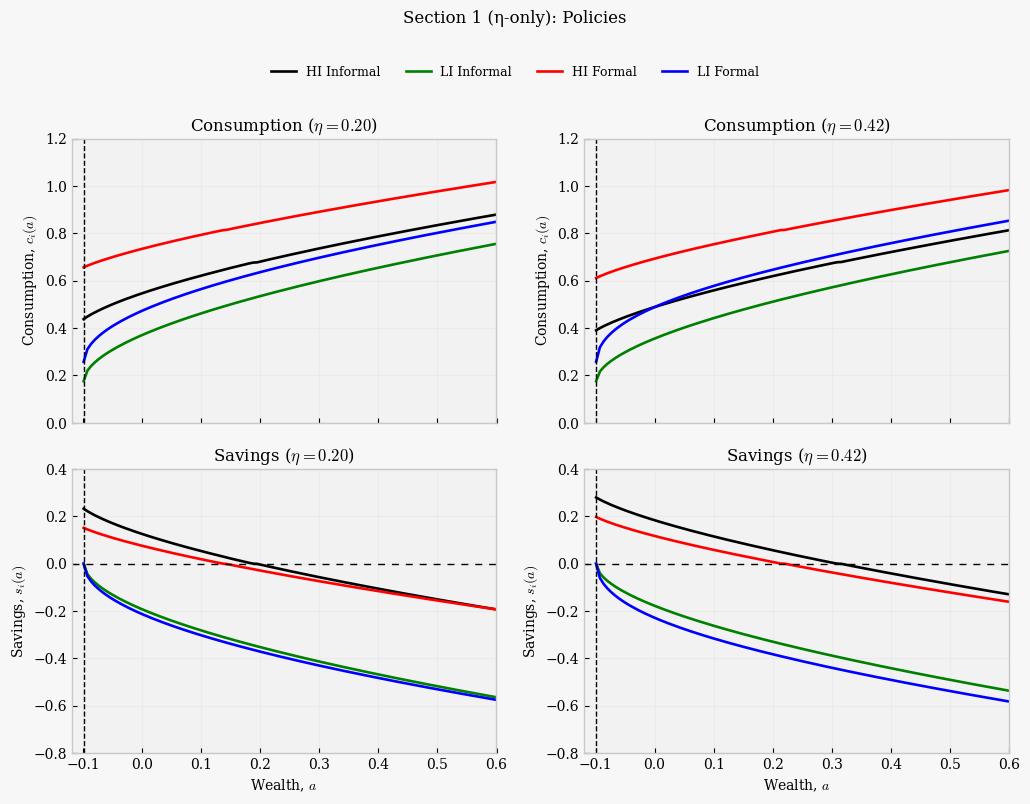

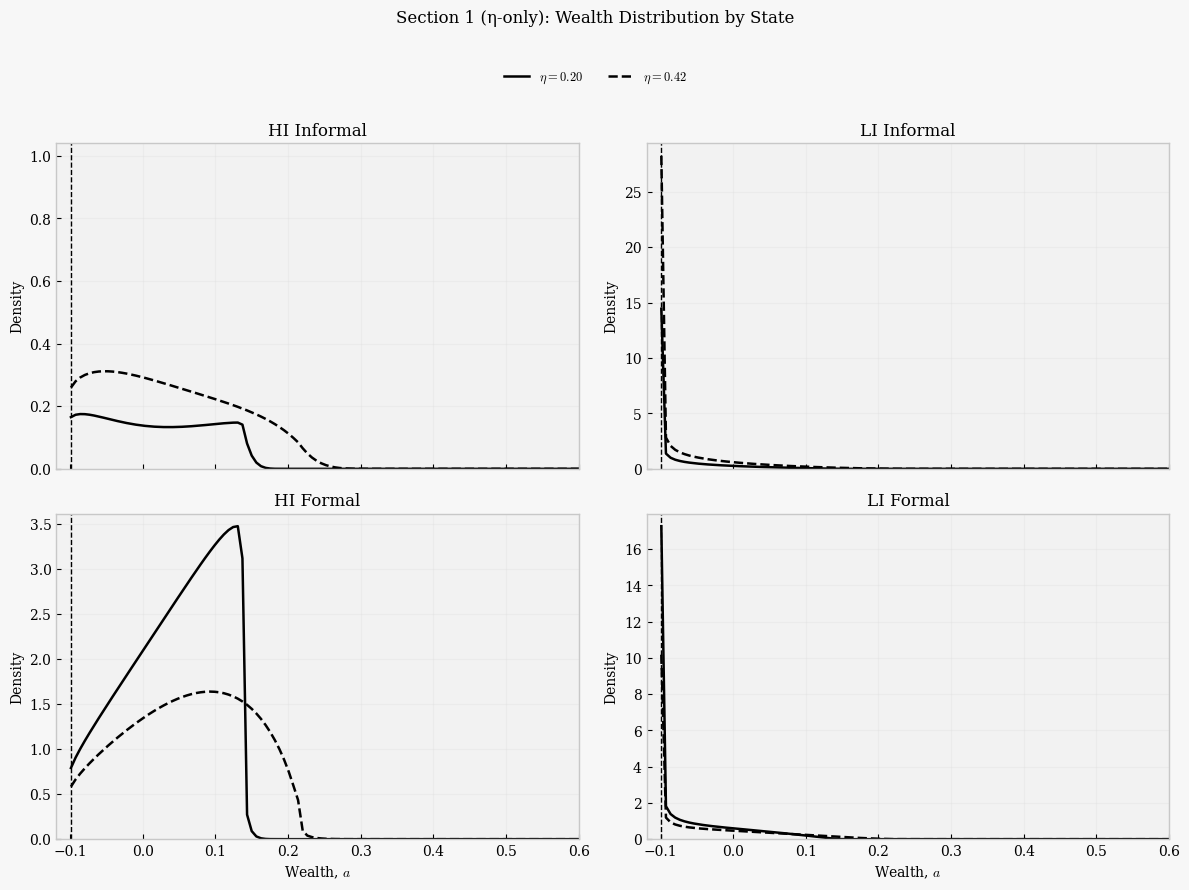


Section 1 (η-only): Bond and Interest Summary (scenario etas)
           Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal  Bond Supply Informal  Bond Demand Informal  Bond Supply Formal  Bond Demand Formal  Bond Decomp Residual
Section 1 (η-only) 0.20 0.022992 -0.000006        0.509942       0.200000     0.800000              0.013299              0.002306            0.022350            0.033337              0.000006
Section 1 (η-only) 0.42 0.018977  0.000006        0.556186       0.420000     0.580000              0.026336              0.007360            0.014422            0.033404             -0.000006


In [36]:
# §4.1: Common parameters across all 4 states
# Model state order: 1=HI Informal, 2=LI Informal, 3=HI Formal, 4=LI Formal
gamma_41 = np.array([0.15, 0.15, 0.15, 0.15])
tau_41   = np.array([tau_arg, tau_arg, tau_arg, tau_arg])
theta_41 = np.array([0.00, 0.00, 0.00, 0.00])

res_41, df_41 = run_section_thesis("Section 1 (η-only)", gamma_41, tau_41, theta_41, Lambda_dict, etas=(0.20, eta_arg), verbose=True)

## Section 4.2 -- Taxes: no tax for informal; formal taxed (keep eta set)
- State order: 1=HI Informal, 2=LI Informal, 3=HI Formal, 4=LI Formal
- gamma: [0.15, 0.15, 0.15, 0.15]
- tau: [0.00, 0.00, tau_arg, tau_arg_ms]
- theta: [0.00, 0.00, 0.00, 0.00]

[eta=0.20] iter 01: r=0.030000, S=+1.940418e-02
[eta=0.20] iter 02: r=0.015250, S=-5.416765e-02
[eta=0.20] iter 03: r=0.022625, S=-2.680618e-02
[eta=0.20] iter 04: r=0.026312, S=-6.998501e-03
[eta=0.20] iter 05: r=0.028156, S=+5.213609e-03
[eta=0.20] iter 06: r=0.027234, S=-1.102926e-03
[eta=0.20] iter 07: r=0.027695, S=+1.991055e-03
[eta=0.20] iter 08: r=0.027465, S=+4.175513e-04
[eta=0.20] iter 09: r=0.027350, S=-3.460408e-04
[eta=0.20] iter 10: r=0.027407, S=+2.942415e-05
[eta=0.20] iter 11: r=0.027378, S=-1.580538e-04
[eta=0.20] iter 12: r=0.027393, S=-6.457318e-05
[eta=0.20] iter 13: r=0.027400, S=-1.758199e-05
[eta=0.20] iter 14: r=0.027404, S=+5.920862e-06
[eta=0.20] Equilibrium r* = 0.027404
[§4.2 Taxes] eta=0.20 | r*=0.027404 | mean(a)=0.000006 | borrowers=0.511 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=+4.193474e-02
[eta=0.42] iter 02: r=0.015250, S=-3.122000e-02
[eta=0.42] iter 03: r=0.022625, S=-3.767352e-03
[eta=0.42] iter 04: r=0.026312, S=+1.5879

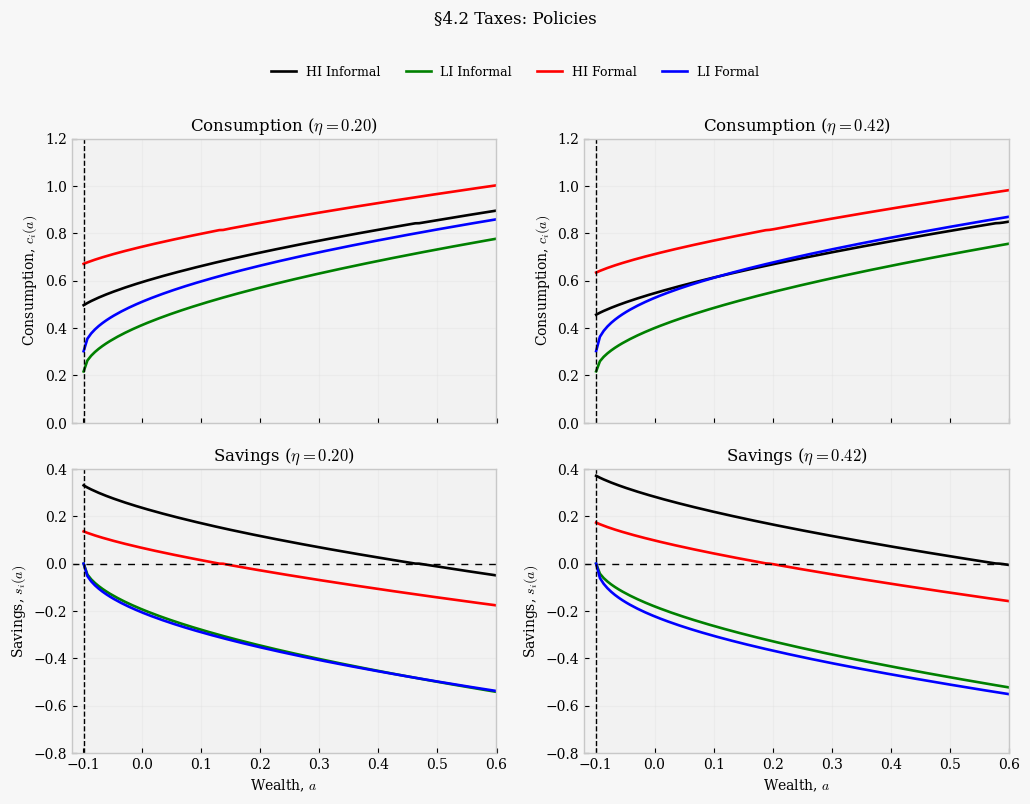

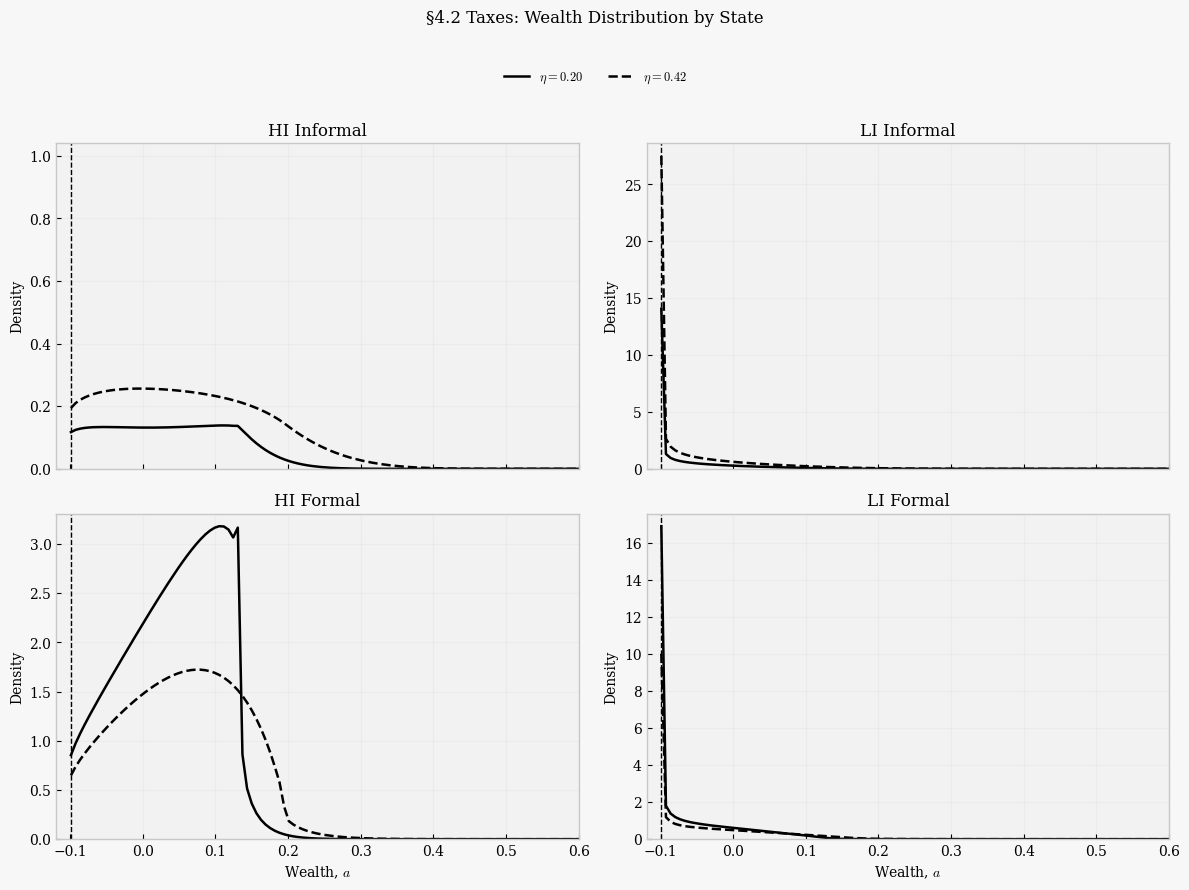


§4.2 Taxes: Bond and Interest Summary (scenario etas)
   Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal  Bond Supply Informal  Bond Demand Informal  Bond Supply Formal  Bond Demand Formal  Bond Decomp Residual
§4.2 Taxes 0.20 0.027404  0.000006        0.511368       0.200000     0.800000              0.012770              0.003226            0.022585            0.032135             -0.000006
§4.2 Taxes 0.42 0.023410 -0.000002        0.553034       0.420000     0.580000              0.025209              0.010279            0.014889            0.029817              0.000002


In [37]:
# §4.2: No tax for informal states, formal states taxed
gamma_42 = np.array([0.15, 0.15, 0.15, 0.15])
tau_42   = np.array([0.00, 0.00, tau_arg, tau_arg_ms])  # States 1,2 informal (no tax), States 3,4 formal (taxed)
theta_42 = np.array([0.00, 0.00, 0.00, 0.00])

res_42, df_42 = run_section_thesis("§4.2 Taxes", gamma_42, tau_42, theta_42, Lambda_dict, etas=(0.20, eta_arg), verbose=True)

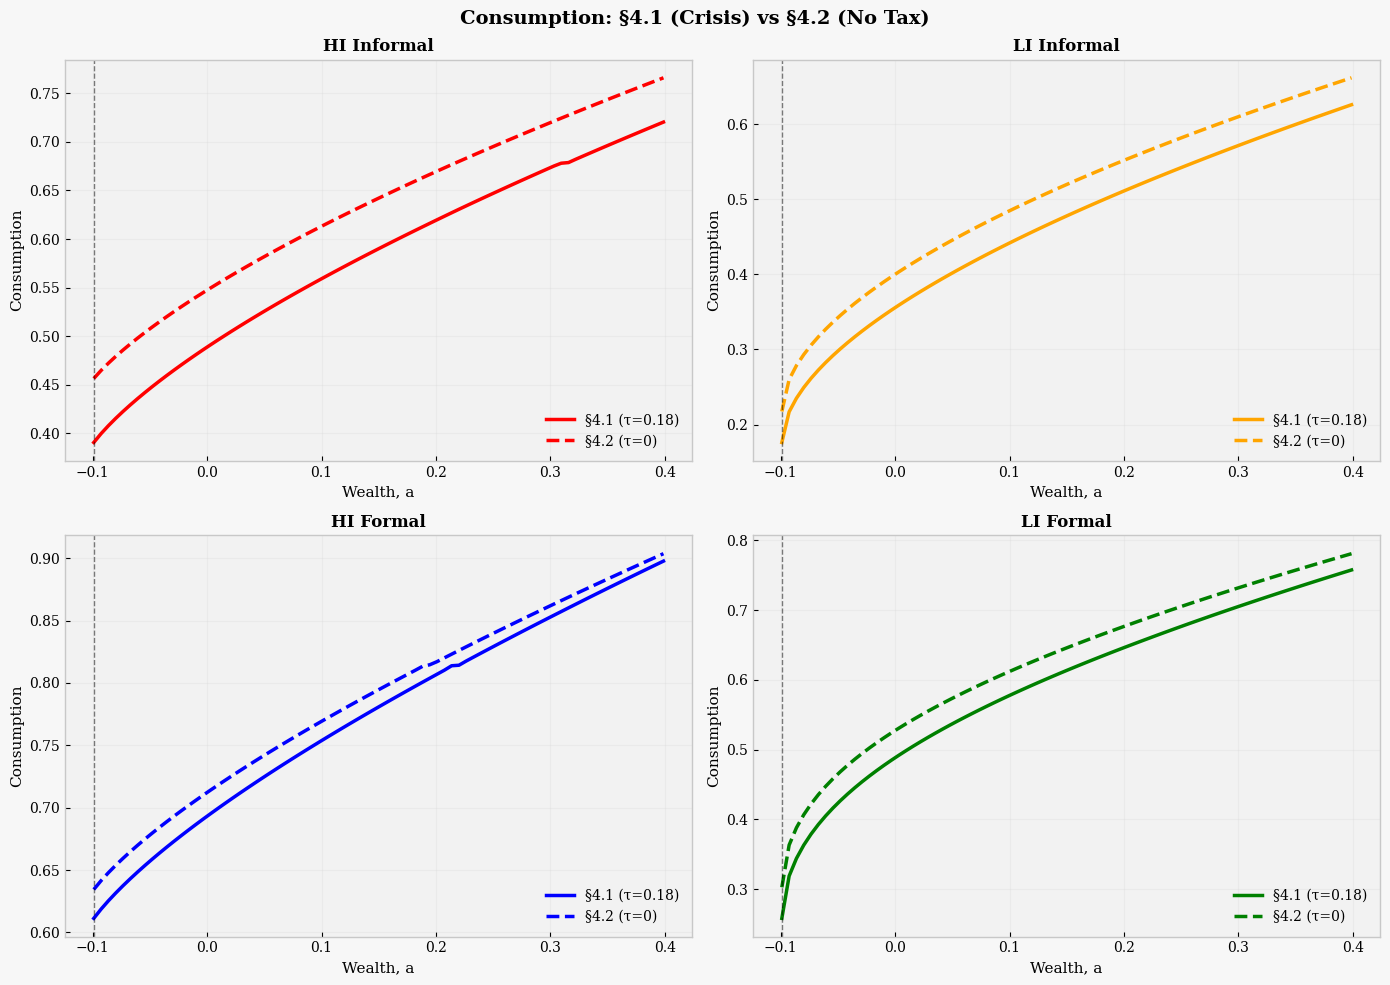

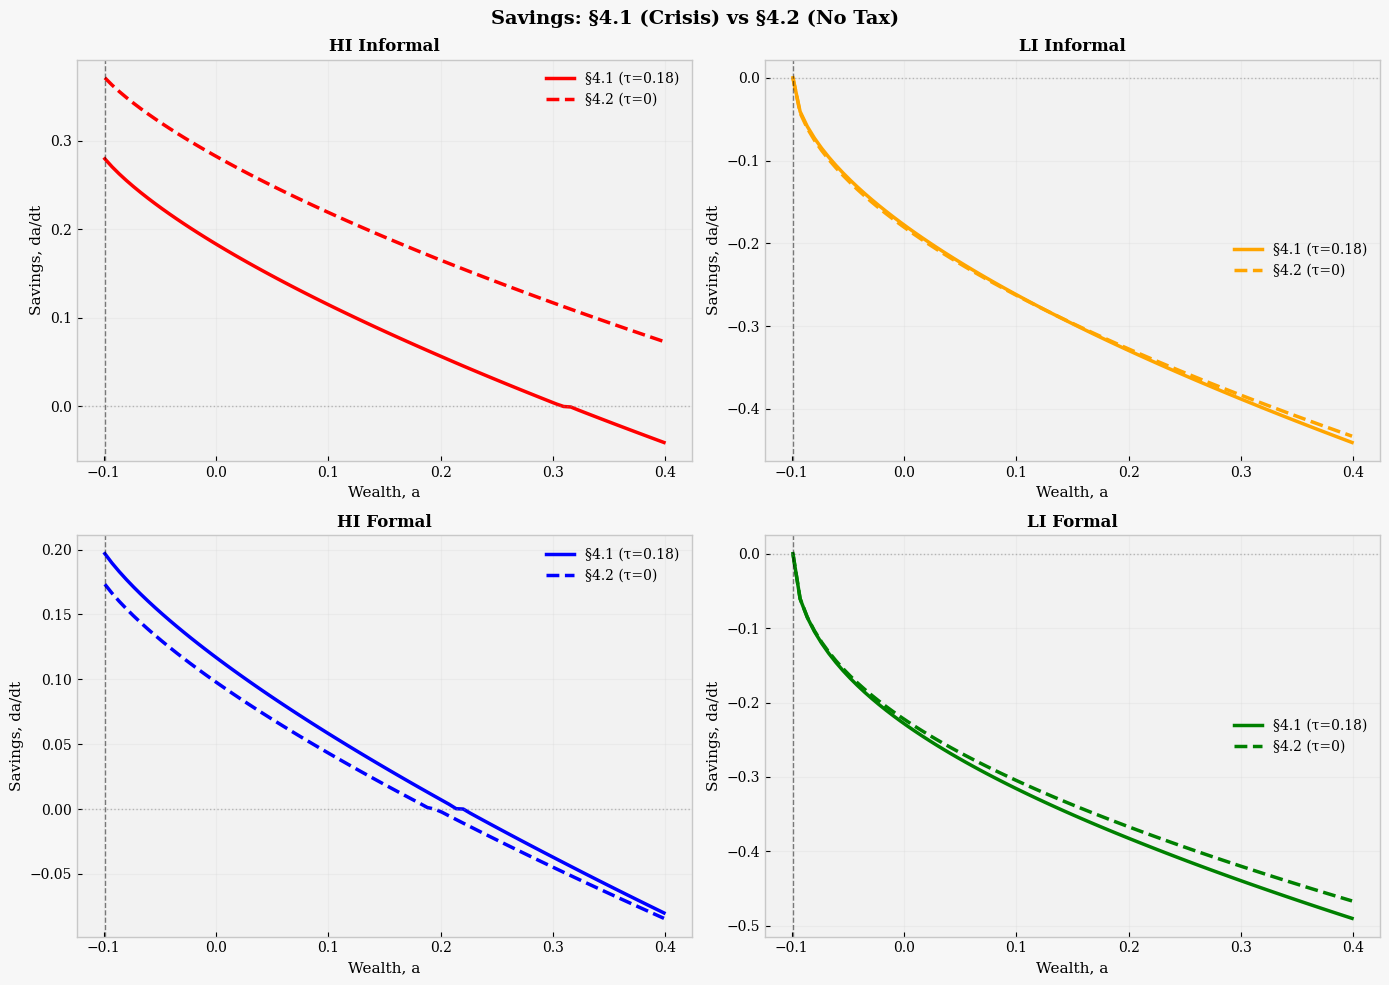


EQUILIBRIUM MOMENTS: §4.1 vs §4.2
       Metric     §4.1      §4.2   Δ (4.2-4.1)           % Δ
           r* 0.018977  0.023410  4.432922e-03  2.335931e+01
      Mean(a) 0.000006 -0.000002 -7.729955e-06 -1.396113e+02
    Borrowers 0.556186  0.553034 -3.151864e-03 -5.666928e-01
Mass Informal 0.420000  0.420000  1.276756e-15  3.039896e-13
  Mass Formal 0.580000  0.580000 -1.776357e-15 -3.062684e-13

POLICY FUNCTION DISTANCES: §4.1 vs §4.2
      State  Mean|Δc|  Max|Δc|  Mean|Δs|  Max|Δs|
HI Informal  0.038644 0.087188  0.185006 0.267013
LI Informal  0.037242 0.088086  0.072610 0.151993
  HI Formal  0.053417 0.118647  0.064020 0.140812
  LI Formal  0.044795 0.104401  0.090772 0.171523



In [38]:
# Comparison: §4.1 vs §4.2 at eta=eta_arg
import matplotlib.pyplot as plt
import numpy as np

# Extract results at eta=eta_arg
res_prev = res_41[eta_arg]  # §4.1
res_curr = res_42[eta_arg]  # §4.2

# State labels and colors
state_labels = ["HI Informal", "LI Informal", "HI Formal", "LI Formal"]
state_colors = ["red", "orange", "blue", "green"]

# Asset grid for plots
a_plot = base_params["a"][base_params["a"] <= 0.4]

# ===== CONSUMPTION COMPARISON =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, res_prev.c[:len(a_plot), j], color=color, linestyle='-', linewidth=2.5, label=f'§4.1 (τ=0.18)')
    ax.plot(a_plot, res_curr.c[:len(a_plot), j], color=color, linestyle='--', linewidth=2.5, label=f'§4.2 (τ=0)')
    ax.axvline(x=-0.099, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel(f'Consumption', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Consumption: §4.1 (Crisis) vs §4.2 (No Tax)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== SAVINGS COMPARISON =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, res_prev.adot[:len(a_plot), j], color=color, linestyle='-', linewidth=2.5, label=f'§4.1 (τ=0.18)')
    ax.plot(a_plot, res_curr.adot[:len(a_plot), j], color=color, linestyle='--', linewidth=2.5, label=f'§4.2 (τ=0)')
    ax.axvline(x=-0.099, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.axhline(y=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel(f'Savings, da/dt', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Savings: §4.1 (Crisis) vs §4.2 (No Tax)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== EQUILIBRIUM MOMENTS TABLE =====
import pandas as pd

metrics_prev = {
    'r*': res_prev.r_star,
    'Mean(a)': res_prev.mean_a,
    'Borrowers': res_prev.borrowers,
    'Mass Informal': res_prev.mass_inf,
    'Mass Formal': res_prev.mass_for,
}

metrics_curr = {
    'r*': res_curr.r_star,
    'Mean(a)': res_curr.mean_a,
    'Borrowers': res_curr.borrowers,
    'Mass Informal': res_curr.mass_inf,
    'Mass Formal': res_curr.mass_for,
}

table_data = []
for key in metrics_prev.keys():
    v_prev = metrics_prev[key]
    v_curr = metrics_curr[key]
    delta = v_curr - v_prev
    pct_delta = 100 * delta / abs(v_prev) if v_prev != 0 else 0
    table_data.append({
        'Metric': key,
        '§4.1': v_prev,
        '§4.2': v_curr,
        'Δ (4.2-4.1)': delta,
        '% Δ': pct_delta,
    })

df_moments = pd.DataFrame(table_data)
print("\n" + "="*80)
print("EQUILIBRIUM MOMENTS: §4.1 vs §4.2")
print("="*80)
print(df_moments.to_string(index=False))
print("="*80 + "\n")

# ===== POLICY FUNCTION DISTANCE TABLE =====
table_dist = []
for j, label in enumerate(state_labels):
    mean_dc = np.mean(np.abs(res_curr.c[:, j] - res_prev.c[:, j]))
    max_dc = np.max(np.abs(res_curr.c[:, j] - res_prev.c[:, j]))
    mean_ds = np.mean(np.abs(res_curr.adot[:, j] - res_prev.adot[:, j]))
    max_ds = np.max(np.abs(res_curr.adot[:, j] - res_prev.adot[:, j]))
    table_dist.append({
        'State': label,
        'Mean|Δc|': mean_dc,
        'Max|Δc|': max_dc,
        'Mean|Δs|': mean_ds,
        'Max|Δs|': max_ds,
    })

df_dist = pd.DataFrame(table_dist)
print("="*80)
print("POLICY FUNCTION DISTANCES: §4.1 vs §4.2")
print("="*80)
print(df_dist.to_string(index=False))
print("="*80 + "\n")

## Section 4.3 -- Borrowing premium for informal borrowers (when a < 0)
- State order: 1=HI Informal, 2=LI Informal, 3=HI Formal, 4=LI Formal
- gamma: [0.15, 0.15, 0.15, 0.15]
- tau: [0.00, 0.00, tau_arg, tau_arg_ms]
- theta: [0.02, 0.02, 0.00, 0.00]

[eta=0.20] iter 01: r=0.030000, S=+2.620534e-02
[eta=0.20] iter 02: r=0.015250, S=-5.057996e-02
[eta=0.20] iter 03: r=0.022625, S=-2.206311e-02
[eta=0.20] iter 04: r=0.026312, S=-1.289766e-03
[eta=0.20] iter 05: r=0.028156, S=+1.141923e-02
[eta=0.20] iter 06: r=0.027234, S=+4.828735e-03
[eta=0.20] iter 07: r=0.026773, S=+1.709366e-03
[eta=0.20] iter 08: r=0.026543, S=+1.874911e-04
[eta=0.20] iter 09: r=0.026428, S=-5.615499e-04
[eta=0.20] iter 10: r=0.026485, S=-1.986633e-04
[eta=0.20] iter 11: r=0.026514, S=-1.227068e-05
[eta=0.20] iter 12: r=0.026529, S=+8.819124e-05
[eta=0.20] iter 13: r=0.026521, S=+3.842116e-05
[eta=0.20] iter 14: r=0.026518, S=+1.333280e-05
[eta=0.20] iter 15: r=0.026516, S=+7.685698e-07
[eta=0.20] Equilibrium r* = 0.026516
[§4.3 Premium] eta=0.20 | r*=0.026516 | mean(a)=0.000001 | borrowers=0.508 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=+5.438673e-02
[eta=0.42] iter 02: r=0.015250, S=-2.450563e-02
[eta=0.42] iter 03: r=0.022625, S=+5.29

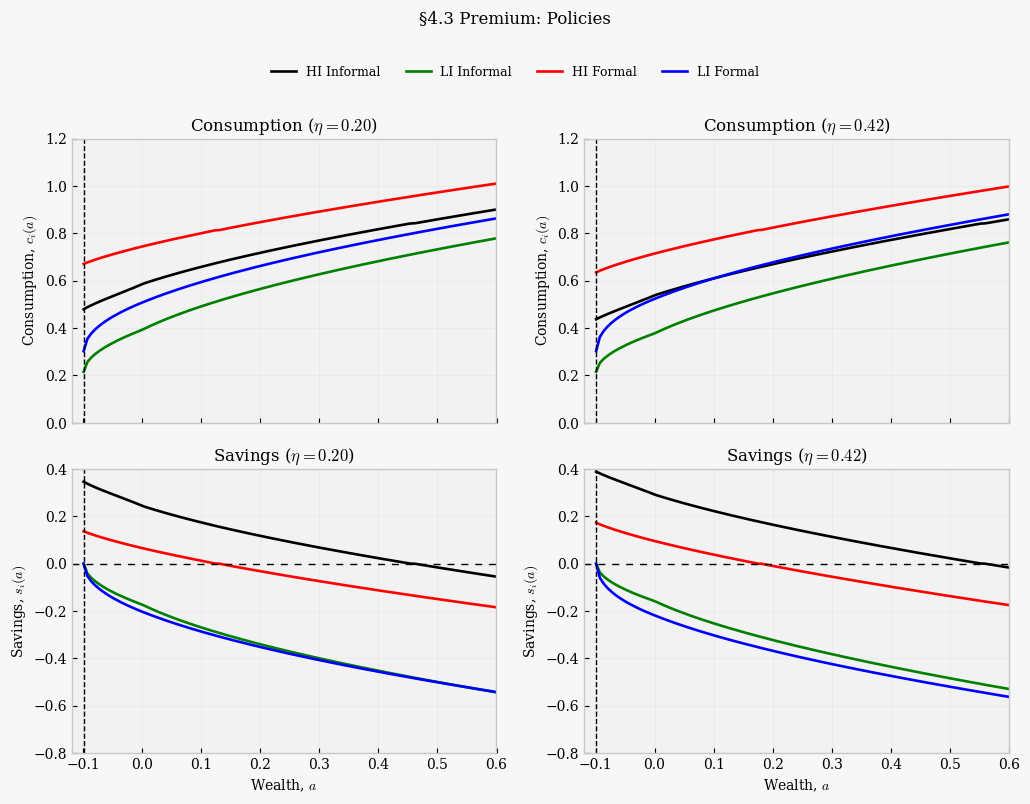

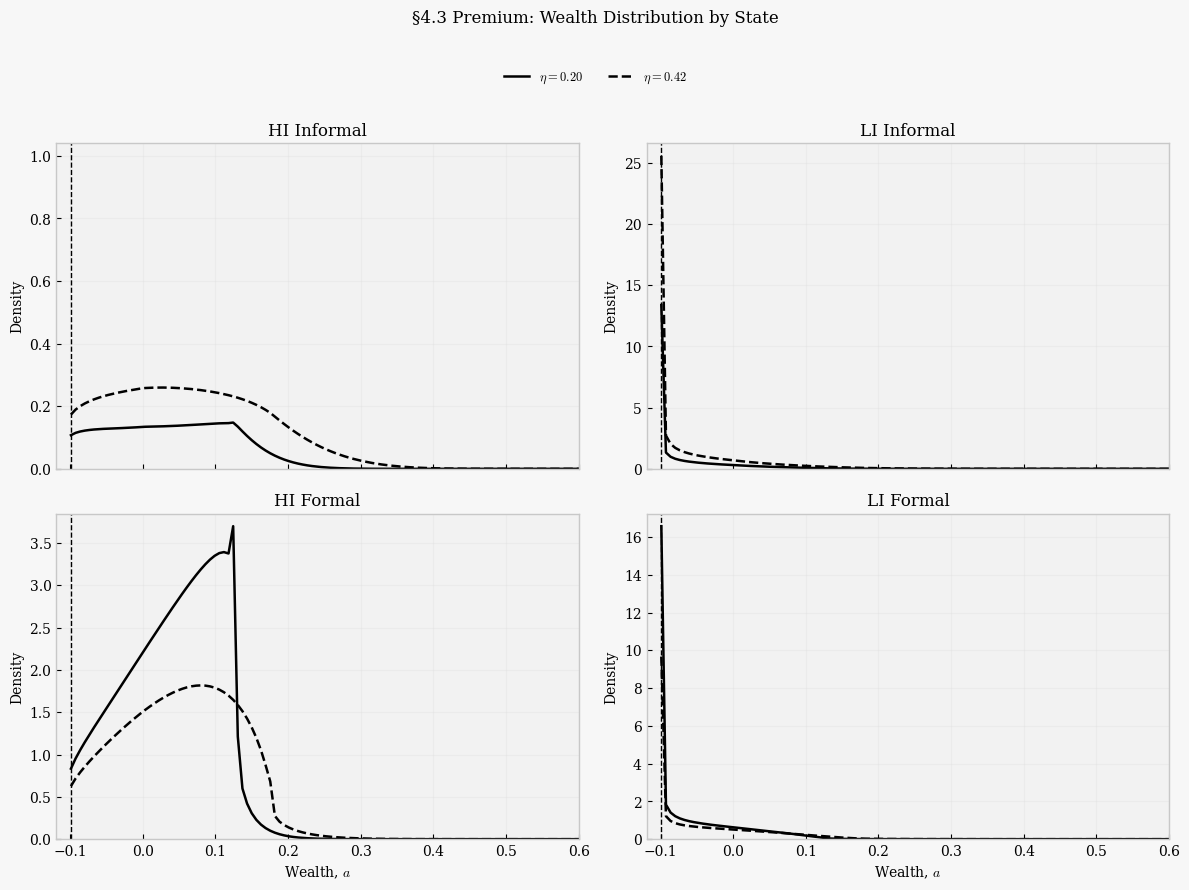


§4.3 Premium: Bond and Interest Summary (scenario etas)
     Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal  Bond Supply Informal  Bond Demand Informal  Bond Supply Formal  Bond Demand Formal  Bond Decomp Residual
§4.3 Premium 0.20 0.026516  0.000001        0.508094       0.200000     0.800000              0.012448              0.003295            0.022368            0.031522             -0.000001
§4.3 Premium 0.42 0.021537 -0.000004        0.547815       0.420000     0.580000              0.024316              0.010485            0.014721            0.028548              0.000004


In [39]:
# §4.3: Borrowing premium for informal borrowers
gamma_43 = np.array([0.15, 0.15, 0.15, 0.15])
tau_43   = np.array([0.00, 0.00, tau_arg, tau_arg_ms])  # Informal no tax, formal taxed
theta_43 = np.array([0.02, 0.02, 0.00, 0.00])  # Premium for informal borrowers

res_43, df_43 = run_section_thesis("§4.3 Premium", gamma_43, tau_43, theta_43, Lambda_dict, etas=(0.20, eta_arg), verbose=True)

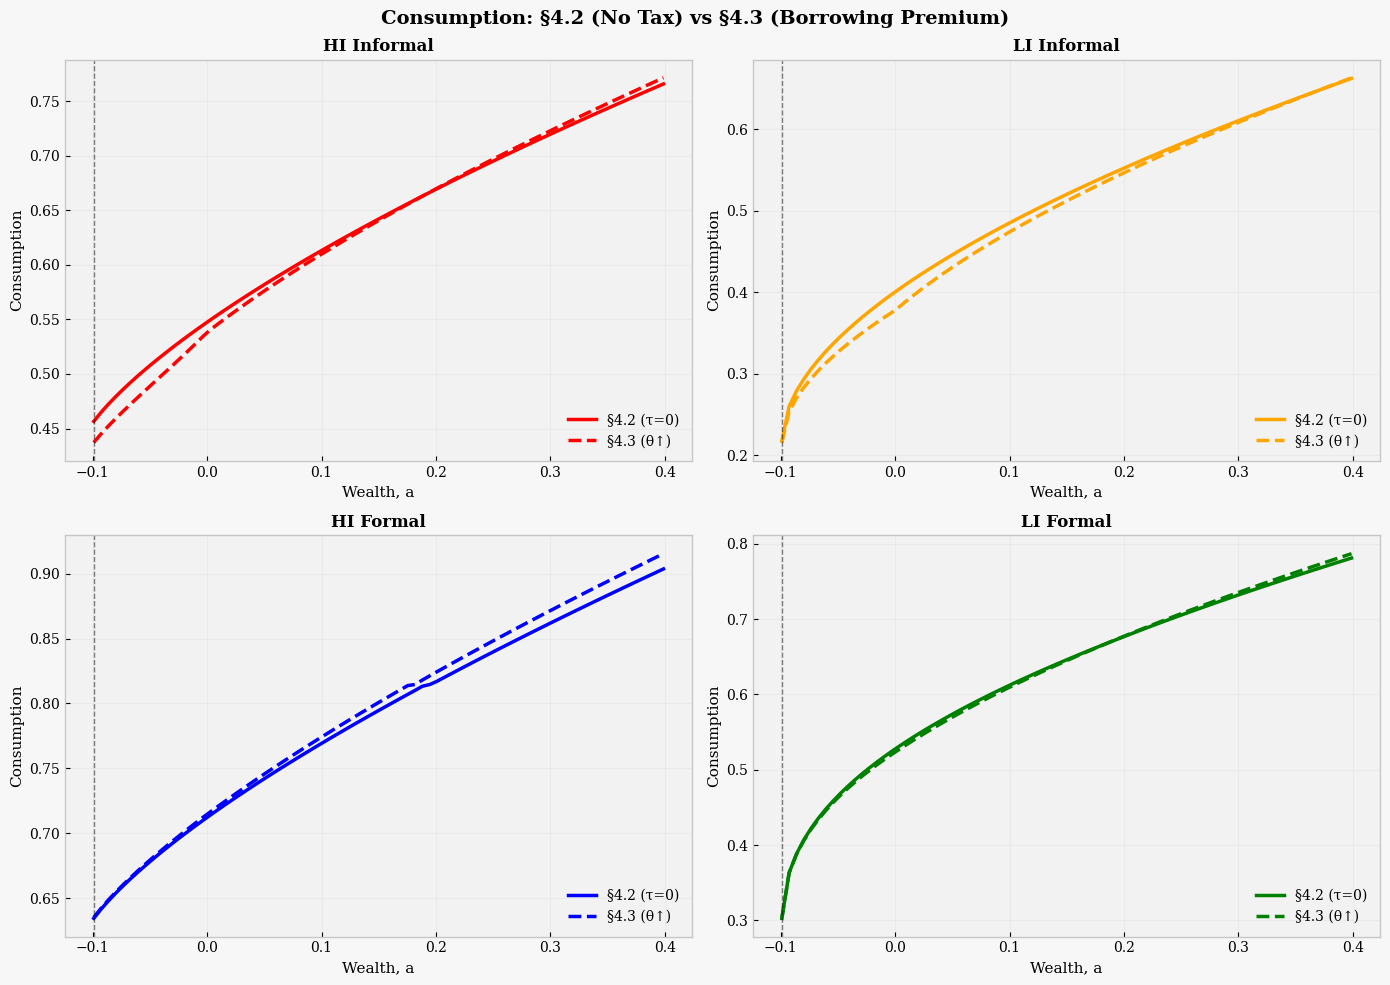

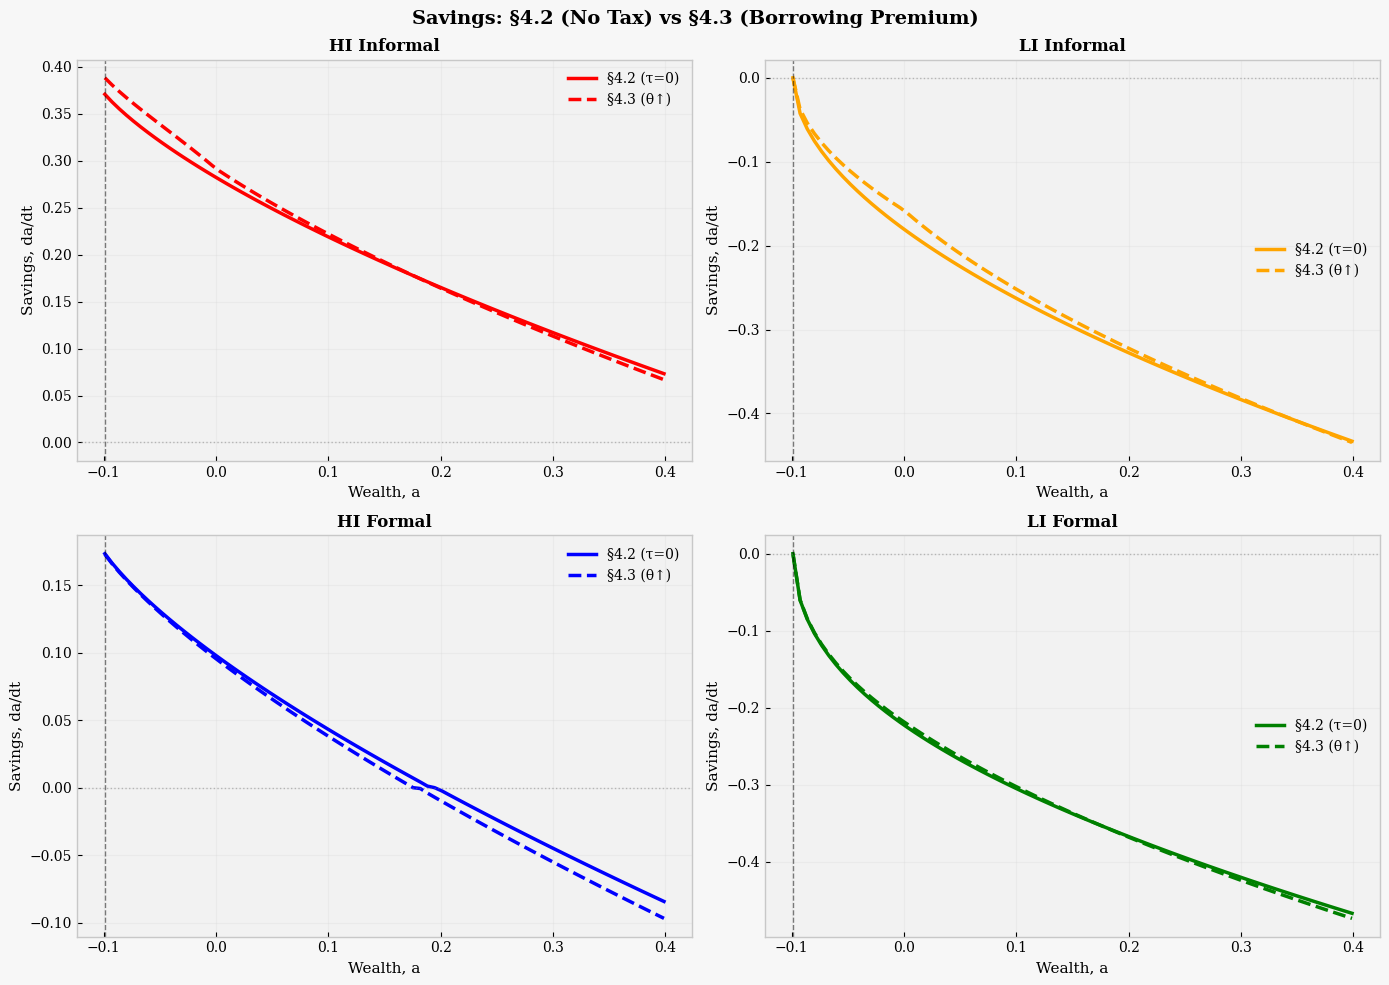


EQUILIBRIUM MOMENTS: §4.2 vs §4.3
       Metric      §4.2      §4.3   Δ (4.3-4.2)           % Δ
           r*  0.023410  0.021537 -1.872559e-03 -7.998957e+00
      Mean(a) -0.000002 -0.000004 -1.978367e-06 -9.020522e+01
    Borrowers  0.553034  0.547815 -5.218423e-03 -9.435993e-01
Mass Informal  0.420000  0.420000 -3.275158e-15 -7.797995e-13
  Mass Formal  0.580000  0.580000  3.330669e-15  5.742533e-13

POLICY FUNCTION DISTANCES: §4.2 vs §4.3
      State  Mean|Δc|  Max|Δc|  Mean|Δs|  Max|Δs|
HI Informal  0.037778 0.071895  0.042338 0.081258
LI Informal  0.034962 0.068819  0.039487 0.078182
  HI Formal  0.042467 0.076788  0.047055 0.086151
  LI Formal  0.038337 0.073034  0.042917 0.082397



In [40]:
# Comparison: §4.2 vs §4.3 at eta=eta_arg
import matplotlib.pyplot as plt
import numpy as np

# Extract results at eta=eta_arg
res_prev = res_42[eta_arg]  # §4.2
res_curr = res_43[eta_arg]  # §4.3

# State labels and colors
state_labels = ["HI Informal", "LI Informal", "HI Formal", "LI Formal"]
state_colors = ["red", "orange", "blue", "green"]

# Asset grid for plots
a_plot = base_params["a"][base_params["a"] <= 0.4]

# ===== CONSUMPTION COMPARISON =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, res_prev.c[:len(a_plot), j], color=color, linestyle='-', linewidth=2.5, label=f'§4.2 (τ=0)')
    ax.plot(a_plot, res_curr.c[:len(a_plot), j], color=color, linestyle='--', linewidth=2.5, label=f'§4.3 (θ↑)')
    ax.axvline(x=-0.099, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel(f'Consumption', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Consumption: §4.2 (No Tax) vs §4.3 (Borrowing Premium)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== SAVINGS COMPARISON =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, res_prev.adot[:len(a_plot), j], color=color, linestyle='-', linewidth=2.5, label=f'§4.2 (τ=0)')
    ax.plot(a_plot, res_curr.adot[:len(a_plot), j], color=color, linestyle='--', linewidth=2.5, label=f'§4.3 (θ↑)')
    ax.axvline(x=-0.099, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.axhline(y=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel(f'Savings, da/dt', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Savings: §4.2 (No Tax) vs §4.3 (Borrowing Premium)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== EQUILIBRIUM MOMENTS TABLE =====
import pandas as pd

metrics_prev = {
    'r*': res_prev.r_star,
    'Mean(a)': res_prev.mean_a,
    'Borrowers': res_prev.borrowers,
    'Mass Informal': res_prev.mass_inf,
    'Mass Formal': res_prev.mass_for,
}

metrics_curr = {
    'r*': res_curr.r_star,
    'Mean(a)': res_curr.mean_a,
    'Borrowers': res_curr.borrowers,
    'Mass Informal': res_curr.mass_inf,
    'Mass Formal': res_curr.mass_for,
}

table_data = []
for key in metrics_prev.keys():
    v_prev = metrics_prev[key]
    v_curr = metrics_curr[key]
    delta = v_curr - v_prev
    pct_delta = 100 * delta / abs(v_prev) if v_prev != 0 else 0
    table_data.append({
        'Metric': key,
        '§4.2': v_prev,
        '§4.3': v_curr,
        'Δ (4.3-4.2)': delta,
        '% Δ': pct_delta,
    })

df_moments = pd.DataFrame(table_data)
print("\n" + "="*80)
print("EQUILIBRIUM MOMENTS: §4.2 vs §4.3")
print("="*80)
print(df_moments.to_string(index=False))
print("="*80 + "\n")

# ===== POLICY FUNCTION DISTANCE TABLE =====
table_dist = []
for j, label in enumerate(state_labels):
    mean_dc = np.mean(np.abs(res_curr.c[:, j] - res_prev.c[:, j]))
    max_dc = np.max(np.abs(res_curr.c[:, j] - res_prev.c[:, j]))
    mean_ds = np.mean(np.abs(res_curr.adot[:, j] - res_prev.adot[:, j]))
    max_ds = np.max(np.abs(res_curr.adot[:, j] - res_prev.adot[:, j]))
    table_dist.append({
        'State': label,
        'Mean|Δc|': mean_dc,
        'Max|Δc|': max_dc,
        'Mean|Δs|': mean_ds,
        'Max|Δs|': max_ds,
    })

df_dist = pd.DataFrame(table_dist)
print("="*80)
print("POLICY FUNCTION DISTANCES: §4.2 vs §4.3")
print("="*80)
print(df_dist.to_string(index=False))
print("="*80 + "\n")

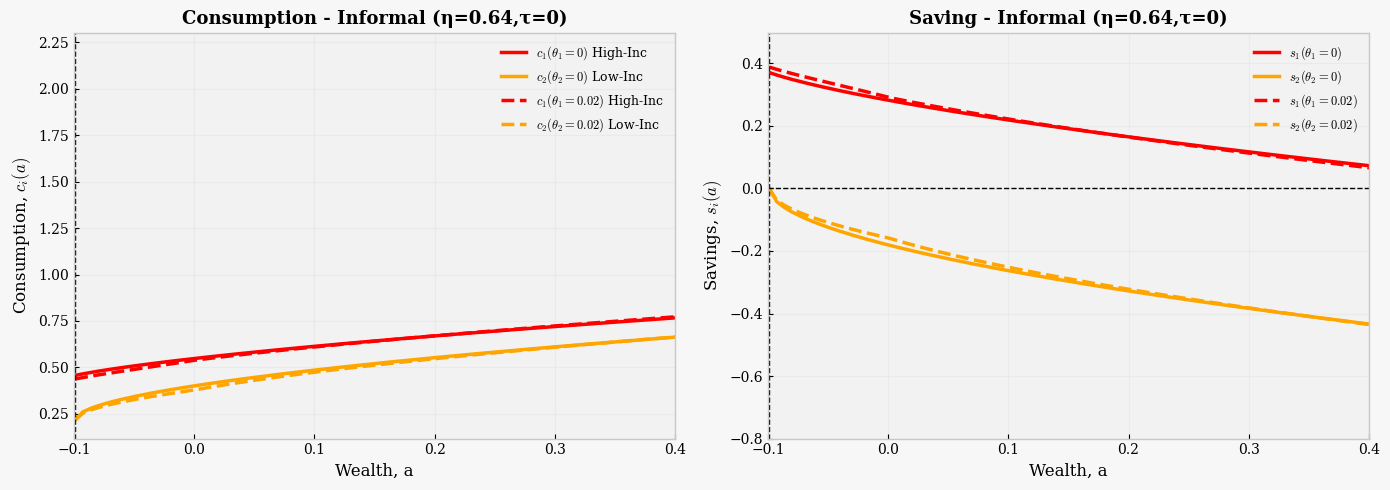

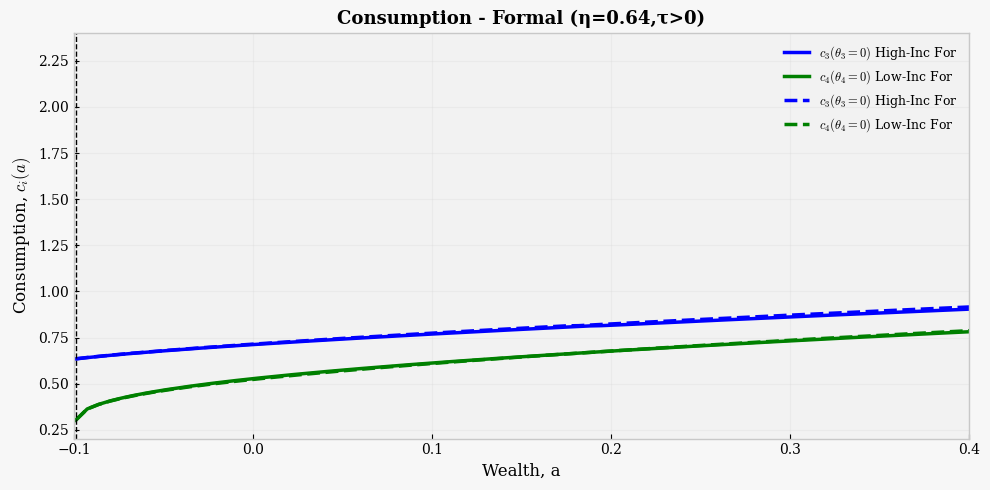

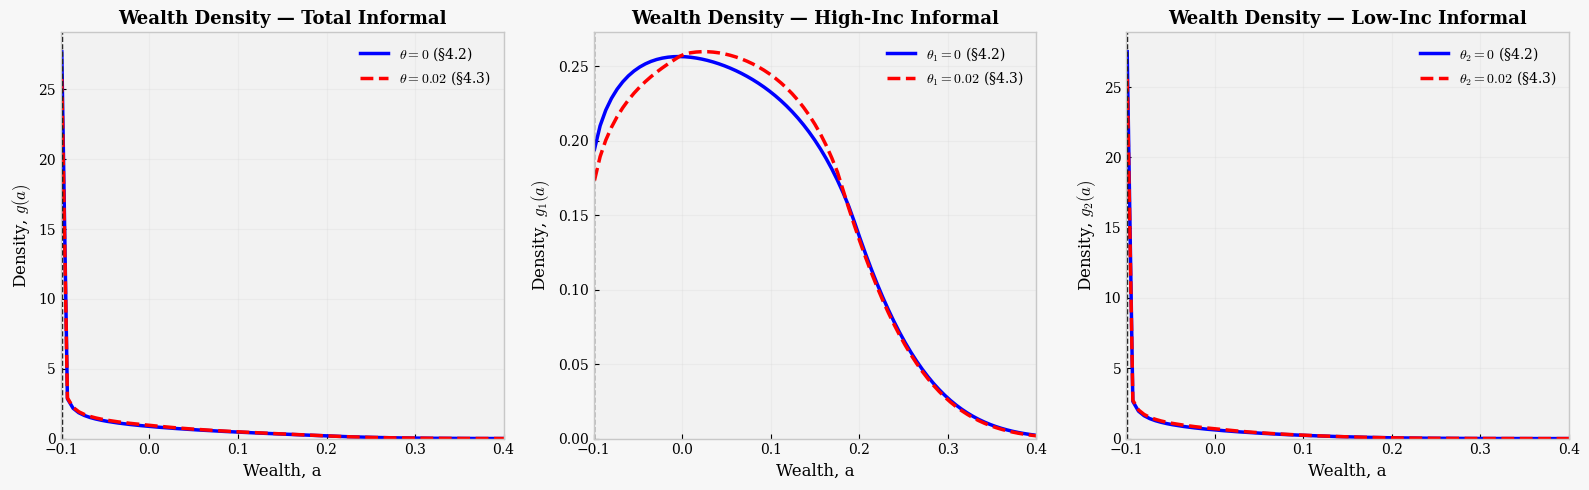

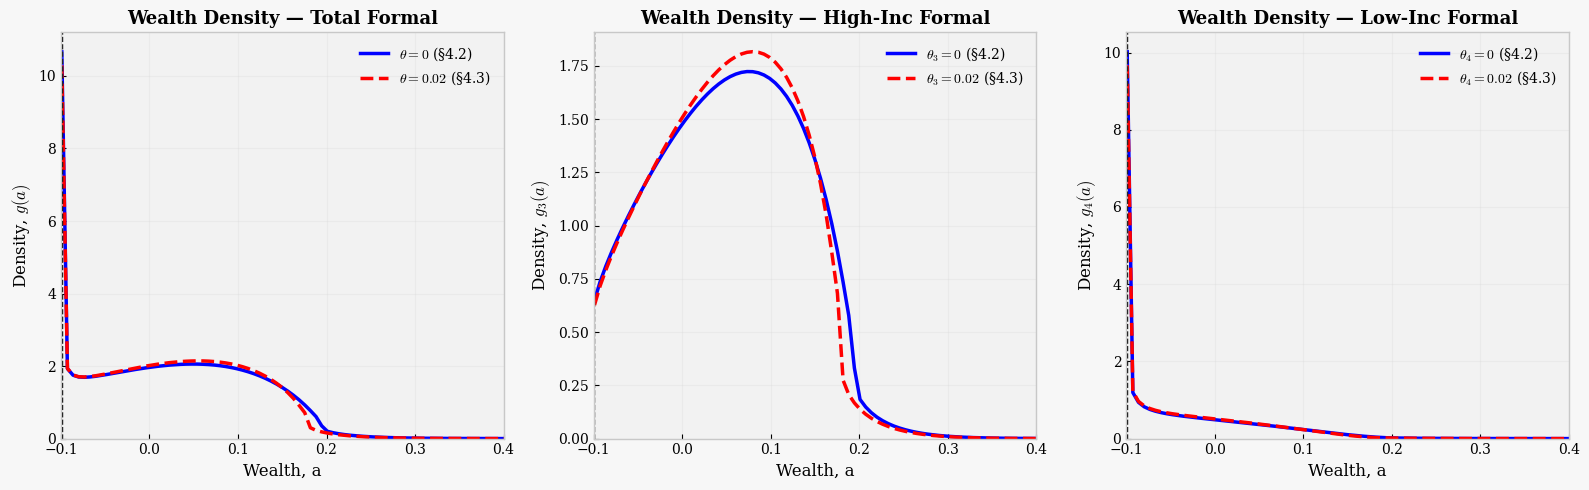

In [41]:
# Comparison plot: §4.2 vs §4.3 for η=0.64 (effect of borrowing premium) - INFORMAL
eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]
c_42 = res_42[eta_focus].c
c_43 = res_43[eta_focus].c
adot_42 = res_42[eta_focus].adot
adot_43 = res_43[eta_focus].adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison (informal states)
ax1.plot(a_plot, c_42[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$c_1(\theta_1=0)$ High-Inc')
ax1.plot(a_plot, c_42[:,1], color='orange', linestyle='-', linewidth=2.5, label=r'$c_2(\theta_2=0)$ Low-Inc')
ax1.plot(a_plot, c_43[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$c_1(\theta_1=0.02)$ High-Inc')
ax1.plot(a_plot, c_43[:,1], color='orange', linestyle='--', linewidth=2.5, label=r'$c_2(\theta_2=0.02)$ Low-Inc')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title('Consumption - Informal (η=0.64,τ=0)', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=9)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_42[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$s_1(\theta_1=0)$')
ax2.plot(a_plot, adot_42[:,1], color='orange', linestyle='-', linewidth=2.5, label=r'$s_2(\theta_2=0)$')
ax2.plot(a_plot, adot_43[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$s_1(\theta_1=0.02)$')
ax2.plot(a_plot, adot_43[:,1], color='orange', linestyle='--', linewidth=2.5, label=r'$s_2(\theta_2=0.02)$')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_ylim(bottom=-0.8)
ax2.set_title('Saving - Informal (η=0.64,τ=0)', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.2 vs §4.3 for η=0.64 - INFORMAL
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.plot(a_plot, c_42[:,2], color='blue', linestyle='-', linewidth=2.5, label=r'$c_3(\theta_3=0)$ High-Inc For')
ax.plot(a_plot, c_42[:,3], color='green', linestyle='-', linewidth=2.5, label=r'$c_4(\theta_4=0)$ Low-Inc For')
ax.plot(a_plot, c_43[:,2], color='blue', linestyle='--', linewidth=2.5, label=r'$c_3(\theta_3=0)$ High-Inc For')
ax.plot(a_plot, c_43[:,3], color='green', linestyle='--', linewidth=2.5, label=r'$c_4(\theta_4=0)$ Low-Inc For')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_title('Consumption - Formal (η=0.64,τ>0)', fontsize=13, fontweight='bold')
ax.legend(loc='best', fontsize=9)
ax.grid(alpha=0.3)



plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.2 vs §4.3 for η=0.64
g_42 = res_42[eta_focus].g
g_43 = res_43[eta_focus].g
g_total_inf_42 = g_42[:,0] + g_42[:,1]
g_total_inf_43 = g_43[:,0] + g_43[:,1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total informal
ax = axes[0]
ax.plot(a_plot, g_total_inf_42, color='blue', linestyle='-', linewidth=2.5, label=r'$\theta=0$ (§4.2)')
ax.plot(a_plot, g_total_inf_43, color='red', linestyle='--', linewidth=2.5, label=r'$\theta=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Informal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: High-income informal
ax = axes[1]
ax.plot(a_plot, g_42[:,0], color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_1=0$ (§4.2)')
ax.plot(a_plot, g_43[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$\theta_1=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_1(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — High-Inc Informal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)


# Panel 3: Low-income informal
ax = axes[2]
ax.plot(a_plot, g_42[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_2=0$ (§4.2)')
ax.plot(a_plot, g_43[:,1], color='red', linestyle='--', linewidth=2.5, label=r'$\theta_2=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_2(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Low-Inc Informal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.2 vs §4.3 for η=0.64 - FORMAL agents
g_total_for_42 = g_42[:,2] + g_42[:,3]
g_total_for_43 = g_43[:,2] + g_43[:,3]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total formal
ax = axes[0]
ax.plot(a_plot, g_total_for_42, color='blue', linestyle='-', linewidth=2.5, label=r'$\theta=0$ (§4.2)')
ax.plot(a_plot, g_total_for_43, color='red', linestyle='--', linewidth=2.5, label=r'$\theta=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Formal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: High-income formal
ax = axes[1]
ax.plot(a_plot, g_42[:,2], color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_3=0$ (§4.2)')
ax.plot(a_plot, g_43[:,2], color='red', linestyle='--', linewidth=2.5, label=r'$\theta_3=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_3(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — High-Inc Formal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Low-income formal
ax = axes[2]
ax.plot(a_plot, g_42[:,3], color='blue', linestyle='-', linewidth=2.5, label=r'$\theta_4=0$ (§4.2)')
ax.plot(a_plot, g_43[:,3], color='red', linestyle='--', linewidth=2.5, label=r'$\theta_4=0.02$ (§4.3)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_4(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Low-Inc Formal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Section 4.4 -- Preference heterogeneity (higher risk aversion for informal states)
- State order: 1=HI Informal, 2=LI Informal, 3=HI Formal, 4=LI Formal
- gamma: [0.30, 0.30, 0.15, 0.15]
- tau: [0.00, 0.00, tau_arg, tau_arg_ms]
- theta: [0.02, 0.02, 0.00, 0.00]

[eta=0.20] iter 01: r=0.030000, S=+1.805241e-01
[eta=0.20] iter 02: r=0.015250, S=+2.954155e-02
[eta=0.20] iter 03: r=0.007875, S=-1.024315e-02
[eta=0.20] iter 04: r=0.011562, S=+7.830404e-03
[eta=0.20] iter 05: r=0.009719, S=-1.592996e-03
[eta=0.20] iter 06: r=0.010641, S=+2.928342e-03
[eta=0.20] iter 07: r=0.010180, S=+6.719229e-04
[eta=0.20] iter 08: r=0.009949, S=-5.135408e-04
[eta=0.20] iter 09: r=0.010064, S=+1.335068e-05
[eta=0.20] iter 10: r=0.010007, S=-2.511080e-04
[eta=0.20] iter 11: r=0.010036, S=-1.195331e-04
[eta=0.20] iter 12: r=0.010050, S=-5.323641e-05
[eta=0.20] iter 13: r=0.010057, S=-1.994674e-05
[eta=0.20] iter 14: r=0.010061, S=-3.264295e-06
[eta=0.20] Equilibrium r* = 0.010061
[Section 2 (Full calibration)] eta=0.20 | r*=0.010061 | mean(a)=-0.000003 | borrowers=0.482 | masses (inf,for)=(0.200,0.800)
[eta=0.42] iter 01: r=0.030000, S=+2.976621e-01
[eta=0.42] iter 02: r=0.015250, S=+1.162599e-01
[eta=0.42] iter 03: r=0.007875, S=+6.664810e-02
[eta=0.42] iter 04: r=

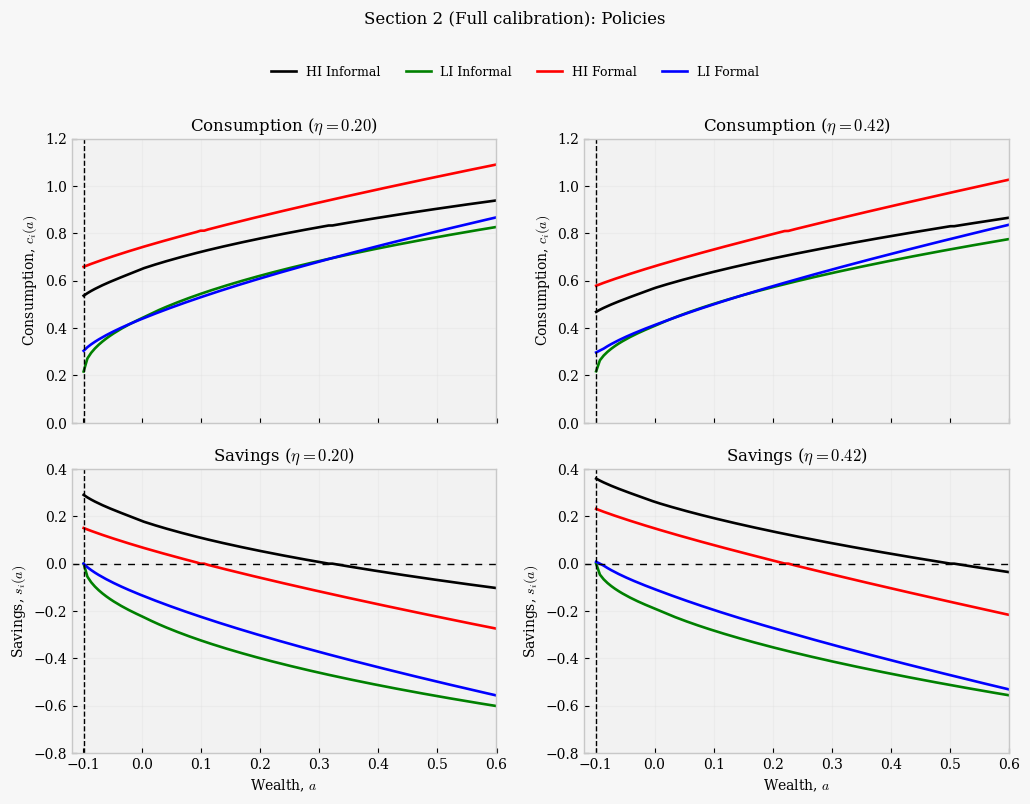

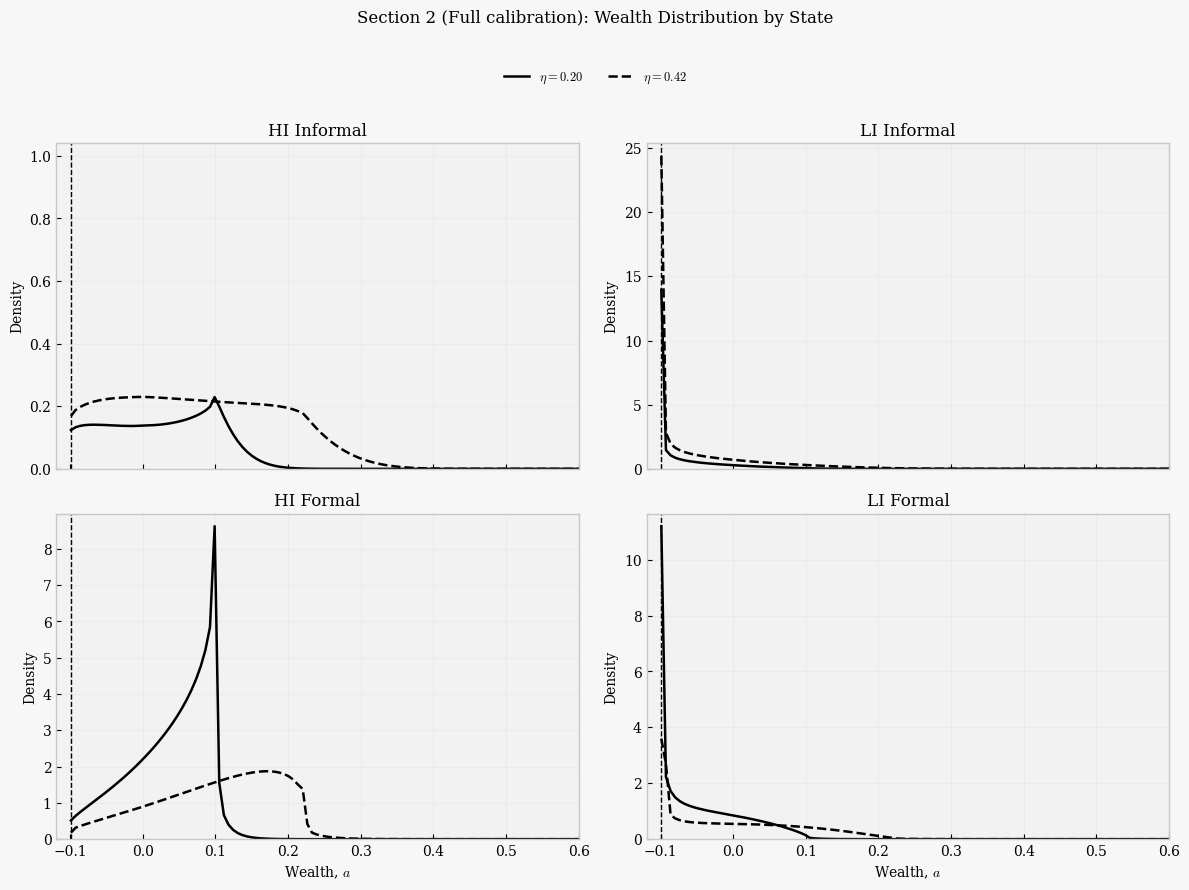


Section 2 (Full calibration): Bond and Interest Summary (scenario etas)
                     Section  eta       r*   Mean(a)  Borrowers Mass  Mass Informal  Mass Formal  Bond Supply Informal  Bond Demand Informal  Bond Supply Formal  Bond Demand Formal  Bond Decomp Residual
Section 2 (Full calibration) 0.20 0.010061 -0.000003        0.481870       0.200000     0.800000              0.013023              0.002422            0.018840            0.029437              0.000003
Section 2 (Full calibration) 0.42 0.000500  0.030208        0.449436       0.420000     0.580000              0.023386              0.012519            0.008917            0.049992             -0.030208


In [42]:
# §4.4: Preference heterogeneity - higher risk aversion for informal
gamma_44 = np.array([0.30, 0.30, 0.15, 0.15])  # Higher γ for informal states
tau_44   = np.array([0.00, 0.00, tau_arg, tau_arg_ms])
theta_44 = np.array([0.02, 0.02, 0.00, 0.00])

res_44, df_44 = run_section_thesis("Section 2 (Full calibration)", gamma_44, tau_44, theta_44, Lambda_dict, etas=(0.20, eta_arg), verbose=True)

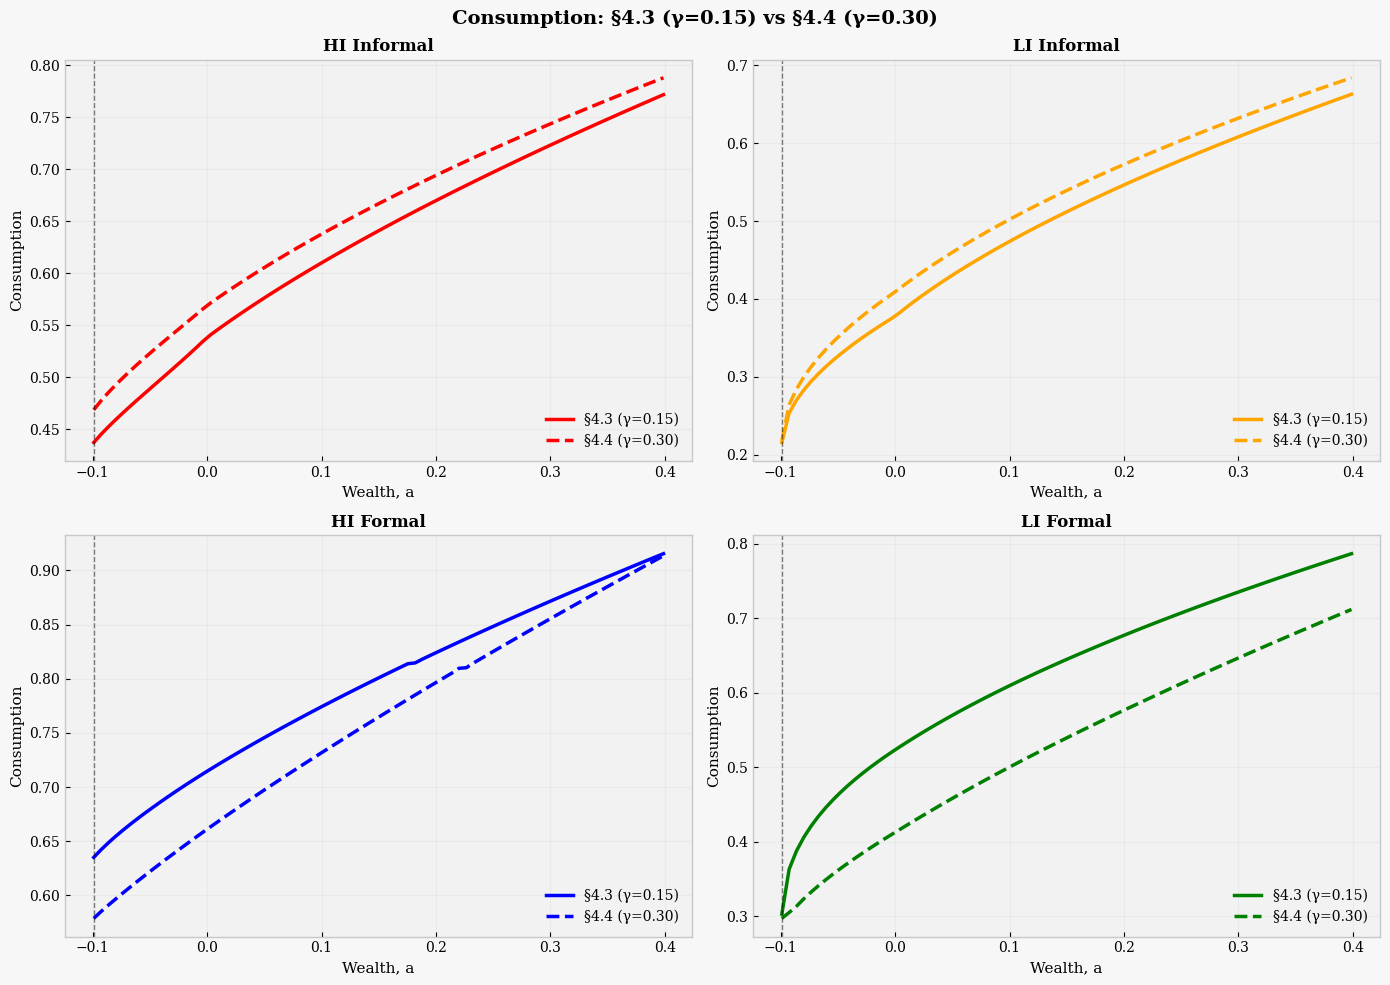

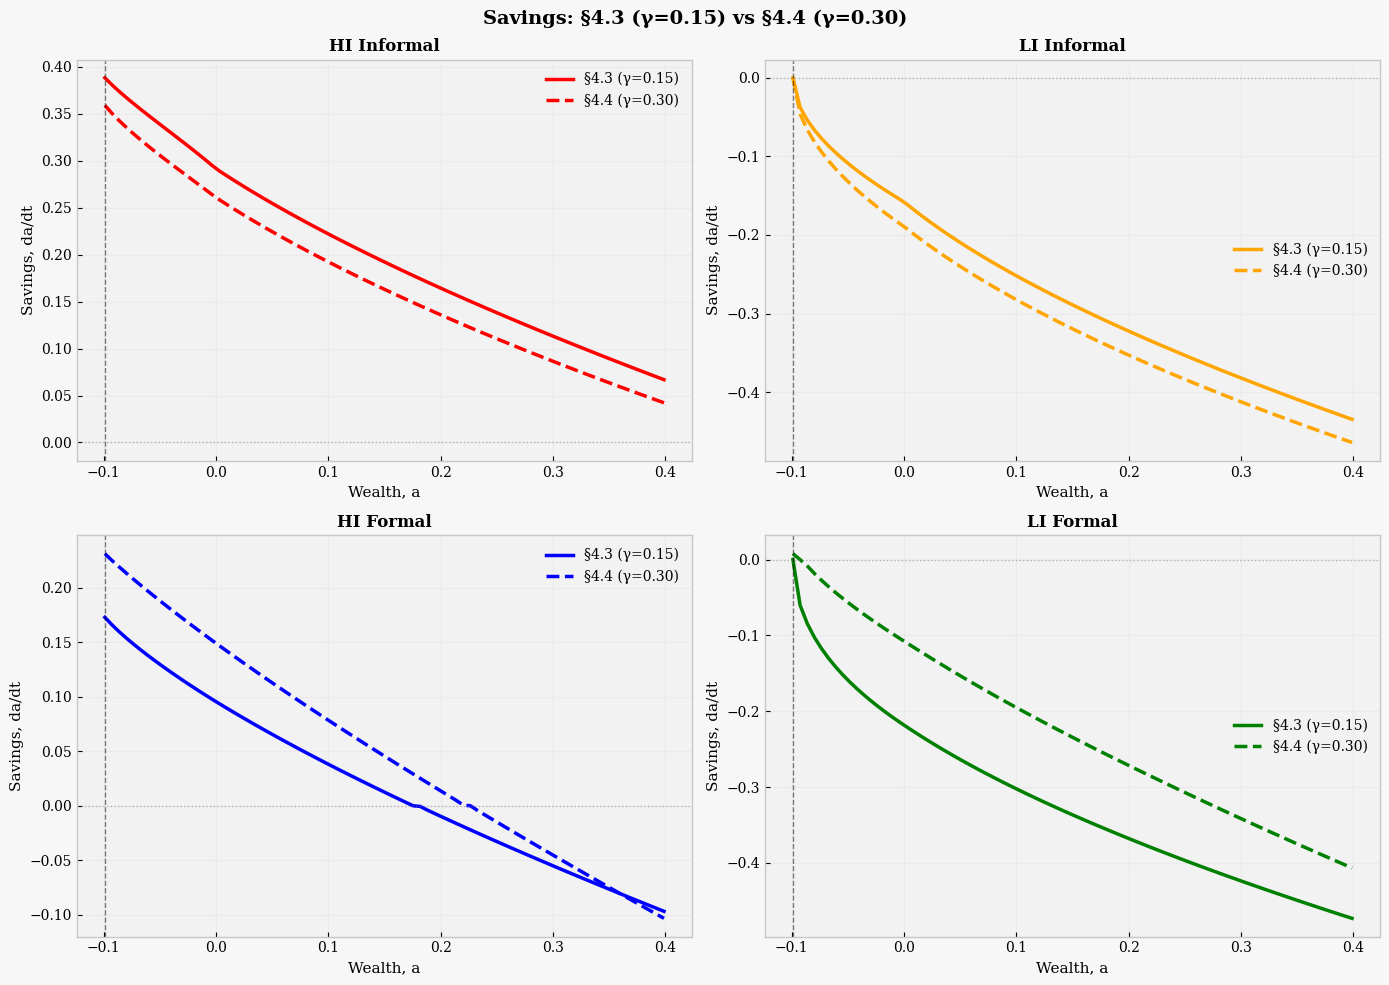


EQUILIBRIUM MOMENTS: §4.3 vs §4.4
       Metric      §4.3     §4.4   Δ (4.4-4.3)           % Δ
           r*  0.021537 0.000500 -2.103748e-02 -9.767847e+01
      Mean(a) -0.000004 0.030208  3.021188e-02  7.242358e+05
    Borrowers  0.547815 0.449436 -9.837904e-02 -1.795843e+01
Mass Informal  0.420000 0.420000  6.106227e-16  1.453863e-13
  Mass Formal  0.580000 0.580000 -5.551115e-16 -9.570888e-14

POLICY FUNCTION DISTANCES: §4.3 vs §4.4
      State  Mean|Δc|  Max|Δc|  Mean|Δs|  Max|Δs|
HI Informal  0.140830 0.357017  0.092596 0.251829
LI Informal  0.121487 0.321417  0.075359 0.216230
  HI Formal  0.359726 0.823893  0.410711 0.929080
  LI Formal  0.343396 0.845281  0.392253 0.950469



In [43]:
# Comparison: §4.3 vs §4.4 at eta=eta_arg
import matplotlib.pyplot as plt
import numpy as np

# Extract results at eta=eta_arg
res_prev = res_43[eta_arg]  # §4.3
res_curr = res_44[eta_arg]  # §4.4

# State labels and colors
state_labels = ["HI Informal", "LI Informal", "HI Formal", "LI Formal"]
state_colors = ["red", "orange", "blue", "green"]

# Asset grid for plots
a_plot = base_params["a"][base_params["a"] <= 0.4]

# ===== CONSUMPTION COMPARISON =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, res_prev.c[:len(a_plot), j], color=color, linestyle='-', linewidth=2.5, label=f'§4.3 (γ=0.15)')
    ax.plot(a_plot, res_curr.c[:len(a_plot), j], color=color, linestyle='--', linewidth=2.5, label=f'§4.4 (γ=0.30)')
    ax.axvline(x=-0.099, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel(f'Consumption', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Consumption: §4.3 (γ=0.15) vs §4.4 (γ=0.30)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== SAVINGS COMPARISON =====
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, res_prev.adot[:len(a_plot), j], color=color, linestyle='-', linewidth=2.5, label=f'§4.3 (γ=0.15)')
    ax.plot(a_plot, res_curr.adot[:len(a_plot), j], color=color, linestyle='--', linewidth=2.5, label=f'§4.4 (γ=0.30)')
    ax.axvline(x=-0.099, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.axhline(y=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel(f'Savings, da/dt', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Savings: §4.3 (γ=0.15) vs §4.4 (γ=0.30)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ===== EQUILIBRIUM MOMENTS TABLE =====
import pandas as pd

metrics_prev = {
    'r*': res_prev.r_star,
    'Mean(a)': res_prev.mean_a,
    'Borrowers': res_prev.borrowers,
    'Mass Informal': res_prev.mass_inf,
    'Mass Formal': res_prev.mass_for,
}

metrics_curr = {
    'r*': res_curr.r_star,
    'Mean(a)': res_curr.mean_a,
    'Borrowers': res_curr.borrowers,
    'Mass Informal': res_curr.mass_inf,
    'Mass Formal': res_curr.mass_for,
}

table_data = []
for key in metrics_prev.keys():
    v_prev = metrics_prev[key]
    v_curr = metrics_curr[key]
    delta = v_curr - v_prev
    pct_delta = 100 * delta / abs(v_prev) if v_prev != 0 else 0
    table_data.append({
        'Metric': key,
        '§4.3': v_prev,
        '§4.4': v_curr,
        'Δ (4.4-4.3)': delta,
        '% Δ': pct_delta,
    })

df_moments = pd.DataFrame(table_data)
print("\n" + "="*80)
print("EQUILIBRIUM MOMENTS: §4.3 vs §4.4")
print("="*80)
print(df_moments.to_string(index=False))
print("="*80 + "\n")

# ===== POLICY FUNCTION DISTANCE TABLE =====
table_dist = []
for j, label in enumerate(state_labels):
    mean_dc = np.mean(np.abs(res_curr.c[:, j] - res_prev.c[:, j]))
    max_dc = np.max(np.abs(res_curr.c[:, j] - res_prev.c[:, j]))
    mean_ds = np.mean(np.abs(res_curr.adot[:, j] - res_prev.adot[:, j]))
    max_ds = np.max(np.abs(res_curr.adot[:, j] - res_prev.adot[:, j]))
    table_dist.append({
        'State': label,
        'Mean|Δc|': mean_dc,
        'Max|Δc|': max_dc,
        'Mean|Δs|': mean_ds,
        'Max|Δs|': max_ds,
    })

df_dist = pd.DataFrame(table_dist)
print("="*80)
print("POLICY FUNCTION DISTANCES: §4.3 vs §4.4")
print("="*80)
print(df_dist.to_string(index=False))
print("="*80 + "\n")

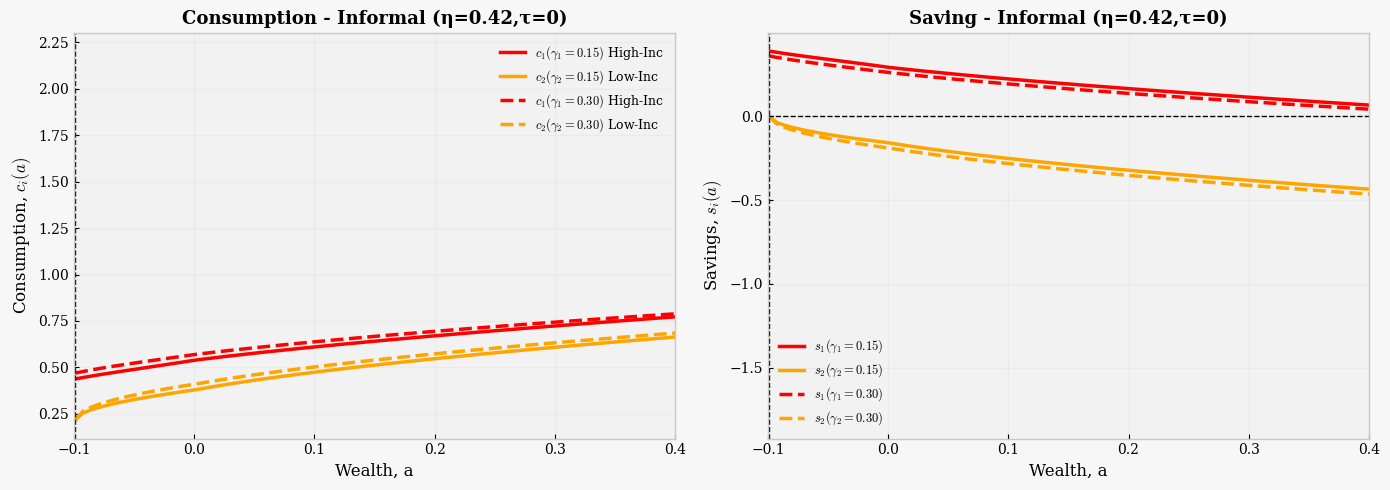

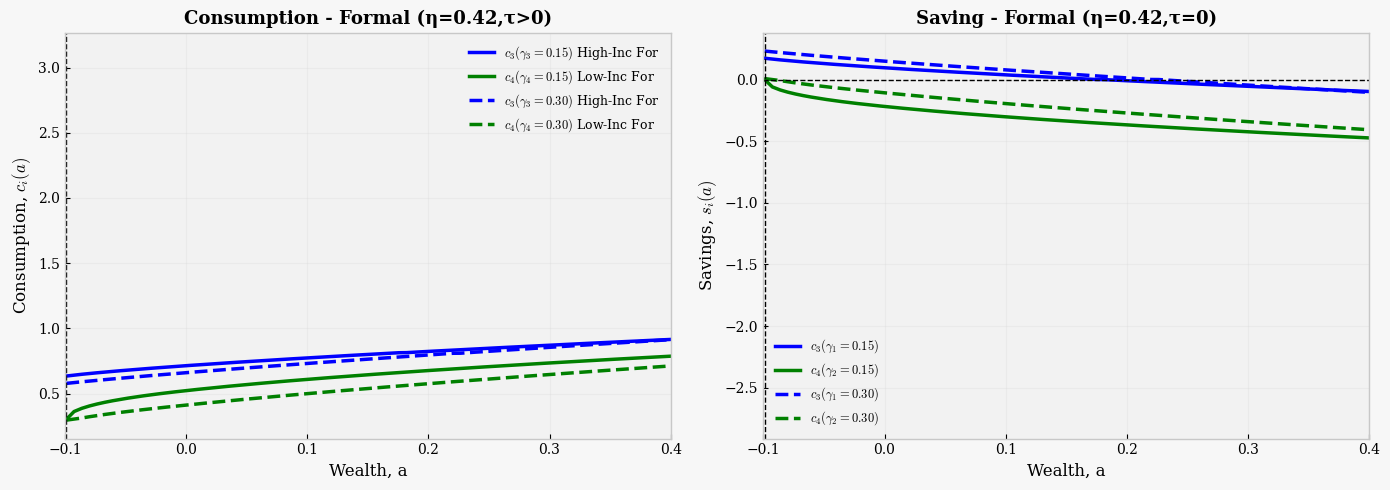

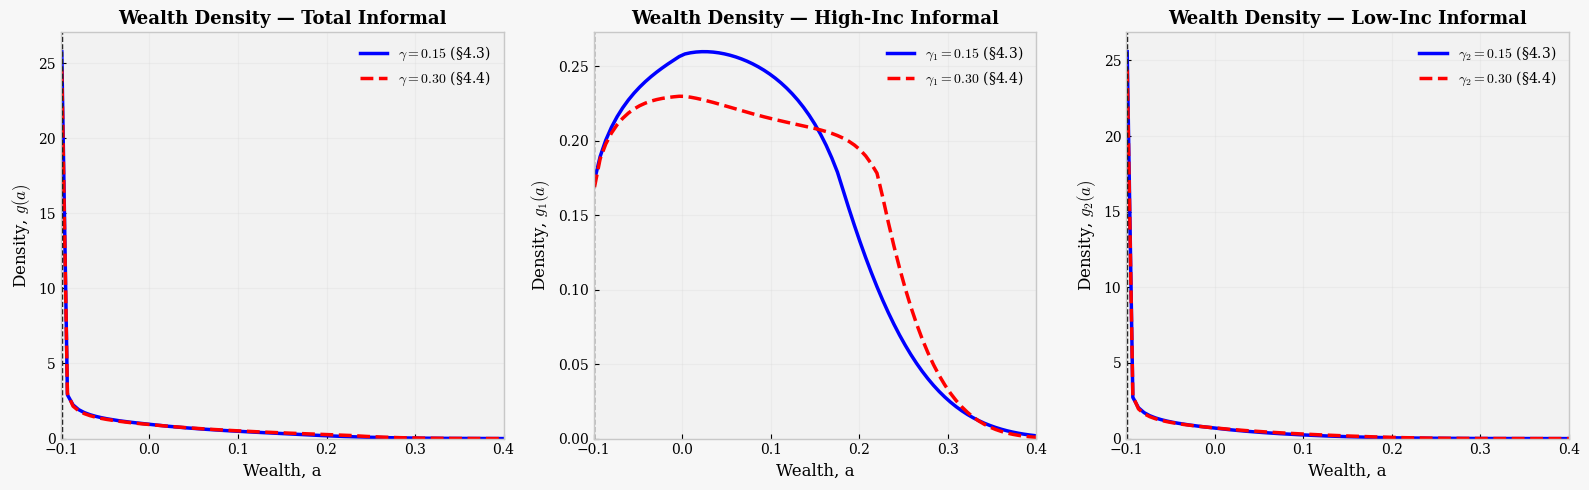

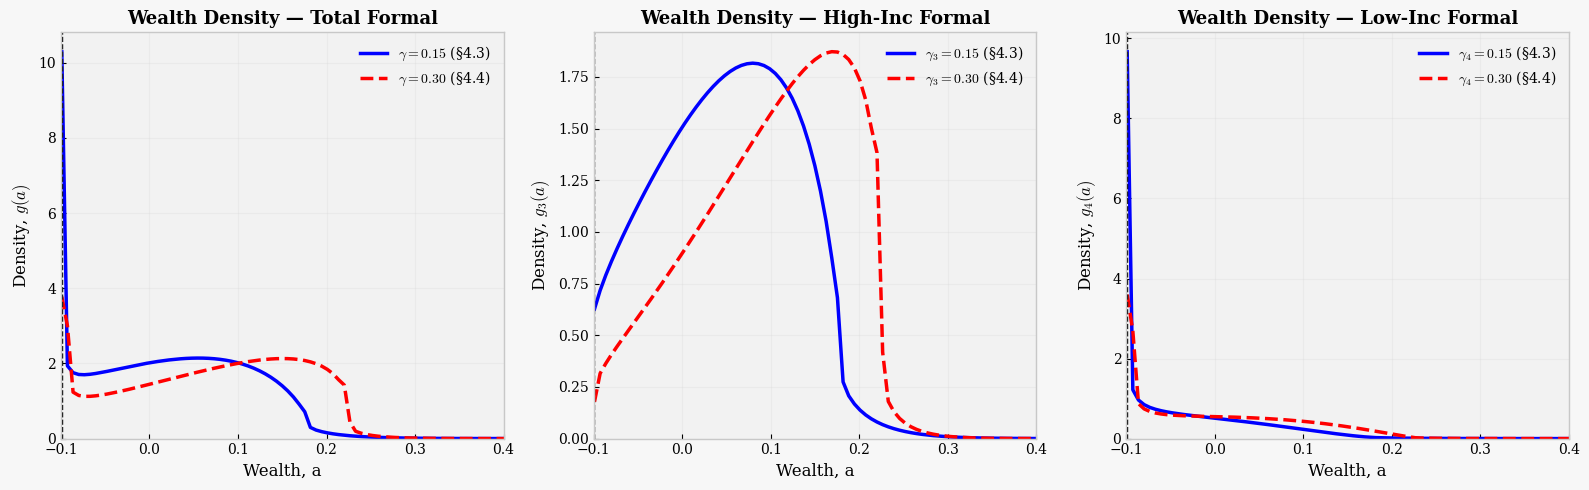

In [44]:
# Comparison plot: §4.3 vs §4.4 for η=0.64 (effect of preference heterogeneity) - INFORMAL
eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]
c_43 = res_43[eta_focus].c
c_44 = res_44[eta_focus].c
adot_43 = res_43[eta_focus].adot
adot_44 = res_44[eta_focus].adot

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left panel: Consumption comparison (informal states)
ax1.plot(a_plot, c_43[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$c_1(\gamma_1=0.15)$ High-Inc')
ax1.plot(a_plot, c_43[:,1], color='orange', linestyle='-', linewidth=2.5, label=r'$c_2(\gamma_2=0.15)$ Low-Inc')
ax1.plot(a_plot, c_44[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$c_1(\gamma_1=0.30)$ High-Inc')
ax1.plot(a_plot, c_44[:,1], color='orange', linestyle='--', linewidth=2.5, label=r'$c_2(\gamma_2=0.30)$ Low-Inc')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title('Consumption - Informal (η=0.42,τ=0)', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=9)
ax1.grid(alpha=0.3)

# Right panel: Saving comparison
ax2.plot(a_plot, adot_43[:,0], color='red', linestyle='-', linewidth=2.5, label=r'$s_1(\gamma_1=0.15)$')
ax2.plot(a_plot, adot_43[:,1], color='orange', linestyle='-', linewidth=2.5, label=r'$s_2(\gamma_2=0.15)$')
ax2.plot(a_plot, adot_44[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$s_1(\gamma_1=0.30)$')
ax2.plot(a_plot, adot_44[:,1], color='orange', linestyle='--', linewidth=2.5, label=r'$s_2(\gamma_2=0.30)$')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title('Saving - Informal (η=0.42,τ=0)', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.3 vs §4.4 for η=0.64 - INFORMAL
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(a_plot, c_43[:,2], color='blue', linestyle='-', linewidth=2.5, label=r'$c_3(\gamma_3=0.15)$ High-Inc For')
ax1.plot(a_plot, c_43[:,3], color='green', linestyle='-', linewidth=2.5, label=r'$c_4(\gamma_4=0.15)$ Low-Inc For')
ax1.plot(a_plot, c_44[:,2], color='blue', linestyle='--', linewidth=2.5, label=r'$c_3(\gamma_3=0.30)$ High-Inc For')
ax1.plot(a_plot, c_44[:,3], color='green', linestyle='--', linewidth=2.5, label=r'$c_4(\gamma_4=0.30)$ Low-Inc For')
ax1.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax1.set_xlabel('Wealth, a', fontsize=12)
ax1.set_ylabel('Consumption, $c_i(a)$', fontsize=12)
ax1.set_xlim([-0.1, 0.4])
ax1.set_title('Consumption - Formal (η=0.42,τ>0)', fontsize=13, fontweight='bold')
ax1.legend(loc='best', fontsize=9)
ax1.grid(alpha=0.3)

ax2.plot(a_plot, adot_43[:,2], color='blue', linestyle='-', linewidth=2.5, label=r'$c_3(\gamma_1=0.15)$')
ax2.plot(a_plot, adot_43[:,3], color='green', linestyle='-', linewidth=2.5, label=r'$c_4(\gamma_2=0.15)$')
ax2.plot(a_plot, adot_44[:,2], color='blue', linestyle='--', linewidth=2.5, label=r'$c_3(\gamma_1=0.30)$')
ax2.plot(a_plot, adot_44[:,3], color='green', linestyle='--', linewidth=2.5, label=r'$c_4(\gamma_2=0.30)$')
ax2.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax2.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax2.set_xlabel('Wealth, a', fontsize=12)
ax2.set_ylabel('Savings, $s_i(a)$', fontsize=12)
ax2.set_xlim([-0.1, 0.4])
ax2.set_title('Saving - Formal (η=0.42,τ=0)', fontsize=13, fontweight='bold')
ax2.legend(loc='best', fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Distribution comparison plot: §4.3 vs §4.4 for η=0.64
g_43 = res_43[eta_focus].g
g_44 = res_44[eta_focus].g
g_total_inf_43 = g_43[:,0] + g_43[:,1]
g_total_inf_44 = g_44[:,0] + g_44[:,1]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total informal
ax = axes[0]
ax.plot(a_plot, g_total_inf_43, color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma=0.15$ (§4.3)')
ax.plot(a_plot, g_total_inf_44, color='red', linestyle='--', linewidth=2.5, label=r'$\gamma=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Informal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: High-income informal
ax = axes[1]
ax.plot(a_plot, g_43[:,0], color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_1=0.15$ (§4.3)')
ax.plot(a_plot, g_44[:,0], color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_1=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_1(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — High-Inc Informal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)


# Panel 3: Low-income informal
ax = axes[2]
ax.plot(a_plot, g_43[:,1], color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_2=0.15$ (§4.3)')
ax.plot(a_plot, g_44[:,1], color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_2=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_2(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Low-Inc Informal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Distribution comparison plot: §4.3 vs §4.4 for η=0.64 - FORMAL agents
g_total_for_43 = g_43[:,2] + g_43[:,3]
g_total_for_44 = g_44[:,2] + g_44[:,3]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Panel 1: Total formal
ax = axes[0]
ax.plot(a_plot, g_total_for_43, color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma=0.15$ (§4.3)')
ax.plot(a_plot, g_total_for_44, color='red', linestyle='--', linewidth=2.5, label=r'$\gamma=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Total Formal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 2: High-income formal
ax = axes[1]
ax.plot(a_plot, g_43[:,2], color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_3=0.15$ (§4.3)')
ax.plot(a_plot, g_44[:,2], color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_3=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_3(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — High-Inc Formal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

# Panel 3: Low-income formal
ax = axes[2]
ax.plot(a_plot, g_43[:,3], color='blue', linestyle='-', linewidth=2.5, label=r'$\gamma_4=0.15$ (§4.3)')
ax.plot(a_plot, g_44[:,3], color='red', linestyle='--', linewidth=2.5, label=r'$\gamma_4=0.30$ (§4.4)')
ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1)
ax.set_xlabel('Wealth, a', fontsize=12)
ax.set_ylabel('Density, $g_4(a)$', fontsize=12)
ax.set_xlim([-0.1, 0.4])
ax.set_ylim(bottom=0)
ax.set_title('Wealth Density — Low-Inc Formal', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Final summary

In [45]:
import pandas as pd
df_all = pd.concat([df_41, df_42, df_43, df_44], ignore_index=True)
try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user("Galindo §4.1–§4.4 — Summary", df_all)
except Exception:
    print(df_all.to_string(index=False))

                     Section  eta       r*       Mean(a)  Borrowers Mass  Mass Informal  Mass Formal  Bond Supply Informal  Bond Demand Informal  Bond Supply Formal  Bond Demand Formal  Bond Decomp Residual
          Section 1 (η-only) 0.20 0.022992 -5.952303e-06        0.509942           0.20         0.80              0.013299              0.002306            0.022350            0.033337          5.952303e-06
          Section 1 (η-only) 0.42 0.018977  5.536770e-06        0.556186           0.42         0.58              0.026336              0.007360            0.014422            0.033404         -5.536770e-06
                  §4.2 Taxes 0.20 0.027404  5.920862e-06        0.511368           0.20         0.80              0.012770              0.003226            0.022585            0.032135         -5.920862e-06
                  §4.2 Taxes 0.42 0.023410 -2.193185e-06        0.553034           0.42         0.58              0.025209              0.010279            0.014889        

In [46]:
# ---- Helper function for government accounting and welfare analysis ----

def gov_and_welfare_from_result(result, params, gamma_vec, tau_vec):
    """
    Compute government budget and welfare from an equilibrium result.
    
    Aggregates 4 states into informal (states 0,1) and formal (states 2,3).
    Computes:
    - Gov budget (tax revenue)
    - Welfare with additive public good
    
    Parameters:
    -----------
    result : SimpleNamespace
        Contains .g (distribution), .c (consumption)
    params : dict
        Contains 'a', 'da', 'z', 'rho'
    gamma_vec : array (4,)
        Risk aversion by state
    tau_vec : array (4,)
        Tax rates by state
        
    Returns:
    --------
    dict with keys: gov, tax_rev_inf, tax_rev_for, mass_inf, mass_for,
                    private_flow, total_flow, private_lifetime, total_lifetime
    """
    a = params["a"]
    da = params["da"]
    z = params["z"]  # array of 4 productivity levels
    rho = params["rho"]

    g = result.g  # (I, 4)
    c = result.c  # (I, 4)

    # Aggregate informal (states 0,1) and formal (states 2,3)
    mass_inf = (g[:, 0].sum() + g[:, 1].sum()) * da
    mass_for = (g[:, 2].sum() + g[:, 3].sum()) * da

    # Tax revenue by employment sector
    tau_inf = np.mean(tau_vec[0:2])  # Average informal tax
    tau_for = np.mean(tau_vec[2:4])  # Average formal tax
    z_inf = np.mean(z[0:2])          # Average informal productivity
    z_for = np.mean(z[2:4])          # Average formal productivity
    
    tax_rev_inf = float(tau_inf * z_inf * mass_inf)
    tax_rev_for = float(tau_for * z_for * mass_for)
    gov = tax_rev_inf + tax_rev_for

    # Flow utility by state
    gamma_arr = np.array(gamma_vec, dtype=float)
    util = u(c, gamma_arr)  # (I, 4)
    
    # Private utility flow: sum over states, weighted by distribution
    private_flow = float((util[:, 0] @ g[:, 0] + util[:, 1] @ g[:, 1] + 
                          util[:, 2] @ g[:, 2] + util[:, 3] @ g[:, 3]) * da)
    
    # Total flow: private + additive public good (gov budget)
    total_flow = private_flow + gov

    # Lifetime equivalents (normalize by time discount)
    private_lifetime = private_flow / rho
    total_lifetime = total_flow / rho

    return {
        "gov": gov,
        "tax_rev_inf": tax_rev_inf,
        "tax_rev_for": tax_rev_for,
        "mass_inf": mass_inf,
        "mass_for": mass_for,
        "private_flow": private_flow,
        "total_flow": total_flow,
        "private_lifetime": private_lifetime,
        "total_lifetime": total_lifetime,
    }

## Government Accounting and Welfare: What this block does

This part computes fiscal and welfare outcomes from the equilibrium objects already solved in Sections 4.1 to 4.4.

For each available section result and each eta, we:
- read the stationary distribution and policy outputs
- compute tax revenue (informal and formal components)
- compute private utility flow from consumption and distribution
- add government revenue as a public-good component
- report both flow and lifetime welfare measures

State aggregation is consistent with the model order used in the notebook:
- Informal = states 1 and 2
- Formal = states 3 and 4

The output is a comparison table that lets you evaluate how each section changes fiscal capacity and welfare at eta=0.20 and eta=eta_arg.

In [47]:
# ---- Step 1-2: Government accounting and welfare across all sections ----

section_candidates = [
    ("§4.1 η-only", "res_41", "gamma_41", "tau_41", "theta_41"),
    ("§4.2 Taxes", "res_42", "gamma_42", "tau_42", "theta_42"),
    ("§4.3 Premium", "res_43", "gamma_43", "tau_43", "theta_43"),
    ("§4.4 Risk Aversion", "res_44", "gamma_44", "tau_44", "theta_44"),
]

rows_gov = []
for sec_name, res_name, gam_name, tau_name, theta_name in section_candidates:
    # Check if all required variables exist
    if not all(name in globals() for name in [res_name, gam_name, tau_name]):
        continue

    res_dict = globals()[res_name]
    gamma_vec = globals()[gam_name]
    tau_vec = globals()[tau_name]

    for eta, out in sorted(res_dict.items(), key=lambda kv: kv[0]):
        stats = gov_and_welfare_from_result(out, base_params, gamma_vec, tau_vec)
        rows_gov.append({
            "Section": sec_name,
            "eta": float(eta),
            "r*": float(out.r_star),
            "Gov (tax rev)": stats["gov"],
            "Tax rev informal": stats["tax_rev_inf"],
            "Tax rev formal": stats["tax_rev_for"],
            "Mass informal": stats["mass_inf"],
            "Mass formal": stats["mass_for"],
            "Private welfare (flow)": stats["private_flow"],
            "Total welfare (flow)": stats["total_flow"],
            "Private welfare (lifetime)": stats["private_lifetime"],
            "Total welfare (lifetime)": stats["total_lifetime"],
        })

if len(rows_gov) == 0:
    print("No section results found. Run the section cells first (res_41/res_42/res_43/res_44).")
else:
    df_gov_welfare = pd.DataFrame(rows_gov).sort_values(["Section", "eta"]).reset_index(drop=True)
    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user("Government Accounting and Welfare (Steps 1-2)", df_gov_welfare)
    except Exception:
        print(df_gov_welfare.to_string(index=False))

           Section  eta       r*  Gov (tax rev)  Tax rev informal  Tax rev formal  Mass informal  Mass formal  Private welfare (flow)  Total welfare (flow)  Private welfare (lifetime)  Total welfare (lifetime)
       §4.1 η-only 0.20 0.022992       0.120345          0.019940        0.100405           0.20         0.80                0.717872              0.838218                   14.357447                 16.764355
       §4.1 η-only 0.42 0.018977       0.114668          0.041875        0.072794           0.42         0.58                0.626639              0.741308                   12.532785                 14.826154
        §4.2 Taxes 0.20 0.027404       0.063414          0.000000        0.063414           0.20         0.80                0.745333              0.808747                   14.906658                 16.174932
        §4.2 Taxes 0.42 0.023410       0.045975          0.000000        0.045975           0.42         0.58                0.666718              0.712693     

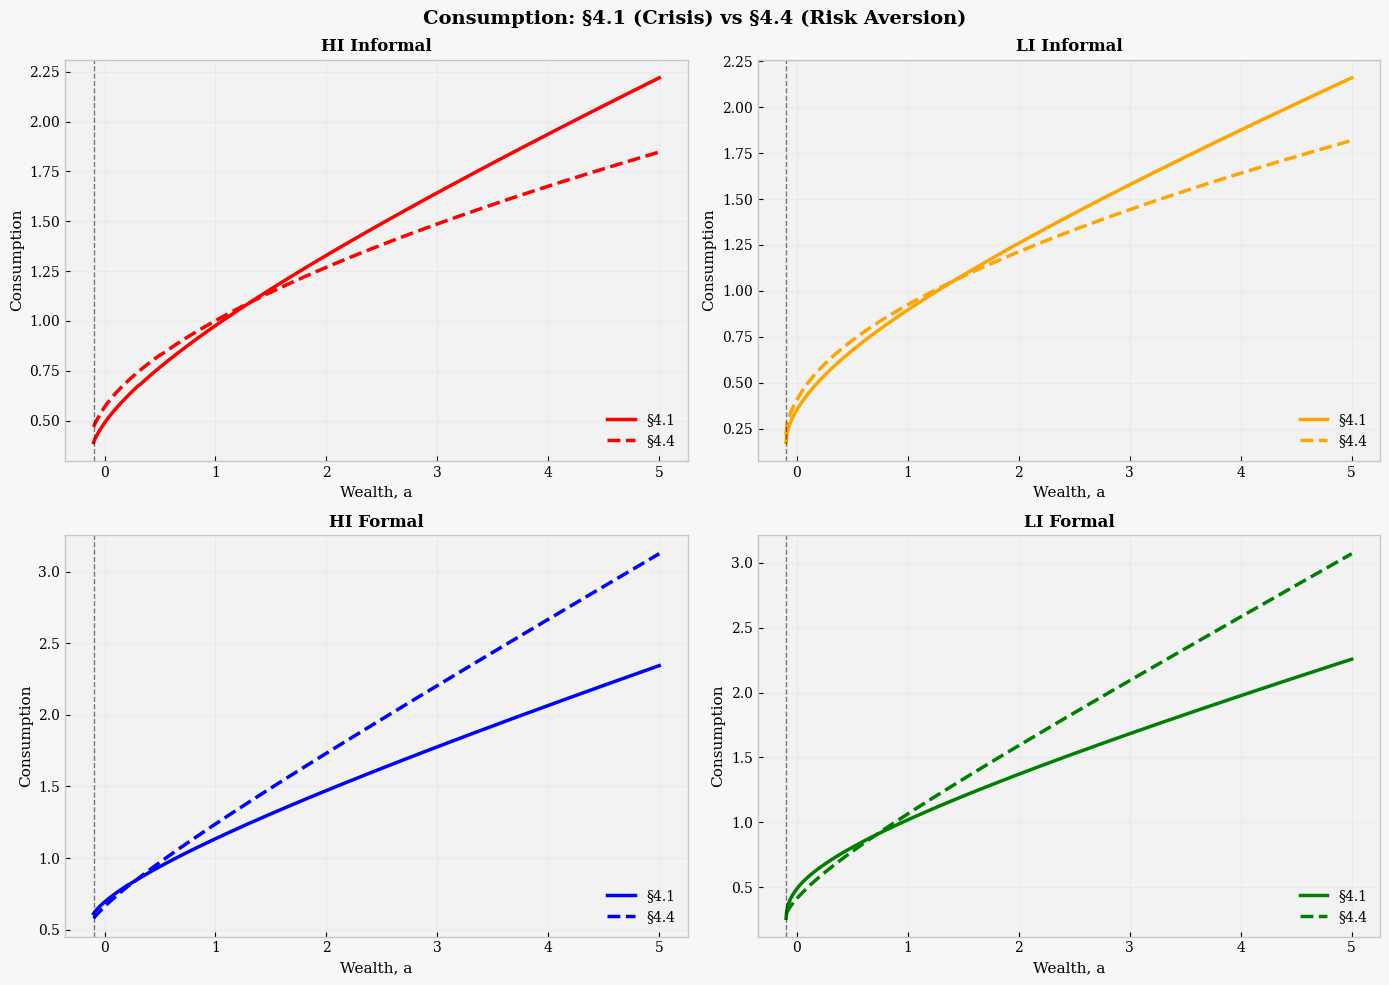

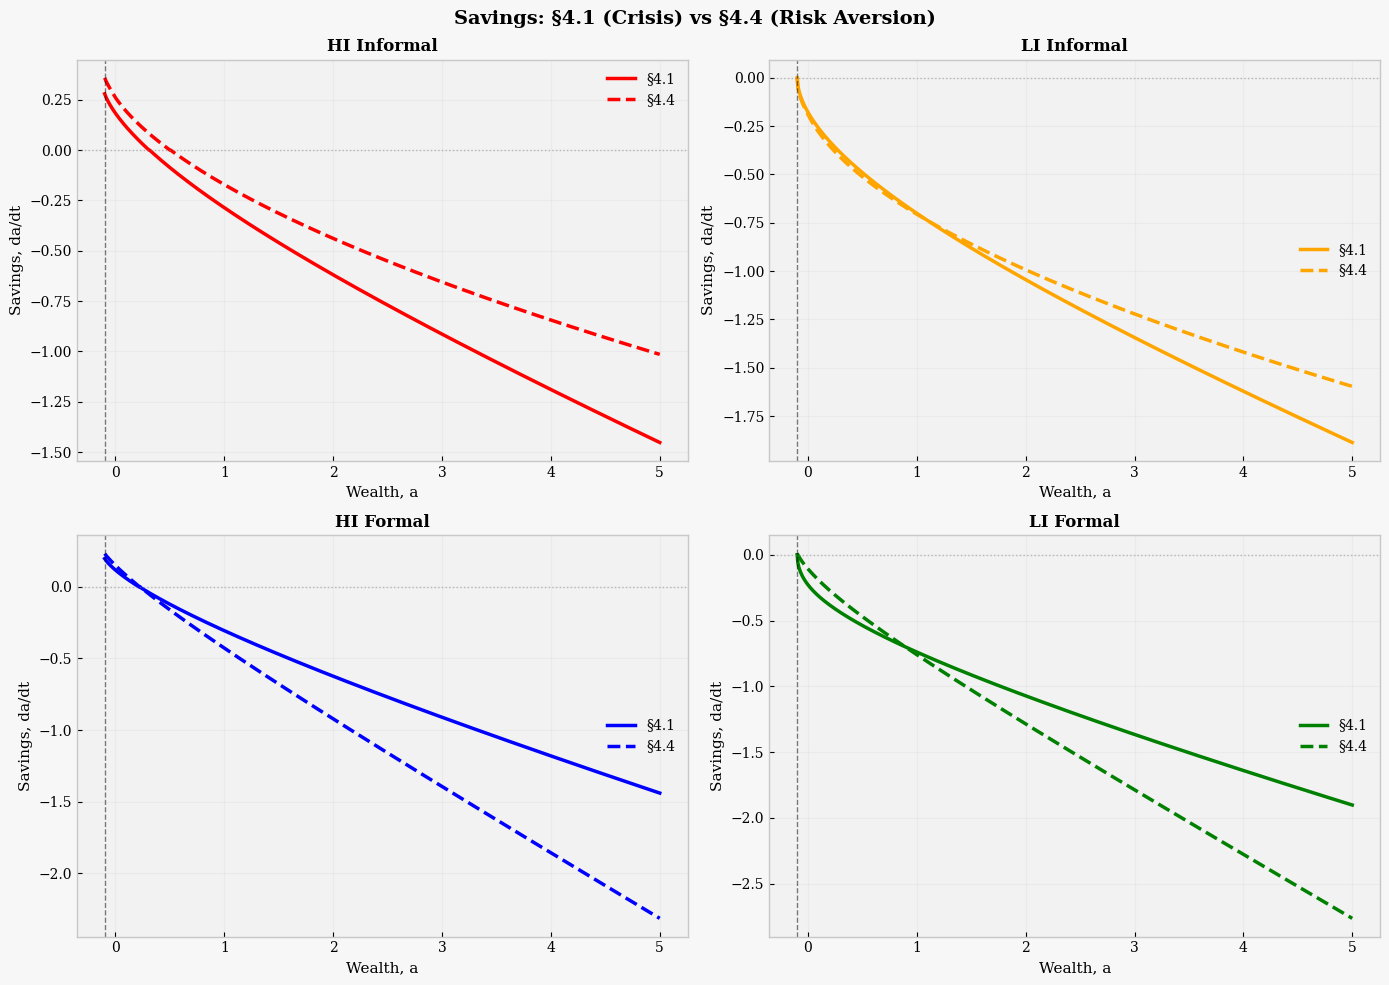

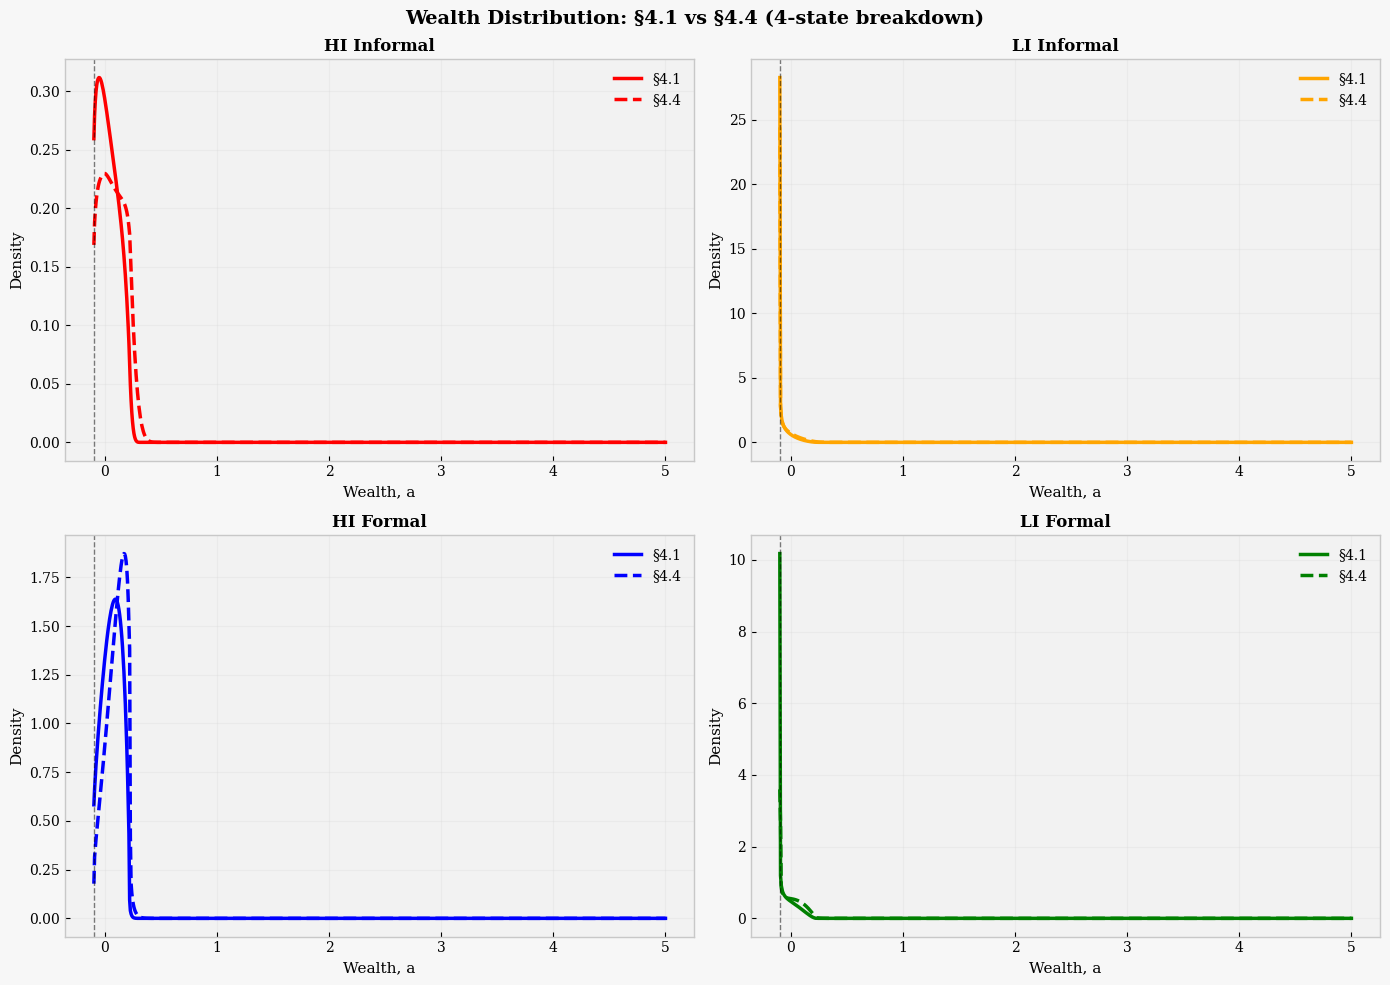


FULL COMPARISON: §4.1 vs §4.4 at eta=0.42

Headline moments (4.1 vs 4.4):
        Metric  Section 4.1  Section 4.4  Abs Change (4.4-4.1)  % Change vs 4.1
            r*    0.0189771       0.0005            -0.0184771         -97.3652
       Mean(a)  5.53677e-06    0.0302077             0.0302022           545483
Borrowers Mass     0.556186     0.449436             -0.106749         -19.1931
 Mass Informal         0.42         0.42          -1.38778e-15     -3.30424e-13
   Mass Formal         0.58         0.58           9.99201e-16      1.72276e-13

Policy-function distance by state (4.1 vs 4.4):
      State  Mean|Δc|   Max|Δc|  Mean|Δs|   Max|Δs|
HI Informal  0.141559   0.37231  0.226787  0.437585
LI Informal  0.124974  0.340684  0.104814  0.290041
  HI Formal  0.348194  0.782034  0.393261   0.87442
  LI Formal  0.336016  0.813914  0.349903  0.861343

Welfare/accounting comparison (4.1 vs 4.4):
                    Metric  Section 4.1  Section 4.4  Abs Change (4.4-4.1)  % Change vs 4.1

In [48]:
# ---- Full comparison: §4.1 vs §4.4 at eta=eta_arg ----

eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]

res41 = res_41[eta_focus]
res44 = res_44[eta_focus]

c_41 = res41.c
c_44 = res44.c
adot_41 = res41.adot
adot_44 = res44.adot

# ================================================================
# 1) Policy comparison: consumption + savings (4-state breakdown)
# ================================================================
state_labels = ["HI Informal", "LI Informal", "HI Formal", "LI Formal"]
state_colors = ["red", "orange", "blue", "green"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, c_41[:, j], color=color, linestyle='-', linewidth=2.5, label=f'§4.1')
    ax.plot(a_plot, c_44[:, j], color=color, linestyle='--', linewidth=2.5, label=f'§4.4')
    ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel('Consumption', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Consumption: §4.1 (Crisis) vs §4.4 (Risk Aversion)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, adot_41[:, j], color=color, linestyle='-', linewidth=2.5, label=f'§4.1')
    ax.plot(a_plot, adot_44[:, j], color=color, linestyle='--', linewidth=2.5, label=f'§4.4')
    ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.axhline(y=0, color='gray', linestyle=':', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel('Savings, da/dt', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Savings: §4.1 (Crisis) vs §4.4 (Risk Aversion)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ================================================================
# 2) Distribution comparison: by state
# ================================================================
g_41 = res41.g
g_44 = res44.g

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for j, (label, color) in enumerate(zip(state_labels, state_colors)):
    ax = axes[j // 2, j % 2]
    ax.plot(a_plot, g_41[:, j], color=color, linestyle='-', linewidth=2.5, label=f'§4.1')
    ax.plot(a_plot, g_44[:, j], color=color, linestyle='--', linewidth=2.5, label=f'§4.4')
    ax.axvline(x=amin_plot, color='black', linestyle='--', linewidth=1, alpha=0.5)
    ax.set_xlabel('Wealth, a', fontsize=11)
    ax.set_ylabel('Density', fontsize=11)
    ax.set_title(f'{label}', fontsize=12, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(alpha=0.3)
fig.suptitle('Wealth Distribution: §4.1 vs §4.4 (4-state breakdown)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ================================================================
# 3) Headline equilibrium moments table
# ================================================================
def safe_pct(delta, base):
    if abs(base) < 1e-12:
        return np.nan
    return 100.0 * delta / base

summary_metrics = [
    ("r*", res41.r_star, res44.r_star),
    ("Mean(a)", res41.mean_a, res44.mean_a),
    ("Borrowers Mass", res41.borrowers, res44.borrowers),
    ("Mass Informal", res41.mass_inf, res44.mass_inf),
    ("Mass Formal", res41.mass_for, res44.mass_for),
]

summary_rows = []
for metric, v41, v44 in summary_metrics:
    delta = v44 - v41
    summary_rows.append({
        "Metric": metric,
        "Section 4.1": v41,
        "Section 4.4": v44,
        "Abs Change (4.4-4.1)": delta,
        "% Change vs 4.1": safe_pct(delta, v41),
    })

df_compare_41_44 = pd.DataFrame(summary_rows)

# ================================================================
# 4) Policy distance table
# ================================================================
policy_rows = []
for j, label in enumerate(state_labels):
    policy_rows.append({
        "State": label,
        "Mean|Δc|": np.mean(np.abs(c_44[:, j] - c_41[:, j])),
        "Max|Δc|": np.max(np.abs(c_44[:, j] - c_41[:, j])),
        "Mean|Δs|": np.mean(np.abs(adot_44[:, j] - adot_41[:, j])),
        "Max|Δs|": np.max(np.abs(adot_44[:, j] - adot_41[:, j])),
    })

df_policy_gap_41_44 = pd.DataFrame(policy_rows)

print(f'\n{"="*80}')
print(f'FULL COMPARISON: §4.1 vs §4.4 at eta={eta_focus:.2f}')
print(f'{"="*80}')
print('\nHeadline moments (4.1 vs 4.4):')
print(df_compare_41_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
print('\nPolicy-function distance by state (4.1 vs 4.4):')
print(df_policy_gap_41_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))

# ================================================================
# 5) Welfare/accounting comparison from df_gov_welfare
# ================================================================
if 'df_gov_welfare' in globals():
    df_gw = df_gov_welfare.copy()
    sub = df_gw[(df_gw['Section'].isin(['§4.1 η-only', '§4.4 Risk Aversion'])) & (np.isclose(df_gw['eta'], eta_focus))]

    if len(sub) == 2:
        row41 = sub[sub['Section'] == '§4.1 η-only'].iloc[0]
        row44 = sub[sub['Section'] == '§4.4 Risk Aversion'].iloc[0]

        welfare_cols = [
            'Gov (tax rev)',
            'Private welfare (flow)',
            'Total welfare (flow)',
            'Private welfare (lifetime)',
            'Total welfare (lifetime)',
        ]

        rows_w = []
        for col in welfare_cols:
            v41 = float(row41[col])
            v44 = float(row44[col])
            d = v44 - v41
            rows_w.append({
                'Metric': col,
                'Section 4.1': v41,
                'Section 4.4': v44,
                'Abs Change (4.4-4.1)': d,
                '% Change vs 4.1': safe_pct(d, v41),
            })

        df_welfare_41_44 = pd.DataFrame(rows_w)
        print('\nWelfare/accounting comparison (4.1 vs 4.4):')
        print(df_welfare_41_44.to_string(index=False, float_format=lambda x: f"{x: .6g}"))
        print(f'{"="*80}\n')
    else:
        print('\n⚠ Welfare/accounting table: run the government accounting cell first.')
else:
    print('\n⚠ Welfare/accounting: df_gov_welfare not found; run the government accounting cell first.')

## Why this optional extension exists and what it is doing

This block adds a policy feedback channel that is not in the baseline model.
In the baseline, productivity levels z are fixed numbers.
Here, productivity becomes endogenous through government resources.

Core idea: if public resources improve infrastructure, enforcement, health, or education, effective productivity can rise.
The cell captures that by setting

$$z^{eff}_i = z_i (1 + \xi \cdot gov),$$

where:
- $z_i$ is baseline productivity in state $i$
- $gov$ is government tax revenue in equilibrium
- $\xi \ge 0$ controls the strength of the feedback

So this is a two-way loop:
1. Taxes and the stationary distribution determine government revenue.
2. Government revenue changes effective productivity.
3. New productivity changes household decisions, prices, and distribution.
4. That changes tax revenue again.

Because of this circular dependence, we need a fixed-point iteration.

## Intuition for the fixed-point loop

Think of it as guess and update:
1. Start with a guess for government revenue, initially 0.
2. Build effective productivity from that guess.
3. Solve the full equilibrium with those productivity levels.
4. Compute the implied new government revenue from the resulting distribution.
5. If new and old revenue are close, stop.
6. If not, update the guess and repeat.

The update is damped:

$$gov_{new\ guess} = 0.5 \cdot gov_{old\ guess} + 0.5 \cdot gov_{implied}$$

Damping is useful because fixed-point systems can oscillate if updated too aggressively.
It improves numerical stability.

## Why this is useful economically

This extension helps answer a different question than the baseline.
Baseline asks: what happens when taxes, premiums, and preferences change, holding productivity fixed.
This extension asks: what if fiscal capacity also affects productive opportunities?

That is important when you believe public spending has real effects on production conditions.
Examples:
- Better transport and logistics that reduce firm costs
- Better contract enforcement and institutions
- Better public services that raise worker productivity

In those environments, tax policy can have both distortionary and productivity-improving effects.
This cell lets you test that mechanism in a controlled way.

## Why it is optional and isolated

The extension is intentionally separate from the baseline pipeline.
That protects comparability of Sections 4.1 to 4.4 and keeps your baseline results reproducible.
You can switch it on only when you want this additional mechanism.

## How to read the comparison output

The cell compares two models at the same calibration point:
- Baseline model with fixed productivity
- Extension model with productivity feedback and chosen $\xi$

Key things to inspect:
- Change in equilibrium interest rate $r^*$
- Change in government revenue
- Change in total welfare
- Change in effective productivity levels by state

If differences are small, feedback is weak at that calibration.
If differences are large, fiscal-productivity feedback is quantitatively important.

In [49]:
# ---- Optional extension: Productivity feedback from government budget ----

def find_equilibrium_with_gov_feedback(
    eta,
    params,
    gamma_vec,
    tau_vec,
    theta_vec,
    Lambda,
    xi=0.0,
    tol_gov=1e-7,
    max_iter_gov=30,
    verbose=False,
):
    """
    Optional extension: solve equilibrium with productivity feedback from gov.
    
    z_eff = z_base * (1 + xi * gov)
    gov   = sum over states of (tau_i * z_eff_i * mass_i)
    
    This is solved by a fixed-point loop around the baseline equilibrium solver.
    """
    if xi < 0:
        raise ValueError("xi must be non-negative")

    params_ext = dict(params)
    z_base = np.array(params["z"], dtype=float).copy()
    gov_guess = 0.0
    final_bundle = None

    for it in range(max_iter_gov):
        z_eff = z_base * (1.0 + xi * gov_guess)
        params_ext["z"] = z_eff

        r_star, V, c, A, g, adot, lambdas = find_equilibrium(
            eta=eta,
            params=params_ext,
            gamma_vec=np.array(gamma_vec, dtype=float),
            tau_vec=np.array(tau_vec, dtype=float),
            theta_vec=np.array(theta_vec, dtype=float),
            Lambda=Lambda,
            verbose=False,
        )

        da = params_ext["da"]
        # Aggregate informal (states 0,1) and formal (states 2,3)
        mass_inf = (g[:, 0].sum() + g[:, 1].sum()) * da
        mass_for = (g[:, 2].sum() + g[:, 3].sum()) * da
        
        tau_inf = np.mean(tau_vec[0:2])
        tau_for = np.mean(tau_vec[2:4])
        z_inf = np.mean(z_eff[0:2])
        z_for = np.mean(z_eff[2:4])
        
        gov_new = float(tau_inf * z_inf * mass_inf + tau_for * z_for * mass_for)
        final_bundle = (r_star, V, c, A, g, adot, lambdas, z_eff, gov_new)

        if verbose:
            print(f"[ext] iter={it+1:02d}, gov_guess={gov_guess:.8f}, gov_new={gov_new:.8f}")

        if abs(gov_new - gov_guess) < tol_gov:
            if verbose:
                print(f"[ext] Converged at iteration {it+1}")
            break

        # Damped update for stability
        gov_guess = 0.5 * gov_guess + 0.5 * gov_new

    r_star, V, c, A, g, adot, lambdas, z_eff, gov_star = final_bundle

    return {
        "r_star": r_star,
        "V": V,
        "c": c,
        "A": A,
        "g": g,
        "adot": adot,
        "lambdas": lambdas,
        "z_eff": z_eff,
        "gov_star": gov_star,
        "xi": xi,
    }


# ---- Run optional extension comparison ----
RUN_OPTIONAL_EXTENSION = True

if RUN_OPTIONAL_EXTENSION:
    print(f"\n{'='*80}")
    print("OPTIONAL EXTENSION: Productivity feedback from government budget")
    print(f"{'='*80}\n")
    
    # Example: compare baseline vs extension at eta_arg under §4.2 calibration
    eta_use = eta_arg
    gamma_use = gamma_42
    tau_use = tau_42
    theta_use = theta_42
    Lambda_use = Lambda_dict[eta_use]

    # Baseline (no feedback, xi=0)
    r0, V0, c0, A0, g0, adot0, lambdas0 = find_equilibrium(
        eta=eta_use,
        params=base_params,
        gamma_vec=np.array(gamma_use, dtype=float),
        tau_vec=np.array(tau_use, dtype=float),
        theta_vec=np.array(theta_use, dtype=float),
        Lambda=Lambda_use,
        verbose=False,
    )

    # Create a simple result object for the baseline
    baseline_result = type("obj", (), {"g": g0, "c": c0, "r_star": r0, 
                                       "mean_a": 0, "borrowers": 0, 
                                       "mass_inf": 0, "mass_for": 0})()
    base_stats = gov_and_welfare_from_result(baseline_result, base_params, gamma_use, tau_use)

    # Extension with positive feedback strength xi
    xi_use = 0.50
    ext = find_equilibrium_with_gov_feedback(
        eta=eta_use,
        params=base_params,
        gamma_vec=gamma_use,
        tau_vec=tau_use,
        theta_vec=theta_use,
        Lambda=Lambda_use,
        xi=xi_use,
        verbose=True,
    )

    # Compute welfare for extension
    ext_result = type("obj", (), {"g": ext["g"], "c": ext["c"]})()
    ext_stats = gov_and_welfare_from_result(
        ext_result,
        {**base_params, "z": ext["z_eff"]},
        gamma_use,
        tau_use,
    )

    # Create comparison table
    df_ext = pd.DataFrame([
        {
            "Model": "Baseline",
            "eta": eta_use,
            "xi": 0.0,
            "r*": r0,
            "gov": base_stats["gov"],
            "Total welfare (lifetime)": base_stats["total_lifetime"],
            "z[0] (HI Inf)": base_params["z"][0],
            "z[1] (LI Inf)": base_params["z"][1],
            "z[2] (HI For)": base_params["z"][2],
            "z[3] (LI For)": base_params["z"][3],
        },
        {
            "Model": "Extension (ξ=0.50)",
            "eta": eta_use,
            "xi": xi_use,
            "r*": ext["r_star"],
            "gov": ext_stats["gov"],
            "Total welfare (lifetime)": ext_stats["total_lifetime"],
            "z[0] (HI Inf)": ext["z_eff"][0],
            "z[1] (LI Inf)": ext["z_eff"][1],
            "z[2] (HI For)": ext["z_eff"][2],
            "z[3] (LI For)": ext["z_eff"][3],
        },
    ])

    try:
        from caas_jupyter_tools import display_dataframe_to_user
        display_dataframe_to_user("Optional Extension Comparison (ξ=0.50)", df_ext)
    except Exception:
        print(df_ext.to_string(index=False))
    
    print(f"\n{'='*80}")
    print("Extension run complete. Compare baseline vs. feedback scenario above.")
    print(f"{'='*80}\n")
else:
    print("Extension not run. Set RUN_OPTIONAL_EXTENSION = True to execute.")


OPTIONAL EXTENSION: Productivity feedback from government budget

[ext] iter=01, gov_guess=0.00000000, gov_new=0.04597495
[ext] iter=02, gov_guess=0.02298747, gov_new=0.04650337
[ext] iter=03, gov_guess=0.03474542, gov_new=0.04677366
[ext] iter=04, gov_guess=0.04075954, gov_new=0.04691191
[ext] iter=05, gov_guess=0.04383572, gov_new=0.04698262
[ext] iter=06, gov_guess=0.04540917, gov_new=0.04701879
[ext] iter=07, gov_guess=0.04621398, gov_new=0.04703729
[ext] iter=08, gov_guess=0.04662563, gov_new=0.04704675
[ext] iter=09, gov_guess=0.04683619, gov_new=0.04705159
[ext] iter=10, gov_guess=0.04694389, gov_new=0.04705407
[ext] iter=11, gov_guess=0.04699898, gov_new=0.04705533
[ext] iter=12, gov_guess=0.04702716, gov_new=0.04705598
[ext] iter=13, gov_guess=0.04704157, gov_new=0.04705631
[ext] iter=14, gov_guess=0.04704894, gov_new=0.04705648
[ext] iter=15, gov_guess=0.04705271, gov_new=0.04705657
[ext] iter=16, gov_guess=0.04705464, gov_new=0.04705661
[ext] iter=17, gov_guess=0.04705563, 

## Argentina Reform Experiment: Equalize Formal Taxes

> Policy question: What changes if low-income formal workers are taxed at the same rate as high-income formal workers?

This is a targeted fiscal reform in your 4-state setup.
- Baseline (current in this notebook): informal untaxed, high formal taxed at tau_arg, low formal taxed at tau_arg_ms.
- Reform: informal untaxed, both formal states taxed at tau_arg.

### Which framework is more useful for this policy question?

For this specific reform, the baseline model is the best first benchmark because it isolates the direct tax-distortion and redistribution effects.

Use the optional productivity-feedback extension when your research question includes a second channel: tax revenue improves effective productivity and feeds back into equilibrium.

So the practical strategy is:
1. Run the reform in baseline first (clean identification of pure tax policy effect).
2. Run the same reform with feedback as a robustness or policy amplification exercise.
3. Compare both to quantify how much of the result is direct taxes vs fiscal-capacity feedback.

### What to visualize

1. Policy functions for formal states: c3, c4 and s3, s4 to see behavioral margins.
2. Distribution shifts in formal states: g3, g4 and total formal mass over wealth.
3. Macro bars: r*, government revenue, and welfare to summarize equilibrium impact.
4. Percentage changes table to compare magnitude across variables.

In [50]:
# ---- Solve baseline vs gov_welfare vs government-feedback equilibrium ----

etas_reform = (0.20, eta_arg)
gamma_reform = np.array([0.15, 0.15, 0.15, 0.15], dtype=float)
theta_reform = np.array([0.00, 0.00, 0.00, 0.00], dtype=float)
xi_feedback = 0.50  # Strength of productivity feedback in extension

# Baseline tax schedule in this notebook
tau_baseline = np.array([0.00, 0.00, tau_arg, tau_arg_ms], dtype=float)

# Gov-welfare scenario (policy reform without productivity feedback)
tau_reform = np.array([0.00, 0.00, tau_arg, tau_arg], dtype=float)

res_policy_base = {}
res_policy_gov_welfare = {}
res_policy_feedback = {}
rows_policy_cmp = []

for eta in etas_reform:
    Lambda_eta = Lambda_dict[eta]

    # 1) Baseline equilibrium (no reform, no feedback)
    r_b, V_b, c_b, A_b, g_b, adot_b, _ = find_equilibrium(
        eta=eta,
        params=base_params,
        gamma_vec=gamma_reform,
        tau_vec=tau_baseline,
        theta_vec=theta_reform,
        Lambda=Lambda_eta,
        verbose=False,
    )
    out_b = SimpleNamespace(r_star=r_b, V=V_b, c=c_b, A=A_b, g=g_b, adot=adot_b)
    stats_b = gov_and_welfare_from_result(out_b, base_params, gamma_reform, tau_baseline)
    out_b.stats = stats_b
    res_policy_base[eta] = out_b

    # 2) Gov-welfare equilibrium (reform taxes, no productivity feedback)
    r_gw, V_gw, c_gw, A_gw, g_gw, adot_gw, _ = find_equilibrium(
        eta=eta,
        params=base_params,
        gamma_vec=gamma_reform,
        tau_vec=tau_reform,
        theta_vec=theta_reform,
        Lambda=Lambda_eta,
        verbose=False,
    )
    out_gw = SimpleNamespace(r_star=r_gw, V=V_gw, c=c_gw, A=A_gw, g=g_gw, adot=adot_gw)
    stats_gw = gov_and_welfare_from_result(out_gw, base_params, gamma_reform, tau_reform)
    out_gw.stats = stats_gw
    res_policy_gov_welfare[eta] = out_gw

    # 3) Government-feedback equilibrium (reform taxes + endogenous productivity feedback)
    ext = find_equilibrium_with_gov_feedback(
        eta=eta,
        params=base_params,
        gamma_vec=gamma_reform,
        tau_vec=tau_reform,
        theta_vec=theta_reform,
        Lambda=Lambda_eta,
        xi=xi_feedback,
        verbose=False,
    )
    out_fb = SimpleNamespace(
        r_star=ext["r_star"],
        V=ext["V"],
        c=ext["c"],
        A=ext["A"],
        g=ext["g"],
        adot=ext["adot"],
        z_eff=ext["z_eff"],
        gov_star=ext["gov_star"],
        xi=ext["xi"],
    )
    stats_fb = gov_and_welfare_from_result(out_fb, {**base_params, "z": out_fb.z_eff}, gamma_reform, tau_reform)
    out_fb.stats = stats_fb
    res_policy_feedback[eta] = out_fb

    rows_policy_cmp.append({
        "eta": float(eta),
        "r* baseline": out_b.r_star,
        "r* gov_welfare": out_gw.r_star,
        "r* feedback": out_fb.r_star,
        "Gov baseline": stats_b["gov"],
        "Gov gov_welfare": stats_gw["gov"],
        "Gov feedback": stats_fb["gov"],
        "Welfare baseline": stats_b["total_lifetime"],
        "Welfare gov_welfare": stats_gw["total_lifetime"],
        "Welfare feedback": stats_fb["total_lifetime"],
    })

# Backward compatibility with older cells/notebooks
res_policy_reform = res_policy_gov_welfare

df_policy_cmp = pd.DataFrame(rows_policy_cmp)
print("Baseline vs Gov-Welfare vs Government-Feedback summary")
print(df_policy_cmp.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

Baseline vs Gov-Welfare vs Government-Feedback summary
     eta  r* baseline  r* gov_welfare  r* feedback  Gov baseline  Gov gov_welfare  Gov feedback  Welfare baseline  Welfare gov_welfare  Welfare feedback
0.200000     0.027404        0.024597     0.023741      0.063414         0.100405      0.105712         16.174932            16.659509         17.418812
0.420000     0.023410        0.021325     0.020500      0.045975         0.072794      0.075543         14.253852            14.607533         15.081548


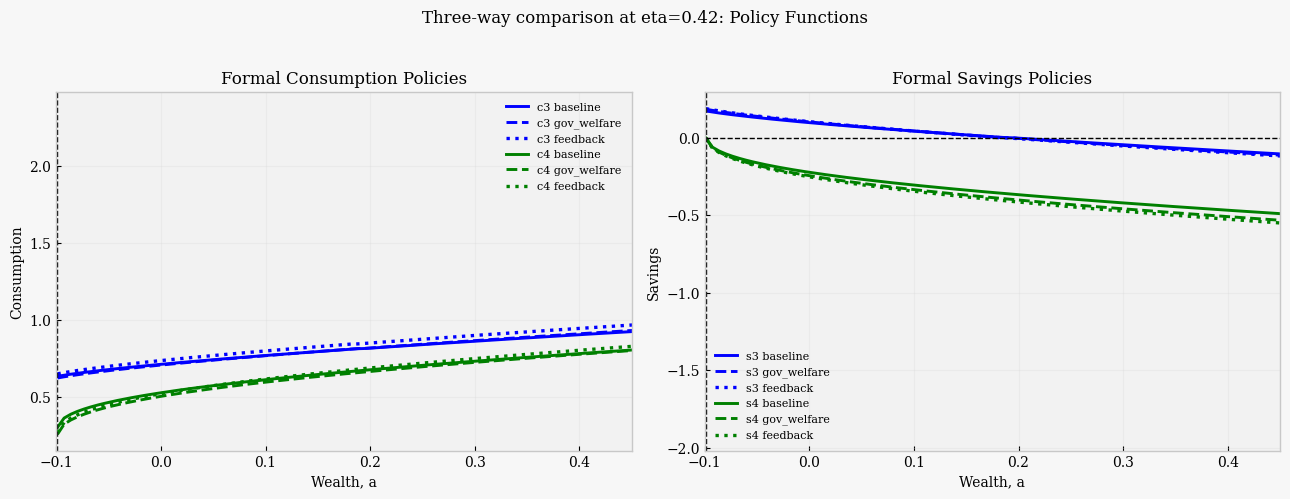

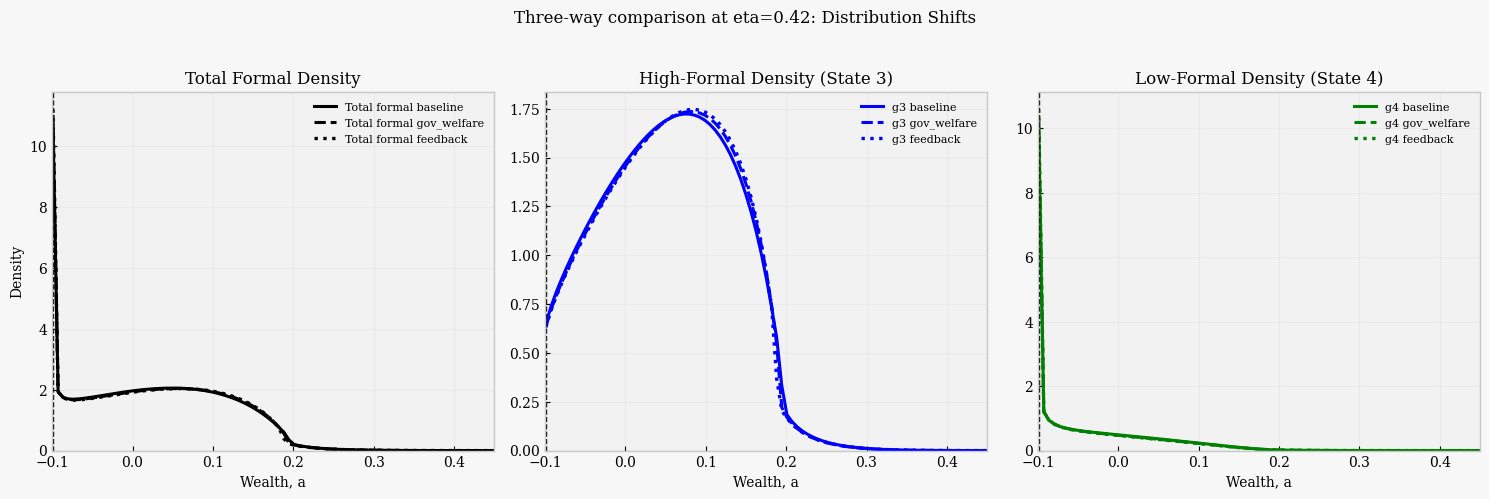

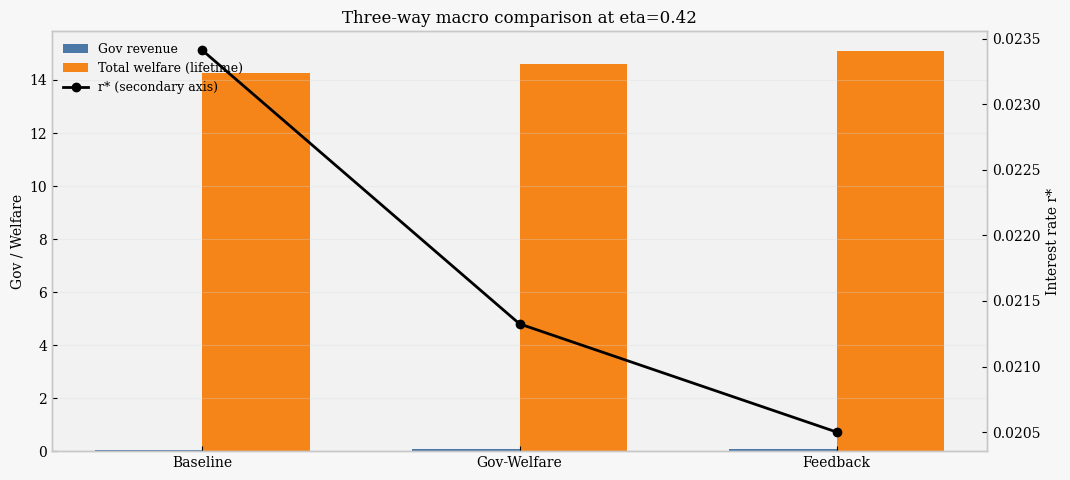


Detailed three-way comparison table (both eta values)
     eta      variable  baseline  gov_welfare  feedback  delta_gw  delta_fb     pct_gw     pct_fb
0.200000            r*  0.027404     0.024597  0.023741 -0.002807 -0.003662 -10.243307 -13.364263
0.200000           Gov  0.063414     0.100405  0.105712  0.036991  0.042298  58.333333  66.702200
0.200000 Total welfare 16.174932    16.659509 17.418812  0.484577  1.243879   2.995850   7.690168
0.200000   Formal mass  0.800000     0.800000  0.800000  0.000000 -0.000000   0.000000  -0.000000
0.200000 Informal mass  0.200000     0.200000  0.200000 -0.000000  0.000000  -0.000000   0.000000
0.420000            r*  0.023410     0.021325  0.020500 -0.002085 -0.002910  -8.906531 -12.429149
0.420000           Gov  0.045975     0.072794  0.075543  0.026819  0.029568  58.333333  64.313830
0.420000 Total welfare 14.253852    14.607533 15.081548  0.353681  0.827696   2.481301   5.806824
0.420000   Formal mass  0.580000     0.580000  0.580000  0.0000

In [51]:
# ---- Visualize: baseline vs gov_welfare vs government-feedback ----

eta_focus = eta_arg
a_plot = base_params["a"]
amin_plot = base_params["amin"]

base = res_policy_base[eta_focus]
govw = res_policy_gov_welfare[eta_focus]
feed = res_policy_feedback[eta_focus]

# Shorthands
c_b, s_b, g_b = base.c, base.adot, base.g
c_gw, s_gw, g_gw = govw.c, govw.adot, govw.g
c_fb, s_fb, g_fb = feed.c, feed.adot, feed.g

# 1) Policy functions for formal states (3 and 4): 3-way comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

ax = axes[0]
ax.plot(a_plot, c_b[:, 2], color="blue", linestyle="-", linewidth=2.1, label="c3 baseline")
ax.plot(a_plot, c_gw[:, 2], color="blue", linestyle="--", linewidth=2.1, label="c3 gov_welfare")
ax.plot(a_plot, c_fb[:, 2], color="blue", linestyle=":", linewidth=2.4, label="c3 feedback")
ax.plot(a_plot, c_b[:, 3], color="green", linestyle="-", linewidth=2.1, label="c4 baseline")
ax.plot(a_plot, c_gw[:, 3], color="green", linestyle="--", linewidth=2.1, label="c4 gov_welfare")
ax.plot(a_plot, c_fb[:, 3], color="green", linestyle=":", linewidth=2.4, label="c4 feedback")
ax.axvline(x=amin_plot, color="black", linestyle="--", linewidth=1)
ax.set_xlim([-0.1, 0.45])
ax.set_xlabel("Wealth, a")
ax.set_ylabel("Consumption")
ax.set_title("Formal Consumption Policies")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

ax = axes[1]
ax.plot(a_plot, s_b[:, 2], color="blue", linestyle="-", linewidth=2.1, label="s3 baseline")
ax.plot(a_plot, s_gw[:, 2], color="blue", linestyle="--", linewidth=2.1, label="s3 gov_welfare")
ax.plot(a_plot, s_fb[:, 2], color="blue", linestyle=":", linewidth=2.4, label="s3 feedback")
ax.plot(a_plot, s_b[:, 3], color="green", linestyle="-", linewidth=2.1, label="s4 baseline")
ax.plot(a_plot, s_gw[:, 3], color="green", linestyle="--", linewidth=2.1, label="s4 gov_welfare")
ax.plot(a_plot, s_fb[:, 3], color="green", linestyle=":", linewidth=2.4, label="s4 feedback")
ax.axhline(y=0, color="black", linestyle="--", linewidth=1)
ax.axvline(x=amin_plot, color="black", linestyle="--", linewidth=1)
ax.set_xlim([-0.1, 0.45])
ax.set_xlabel("Wealth, a")
ax.set_ylabel("Savings")
ax.set_title("Formal Savings Policies")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

fig.suptitle(f"Three-way comparison at eta={eta_focus:.2f}: Policy Functions", y=1.03)
plt.tight_layout()
plt.show()

# 2) Distribution shifts in formal states: 3-way comparison
gfor_b = g_b[:, 2] + g_b[:, 3]
gfor_gw = g_gw[:, 2] + g_gw[:, 3]
gfor_fb = g_fb[:, 2] + g_fb[:, 3]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

axes[0].plot(a_plot, gfor_b, color="black", linewidth=2.2, linestyle="-", label="Total formal baseline")
axes[0].plot(a_plot, gfor_gw, color="black", linewidth=2.2, linestyle="--", label="Total formal gov_welfare")
axes[0].plot(a_plot, gfor_fb, color="black", linewidth=2.4, linestyle=":", label="Total formal feedback")
axes[0].axvline(x=amin_plot, color="black", linestyle="--", linewidth=1)
axes[0].set_xlim([-0.1, 0.45])
axes[0].set_ylim(bottom=0)
axes[0].set_title("Total Formal Density")
axes[0].set_xlabel("Wealth, a")
axes[0].set_ylabel("Density")
axes[0].grid(alpha=0.3)
axes[0].legend(fontsize=8)

axes[1].plot(a_plot, g_b[:, 2], color="blue", linewidth=2.2, linestyle="-", label="g3 baseline")
axes[1].plot(a_plot, g_gw[:, 2], color="blue", linewidth=2.2, linestyle="--", label="g3 gov_welfare")
axes[1].plot(a_plot, g_fb[:, 2], color="blue", linewidth=2.4, linestyle=":", label="g3 feedback")
axes[1].axvline(x=amin_plot, color="black", linestyle="--", linewidth=1)
axes[1].set_xlim([-0.1, 0.45])
axes[1].set_ylim(bottom=0)
axes[1].set_title("High-Formal Density (State 3)")
axes[1].set_xlabel("Wealth, a")
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

axes[2].plot(a_plot, g_b[:, 3], color="green", linewidth=2.2, linestyle="-", label="g4 baseline")
axes[2].plot(a_plot, g_gw[:, 3], color="green", linewidth=2.2, linestyle="--", label="g4 gov_welfare")
axes[2].plot(a_plot, g_fb[:, 3], color="green", linewidth=2.4, linestyle=":", label="g4 feedback")
axes[2].axvline(x=amin_plot, color="black", linestyle="--", linewidth=1)
axes[2].set_xlim([-0.1, 0.45])
axes[2].set_ylim(bottom=0)
axes[2].set_title("Low-Formal Density (State 4)")
axes[2].set_xlabel("Wealth, a")
axes[2].grid(alpha=0.3)
axes[2].legend(fontsize=8)

fig.suptitle(f"Three-way comparison at eta={eta_focus:.2f}: Distribution Shifts", y=1.03)
plt.tight_layout()
plt.show()

# 3) Macro outcomes with secondary y-axis for interest rate
scenarios = ["Baseline", "Gov-Welfare", "Feedback"]
gov_levels = np.array([base.stats["gov"], govw.stats["gov"], feed.stats["gov"]], dtype=float)
wel_levels = np.array([base.stats["total_lifetime"], govw.stats["total_lifetime"], feed.stats["total_lifetime"]], dtype=float)
r_levels = np.array([base.r_star, govw.r_star, feed.r_star], dtype=float)

x = np.arange(len(scenarios))
w = 0.34

fig, ax1 = plt.subplots(figsize=(10.8, 4.9))
bars_gov = ax1.bar(x - w/2, gov_levels, width=w, color="#4c78a8", label="Gov revenue")
bars_wel = ax1.bar(x + w/2, wel_levels, width=w, color="#f58518", label="Total welfare (lifetime)")
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios)
ax1.set_ylabel("Gov / Welfare")
ax1.grid(axis="y", alpha=0.3)

ax2 = ax1.twinx()
line_r, = ax2.plot(x, r_levels, color="black", marker="o", linewidth=2.0, label="r* (secondary axis)")
ax2.set_ylabel("Interest rate r*")

handles = [bars_gov, bars_wel, line_r]
labels = ["Gov revenue", "Total welfare (lifetime)", "r* (secondary axis)"]
ax1.legend(handles, labels, loc="upper left", fontsize=9)
plt.title(f"Three-way macro comparison at eta={eta_focus:.2f}")
plt.tight_layout()
plt.show()

# 4) Detailed table with level and percent changes (vs baseline)
rows_cmp = []
for eta in etas_reform:
    b = res_policy_base[eta]
    gw = res_policy_gov_welfare[eta]
    fb = res_policy_feedback[eta]

    items = {
        "r*": (b.r_star, gw.r_star, fb.r_star),
        "Gov": (b.stats["gov"], gw.stats["gov"], fb.stats["gov"]),
        "Total welfare": (b.stats["total_lifetime"], gw.stats["total_lifetime"], fb.stats["total_lifetime"]),
        "Formal mass": (b.stats["mass_for"], gw.stats["mass_for"], fb.stats["mass_for"]),
        "Informal mass": (b.stats["mass_inf"], gw.stats["mass_inf"], fb.stats["mass_inf"]),
    }

    for var_name, (vb, vgw, vfb) in items.items():
        rows_cmp.append({
            "eta": float(eta),
            "variable": var_name,
            "baseline": vb,
            "gov_welfare": vgw,
            "feedback": vfb,
            "delta_gw": vgw - vb,
            "delta_fb": vfb - vb,
            "pct_gw": 100.0 * (vgw - vb) / max(abs(vb), 1e-12),
            "pct_fb": 100.0 * (vfb - vb) / max(abs(vb), 1e-12),
        })

df_policy_cmp_detailed = pd.DataFrame(rows_cmp)
print("\nDetailed three-way comparison table (both eta values)")
print(df_policy_cmp_detailed.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# A different Reform

## End-of-notebook policy comparison: monotributo logic and reform sequences

The reform sequence below is intended to match the policy discussion more closely.

The model is still a Markov transition system, so the cleanest way to interpret the reform is through how policy changes the transition environment and the long-run stationary distribution.

Here the three cases are:

1. 2024 monotributo baseline: the observed formal tax wedge remains in place, with lower formal taxed at `tau_arg_ms` and higher formal taxed at `tau_arg`.
2. Simplified-tax reform: both formal states pay the same lower simplified tax, so the formal sector is unified in the flow tax schedule.
3. Formalization-response reform: the simplified tax is combined with a policy response in `Lambda`, so moving out of informality becomes easier when the tax system is simplified.

This separation is useful because the first reform isolates the current system, the second isolates the tax unification idea, and the third adds the behavioral channel that is most likely to generate visible distributional effects.

If the simplified tax alone does not move the distribution much, that is not necessarily a problem. In this class of model, the main adjustment often occurs through state transitions rather than within-state consumption or savings. The policy-responsive `Lambda` case is therefore the relevant stress test for whether the reform can actually shift mass out of informality.

The comparison below keeps all previous functions unchanged and reports the three policy cases side by side for both informality sizes.


3x3 MATRIX: model variant x equilibrium option
     eta         model           option       r*      gov  total_welfare  mass_informal  mass_formal  avg_consumption  avg_savings
0.200000 baseline_2024 find_equilibrium 0.027404 0.063414      16.174932       0.200000     0.800000         0.591189     0.000000
0.200000 lambda_change find_equilibrium 0.023637 0.058888      17.874724       0.108513     0.891487         0.675903     0.000000
0.200000    tax_reform find_equilibrium 0.022045 0.052845      16.907116       0.200000     0.800000         0.637317    -0.000000
0.200000 baseline_2024     gov_feedback 0.026928 0.065490      16.628970       0.200000     0.800000         0.610548    -0.000000
0.200000 lambda_change     gov_feedback 0.023144 0.060675      18.338532       0.108513     0.891487         0.696407     0.000000
0.200000    tax_reform     gov_feedback 0.021590 0.054279      17.299287       0.200000     0.800000         0.654613     0.000000
0.200000 baseline_2024      gov_wel

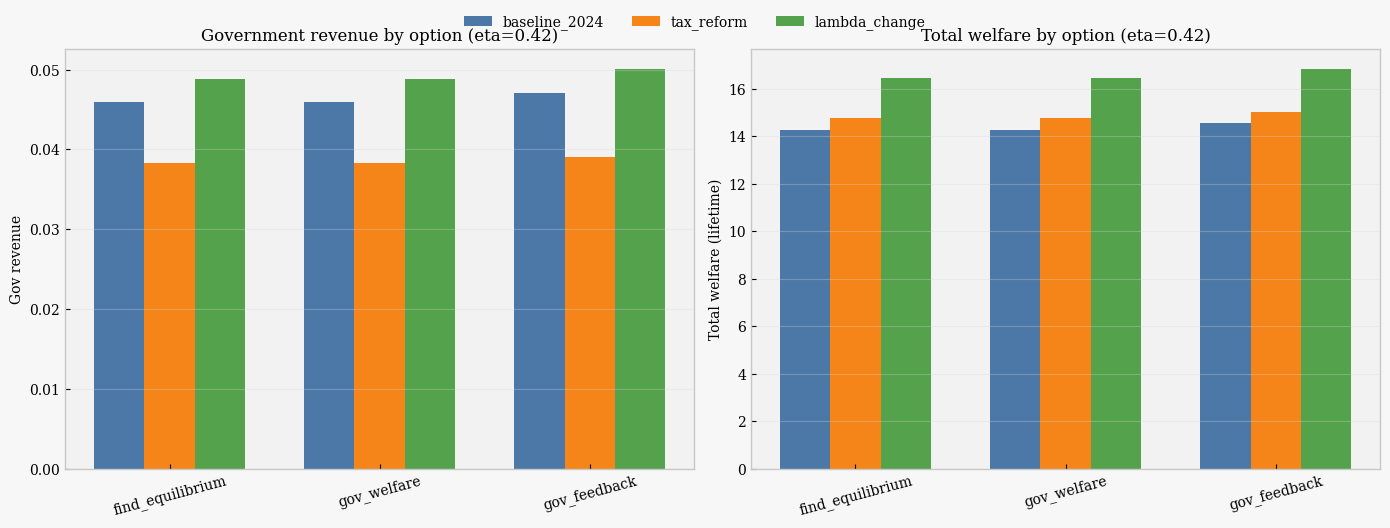

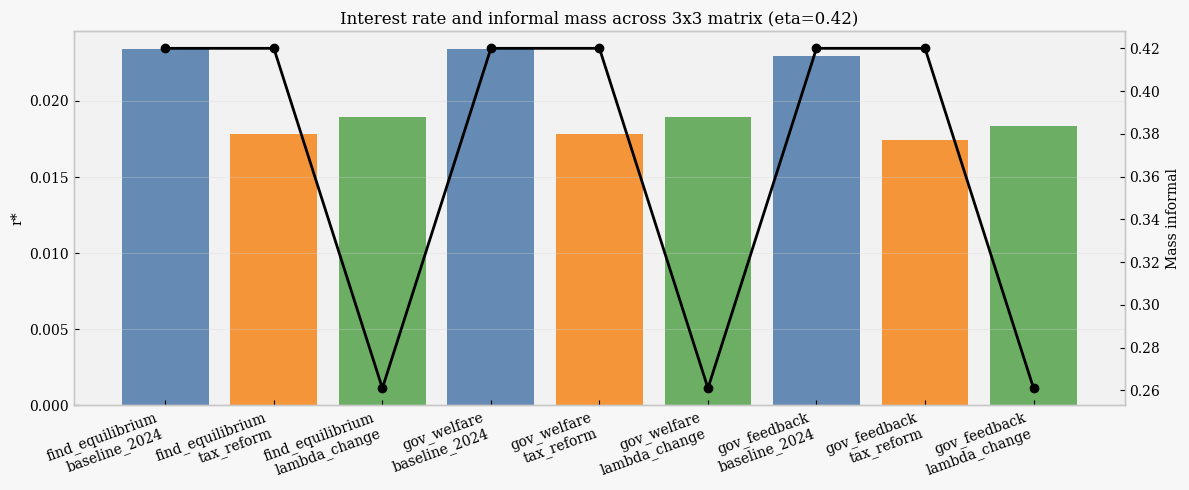

In [52]:
# ---- End-of-notebook 3x3 matrix: model variant x equilibrium option ----

# Goal:
# Compare changes across
# (A) model variants: baseline_2024, tax_reform, lambda_change
# and
# (B) equilibrium options: find_equilibrium, gov_welfare, gov_feedback

# -------------------------
# 1) Policy/model variants
# -------------------------

# Baseline 2024 monotributo-style wedge
# Informal untaxed; high-formal at tau_arg; low-formal at tau_arg_ms.
tau_baseline_2024 = np.array([0.00, 0.00, tau_arg, tau_arg_ms], dtype=float)

# Unified simplified formal tax (choose externally by setting tau_simplified beforehand)
tau_simplified = float(globals().get("tau_simplified", 0.10))
tau_reform_unified = np.array([0.00, 0.00, tau_simplified, tau_simplified], dtype=float)

# Lambda policy response helper (used only in lambda_change model)
def lambda_policy_response(Lambda_base, tau_drop, entry_boost=0.30, exit_reduction=0.20):
    """
    Policy-responsive Lambda:
    - increase informal -> formal intensities
    - decrease formal -> informal intensities
    - stronger effect when the formal tax drop is larger
    """
    L = np.array(Lambda_base, dtype=float).copy()

    # State order in notebook: 0=HI informal, 1=LI informal, 2=HI formal, 3=LI formal
    informal_to_formal = [(0, 2), (0, 3), (1, 2), (1, 3)]
    formal_to_informal = [(2, 0), (2, 1), (3, 0), (3, 1)]

    for i, j in informal_to_formal:
        L[i, j] *= (1.0 + entry_boost)
    for i, j in formal_to_informal:
        L[i, j] *= (1.0 - exit_reduction)

    tax_strength = min(1.0, max(0.0, tau_drop) / max(tau_arg, 1e-12))
    for i, j in informal_to_formal:
        L[i, j] *= (1.0 + 0.50 * tax_strength)

    np.fill_diagonal(L, 0.0)
    np.fill_diagonal(L, -L.sum(axis=1))
    return L


def weighted_average_from_density(policy_array, density_array, da):
    """Compute density-weighted cross-state average over the asset grid."""
    num = float((policy_array * density_array).sum() * da)
    den = float(density_array.sum() * da)
    if abs(den) < 1e-14:
        return np.nan
    return num / den


# Model variants (3)
model_variants = {
    "baseline_2024": {
        "tau": tau_baseline_2024,
        "lambda_mode": "base"
    },
    "tax_reform": {
        "tau": tau_reform_unified,
        "lambda_mode": "base"
    },
    "lambda_change": {
        "tau": tau_reform_unified,
        "lambda_mode": "policy_response"
    },
}

# -------------------------
# 2) Equilibrium options (3)
# -------------------------
# - find_equilibrium: fixed-z equilibrium
# - gov_welfare: same fixed-z equilibrium, evaluated with gov_and_welfare
# - gov_feedback: equilibrium with endogenous productivity feedback

eta_values = tuple(float(x) for x in etas_reform)
xi_feedback_matrix = float(globals().get("xi_feedback_matrix", xi_feedback if 'xi_feedback' in globals() else 0.50))
da_grid = float(base_params["da"])

rows_3x3 = []
results_3x3 = {}

for eta in eta_values:
    Lambda_eta_base = np.array(Lambda_dict[eta], dtype=float)
    results_3x3[eta] = {}

    for model_name, spec in model_variants.items():
        tau_vec = np.array(spec["tau"], dtype=float)
        if spec["lambda_mode"] == "base":
            Lambda_eta_use = Lambda_eta_base
        else:
            tau_drop = max(0.0, float(tau_arg - tau_vec[2]))
            Lambda_eta_use = lambda_policy_response(Lambda_eta_base, tau_drop=tau_drop, entry_boost=0.30, exit_reduction=0.20)

        results_3x3[eta][model_name] = {}

        # (i) find_equilibrium option
        r_fe, V_fe, c_fe, A_fe, g_fe, adot_fe, _ = find_equilibrium(
            eta=eta,
            params=base_params,
            gamma_vec=gamma_reform,
            tau_vec=tau_vec,
            theta_vec=theta_reform,
            Lambda=Lambda_eta_use,
            verbose=False,
        )
        out_fe = SimpleNamespace(r_star=r_fe, V=V_fe, c=c_fe, A=A_fe, g=g_fe, adot=adot_fe)
        stats_fe = gov_and_welfare_from_result(out_fe, base_params, gamma_reform, tau_vec)
        out_fe.stats = stats_fe
        results_3x3[eta][model_name]["find_equilibrium"] = out_fe

        avg_c_fe = weighted_average_from_density(out_fe.c, out_fe.g, da_grid)
        avg_s_fe = weighted_average_from_density(out_fe.adot, out_fe.g, da_grid)

        rows_3x3.append({
            "eta": eta,
            "model": model_name,
            "option": "find_equilibrium",
            "r*": float(out_fe.r_star),
            "gov": float(stats_fe["gov"]),
            "total_welfare": float(stats_fe["total_lifetime"]),
            "mass_informal": float(stats_fe["mass_inf"]),
            "mass_formal": float(stats_fe["mass_for"]),
            "avg_consumption": float(avg_c_fe),
            "avg_savings": float(avg_s_fe),
        })

        # (ii) gov_welfare option (same equilibrium object, fiscal/welfare lens)
        # Keep explicit row so table is a full 3x3 matrix by design.
        rows_3x3.append({
            "eta": eta,
            "model": model_name,
            "option": "gov_welfare",
            "r*": float(out_fe.r_star),
            "gov": float(stats_fe["gov"]),
            "total_welfare": float(stats_fe["total_lifetime"]),
            "mass_informal": float(stats_fe["mass_inf"]),
            "mass_formal": float(stats_fe["mass_for"]),
            "avg_consumption": float(avg_c_fe),
            "avg_savings": float(avg_s_fe),
        })

        # (iii) gov_feedback option
        out_fb_dict = find_equilibrium_with_gov_feedback(
            eta=eta,
            params=base_params,
            gamma_vec=gamma_reform,
            tau_vec=tau_vec,
            theta_vec=theta_reform,
            Lambda=Lambda_eta_use,
            xi=xi_feedback_matrix,
            verbose=False,
        )
        out_fb = SimpleNamespace(
            r_star=out_fb_dict["r_star"],
            V=out_fb_dict["V"],
            c=out_fb_dict["c"],
            A=out_fb_dict["A"],
            g=out_fb_dict["g"],
            adot=out_fb_dict["adot"],
            z_eff=out_fb_dict["z_eff"],
            gov_star=out_fb_dict["gov_star"],
            xi=out_fb_dict["xi"],
        )
        stats_fb = gov_and_welfare_from_result(out_fb, {**base_params, "z": out_fb.z_eff}, gamma_reform, tau_vec)
        out_fb.stats = stats_fb
        results_3x3[eta][model_name]["gov_feedback"] = out_fb

        avg_c_fb = weighted_average_from_density(out_fb.c, out_fb.g, da_grid)
        avg_s_fb = weighted_average_from_density(out_fb.adot, out_fb.g, da_grid)

        rows_3x3.append({
            "eta": eta,
            "model": model_name,
            "option": "gov_feedback",
            "r*": float(out_fb.r_star),
            "gov": float(stats_fb["gov"]),
            "total_welfare": float(stats_fb["total_lifetime"]),
            "mass_informal": float(stats_fb["mass_inf"]),
            "mass_formal": float(stats_fb["mass_for"]),
            "avg_consumption": float(avg_c_fb),
            "avg_savings": float(avg_s_fb),
        })

# -------------------------------------
# 3) Main table + percent-change table
# -------------------------------------

df_3x3 = pd.DataFrame(rows_3x3).sort_values(["eta", "option", "model"]).reset_index(drop=True)
print("\n3x3 MATRIX: model variant x equilibrium option")
print(df_3x3.to_string(index=False, float_format=lambda x: f"{x:.6f}"))

# Percent changes relative to baseline_2024, within each (eta, option)
rows_pct = []
for eta in eta_values:
    for opt in ["find_equilibrium", "gov_welfare", "gov_feedback"]:
        sub = df_3x3[(df_3x3["eta"] == eta) & (df_3x3["option"] == opt)]
        base_row = sub[sub["model"] == "baseline_2024"].iloc[0]
        for _, row in sub.iterrows():
            rows_pct.append({
                "eta": eta,
                "option": opt,
                "model": row["model"],
                "pct_r*": 100.0 * (row["r*"] - base_row["r*"]) / max(abs(base_row["r*"]), 1e-12),
                "pct_gov": 100.0 * (row["gov"] - base_row["gov"]) / max(abs(base_row["gov"]), 1e-12),
                "pct_total_welfare": 100.0 * (row["total_welfare"] - base_row["total_welfare"]) / max(abs(base_row["total_welfare"]), 1e-12),
                "pct_mass_informal": 100.0 * (row["mass_informal"] - base_row["mass_informal"]) / max(abs(base_row["mass_informal"]), 1e-12),
                "pct_avg_consumption": 100.0 * (row["avg_consumption"] - base_row["avg_consumption"]) / max(abs(base_row["avg_consumption"]), 1e-12),
                "pct_avg_savings": 100.0 * (row["avg_savings"] - base_row["avg_savings"]) / max(abs(base_row["avg_savings"]), 1e-12),
            })

df_3x3_pct = pd.DataFrame(rows_pct).sort_values(["eta", "option", "model"]).reset_index(drop=True)
print("\nPercent changes vs baseline_2024 within each (eta, option)")
print(df_3x3_pct.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# -------------------------
# 4) Informative graphs
# -------------------------

eta_focus = float(eta_arg)
plot_df = df_3x3[df_3x3["eta"] == eta_focus].copy()
if len(plot_df) > 0:
    options_order = ["find_equilibrium", "gov_welfare", "gov_feedback"]
    models_order = ["baseline_2024", "tax_reform", "lambda_change"]
    colors = {
        "baseline_2024": "#4c78a8",
        "tax_reform": "#f58518",
        "lambda_change": "#54a24b",
    }

    # Graph 1: Gov and welfare bars by option, grouped by model
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
    width = 0.24
    x = np.arange(len(options_order))

    for i, m in enumerate(models_order):
        y_gov = [plot_df[(plot_df["option"] == o) & (plot_df["model"] == m)]["gov"].iloc[0] for o in options_order]
        y_wel = [plot_df[(plot_df["option"] == o) & (plot_df["model"] == m)]["total_welfare"].iloc[0] for o in options_order]
        axes[0].bar(x + (i-1)*width, y_gov, width=width, color=colors[m], label=m)
        axes[1].bar(x + (i-1)*width, y_wel, width=width, color=colors[m], label=m)

    axes[0].set_title(f"Government revenue by option (eta={eta_focus:.2f})")
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(options_order, rotation=15)
    axes[0].set_ylabel("Gov revenue")
    axes[0].grid(axis="y", alpha=0.3)

    axes[1].set_title(f"Total welfare by option (eta={eta_focus:.2f})")
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(options_order, rotation=15)
    axes[1].set_ylabel("Total welfare (lifetime)")
    axes[1].grid(axis="y", alpha=0.3)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.02))
    plt.tight_layout()
    plt.show()

    # Graph 2: r* with secondary line of informal mass by option/model
    fig, ax1 = plt.subplots(figsize=(12, 5.0))
    xpos = np.arange(len(options_order) * len(models_order))
    xticklabels = []
    r_vals = []
    inf_vals = []
    bar_colors = []

    for o in options_order:
        for m in models_order:
            row = plot_df[(plot_df["option"] == o) & (plot_df["model"] == m)].iloc[0]
            xticklabels.append(f"{o}\n{m}")
            r_vals.append(row["r*"])
            inf_vals.append(row["mass_informal"])
            bar_colors.append(colors[m])

    ax1.bar(xpos, r_vals, color=bar_colors, alpha=0.85)
    ax1.set_xticks(xpos)
    ax1.set_xticklabels(xticklabels, rotation=20, ha="right")
    ax1.set_ylabel("r*")
    ax1.grid(axis="y", alpha=0.3)

    ax2 = ax1.twinx()
    ax2.plot(xpos, inf_vals, color="black", marker="o", linewidth=2.0)
    ax2.set_ylabel("Mass informal")

    plt.title(f"Interest rate and informal mass across 3x3 matrix (eta={eta_focus:.2f})")
    plt.tight_layout()
    plt.show()

# Optional friendly alias for downstream use
df_compare_three = df_3x3

# Effects with lump sum rebate

In [53]:
# ---- A/B/C effects with lump-sum rebate (4-state version) ----
import numpy as np
import pandas as pd

required = ["results_3x3", "df_3x3", "eta_values", "base_params", "gamma_reform", "u"]
missing = [k for k in required if k not in globals()]
if missing:
    raise RuntimeError(f"Missing required objects for 4-state rebate analysis: {missing}. Run the 3x3 reform block first.")

def welfare_with_lump_rebate(out_obj, base_params, gamma_vec):
    """Compute welfare with lump-sum rebate applied uniformly (4-state version)."""
    c = np.array(out_obj.c, dtype=float)
    g = np.array(out_obj.g, dtype=float)
    stats = out_obj.stats
    
    total_mass = stats["mass_inf"] + stats["mass_for"]
    T = float(stats["gov"] / total_mass) if total_mass > 0 else 0.0
    c_reb = c + T
    
    util_reb = u(c_reb, np.array(gamma_vec, dtype=float))
    private_flow_reb = sum(util_reb[:, s] @ g[:, s] for s in range(4)) * base_params["da"]
    total_flow_reb = private_flow_reb
    lifetime_reb = total_flow_reb / base_params["rho"]
    
    return {"T": T, "private_flow_reb": private_flow_reb, "total_flow_reb": total_flow_reb, "lifetime_reb": lifetime_reb}

rebate_rows = []
for eta in eta_values:
    welfare_A = welfare_with_lump_rebate(results_3x3[eta]["baseline_2024"]["find_equilibrium"], base_params, gamma_reform) if eta in results_3x3 else None
    welfare_B = welfare_with_lump_rebate(results_3x3[eta]["tax_reform"]["find_equilibrium"], base_params, gamma_reform) if eta in results_3x3 else None
    welfare_C = welfare_with_lump_rebate(results_3x3[eta]["lambda_change"]["find_equilibrium"], base_params, gamma_reform) if eta in results_3x3 else None
    
    rebate_rows.append({
        "eta": eta,
        "Transfer per capita (A)": welfare_A["T"] if welfare_A else np.nan,
        "Transfer per capita (B)": welfare_B["T"] if welfare_B else np.nan,
        "Transfer per capita (C)": welfare_C["T"] if welfare_C else np.nan,
        "Welfare (A) rebate": welfare_A["lifetime_reb"] if welfare_A else np.nan,
        "Welfare (B) rebate": welfare_B["lifetime_reb"] if welfare_B else np.nan,
        "Welfare (C) rebate": welfare_C["lifetime_reb"] if welfare_C else np.nan,
        "Effect A-B": welfare_B["lifetime_reb"] - welfare_A["lifetime_reb"] if (welfare_A and welfare_B) else np.nan,
        "Effect A-C": welfare_C["lifetime_reb"] - welfare_A["lifetime_reb"] if (welfare_A and welfare_C) else np.nan,
    })

df_4state_rebate = pd.DataFrame(rebate_rows)
print("\n=== 4-State A/B/C with Lump-Sum Rebate ===")
print(df_4state_rebate.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user("4-state reform with lump-sum rebate (A/B/C)", df_4state_rebate)
except Exception:
    pass


=== 4-State A/B/C with Lump-Sum Rebate ===
  eta  Transfer per capita (A)  Transfer per capita (B)  Transfer per capita (C)  Welfare (A) rebate  Welfare (B) rebate  Welfare (C) rebate  Effect A-B  Effect A-C
  0.2              0.063413719              0.052844766              0.058888011           16.286965           16.994272           17.956703   0.7073074   1.6697385
 0.42              0.045974946              0.038312455              0.048813572           14.358743           14.873658           16.555979  0.51491445   2.1972358


# Effects with gov feedback

In [54]:
# ---- A/B/C effects with government feedback (4-state version) ----
import numpy as np
import pandas as pd

feedback_rows = []
for eta in eta_values:
    if eta not in results_3x3:
        continue
    
    out_A = results_3x3[eta]["baseline_2024"].get("gov_feedback")
    out_B = results_3x3[eta]["tax_reform"].get("gov_feedback")
    out_C = results_3x3[eta]["lambda_change"].get("gov_feedback")
    
    if not out_A:
        continue
    
    wA = out_A.stats["total_lifetime"]
    wB = out_B.stats["total_lifetime"] if out_B else np.nan
    wC = out_C.stats["total_lifetime"] if out_C else np.nan
    
    feedback_rows.append({
        "eta": eta,
        "xi": out_A.xi if hasattr(out_A, 'xi') else np.nan,
        "Welfare A (fb)": wA,
        "Welfare B (fb)": wB,
        "Welfare C (fb)": wC,
        "Effect A-B (fb)": wB - wA if not np.isnan(wB) else np.nan,
        "Effect A-C (fb)": wC - wA if not np.isnan(wC) else np.nan,
    })

df_4state_fb = pd.DataFrame(feedback_rows)
print("\n=== 4-State A/B/C with Gov Feedback ===")
print(df_4state_fb.to_string(index=False, float_format=lambda x: f"{x: .8g}"))

try:
    from caas_jupyter_tools import display_dataframe_to_user
    display_dataframe_to_user("4-state A/B/C effects with gov feedback", df_4state_fb)
except Exception:
    pass


=== 4-State A/B/C with Gov Feedback ===
  eta   xi  Welfare A (fb)  Welfare B (fb)  Welfare C (fb)  Effect A-B (fb)  Effect A-C (fb)
  0.2  0.5        16.62897       17.299287       18.338532       0.67031677        1.7095621
 0.42  0.5       14.540536       15.035858       16.823383        0.4953217         2.282847


# Export data

In [55]:
# ---- Export r* summary for A/B/C across exogenous gov, lump-sum rebate, and gov feedback ----
from pathlib import Path
import numpy as np
import pandas as pd


def _find_project_root(start: Path) -> Path:
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "1. data").exists() and (p / "2. code").exists():
            return p
    return start


if "results_3x3" not in globals() or not isinstance(results_3x3, dict):
    raise RuntimeError("results_3x3 is missing. Run the 3x3 equilibrium block first.")

if "eta_values" not in globals():
    raise RuntimeError("eta_values is missing. Run the 3x3 equilibrium block first.")

requested_etas = {0.20, 0.42}
model_order = ["baseline_2024", "tax_reform", "lambda_change"]

rows = []
for eta in eta_values:
    eta_val = float(eta)
    if round(eta_val, 2) not in requested_etas:
        continue
    if eta_val not in results_3x3:
        continue

    for model_name in model_order:
        if model_name not in results_3x3[eta_val]:
            continue

        # Exogenous government: direct equilibrium solve
        if "find_equilibrium" in results_3x3[eta_val][model_name]:
            out = results_3x3[eta_val][model_name]["find_equilibrium"]
            stats = getattr(out, "stats", {}) or {}
            rows.append({
                "approach": "exogenous",
                "option": "find_equilibrium",
                "Case": model_name,
                "eta": eta_val,
                "r_star": float(getattr(out, "r_star", np.nan)),
                "gov": float(stats.get("gov", np.nan)),
                "total_welfare": float(stats.get("total_lifetime", np.nan)),
            })

        # Gov feedback: direct equilibrium solve with feedback
        if "gov_feedback" in results_3x3[eta_val][model_name]:
            out = results_3x3[eta_val][model_name]["gov_feedback"]
            stats = getattr(out, "stats", {}) or {}
            rows.append({
                "approach": "gov_feedback",
                "option": "gov_feedback",
                "Case": model_name,
                "eta": eta_val,
                "r_star": float(getattr(out, "r_star", np.nan)),
                "gov": float(stats.get("gov", np.nan)),
                "total_welfare": float(stats.get("total_lifetime", np.nan)),
            })

# Lump-sum rebate: same equilibrium r* as the baseline solve, but pair it with the rebate welfare summary.
if "df_4state_rebate" in globals() and isinstance(df_4state_rebate, pd.DataFrame) and not df_4state_rebate.empty:
    rebate_eta_col = "eta" if "eta" in df_4state_rebate.columns else None
    rebate_lookup = {}
    if rebate_eta_col is not None:
        for _, row in df_4state_rebate.iterrows():
            rebate_lookup[round(float(row[rebate_eta_col]), 2)] = row.to_dict()

    if rebate_lookup:
        exog_rows = [r for r in rows if r["approach"] == "exogenous"]
        for r in exog_rows:
            eta_key = round(float(r["eta"]), 2)
            rebate_row = rebate_lookup.get(eta_key, {})
            case_name = r["Case"]
            welfare_col_map = {
                "baseline_2024": "Welfare (A) rebate",
                "tax_reform": "Welfare (B) rebate",
                "lambda_change": "Welfare (C) rebate",
            }
            gov_col_map = {
                "baseline_2024": "Transfer per capita (A)",
                "tax_reform": "Transfer per capita (B)",
                "lambda_change": "Transfer per capita (C)",
            }
            welfare_key = welfare_col_map.get(case_name)
            gov_key = gov_col_map.get(case_name)
            rows.append({
                "approach": "lump_sum_rebate",
                "option": "gov_welfare",
                "Case": case_name,
                "eta": float(r["eta"]),
                "r_star": float(r["r_star"]),
                "gov": float(rebate_row.get(gov_key, np.nan)) if gov_key else np.nan,
                "total_welfare": float(rebate_row.get(welfare_key, np.nan)) if welfare_key else np.nan,
            })

if len(rows) == 0:
    raise RuntimeError("No r* rows were found. Check that results_3x3 and the rebate summary exist.")

df_rstar_4state = pd.DataFrame(rows)
df_rstar_4state = df_rstar_4state[df_rstar_4state["eta"].round(2).isin(requested_etas)].copy()
df_rstar_4state = df_rstar_4state.sort_values(["approach", "eta", "Case"]).reset_index(drop=True)

project_root = _find_project_root(Path.cwd())
out_dir = project_root / "1. data" / "output_data"
out_dir.mkdir(parents=True, exist_ok=True)
out_file = out_dir / "reform4_ABC_rstar_exog_rebate_feedback.csv"
df_rstar_4state.to_csv(out_file, index=False)

print(f"Saved r* summary for exogenous gov / rebate / feedback to: {out_file}")
print(df_rstar_4state.to_string(index=False, float_format=lambda x: f'{x: .8g}'))

Saved r* summary for exogenous gov / rebate / feedback to: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\reform4_ABC_rstar_exog_rebate_feedback.csv
       approach           option          Case   eta       r_star          gov  total_welfare
      exogenous find_equilibrium baseline_2024   0.2  0.027403625  0.063413719      16.174932
      exogenous find_equilibrium lambda_change   0.2  0.023636902  0.058888011      17.874724
      exogenous find_equilibrium    tax_reform   0.2  0.022045227  0.052844766      16.907116
      exogenous find_equilibrium baseline_2024  0.42  0.023410034  0.045974946      14.253852
      exogenous find_equilibrium lambda_change  0.42  0.018930298  0.048813572      16.471516
      exogenous find_equilibrium    tax_reform  0.42  0.017853577  0.038312455        14.7896
   gov_feedback     gov_feedback baseline_2024   0.2  0.026928284  0.065490206       16.62897
   gov_feedback     gov_feedback lambda_change 

In [57]:
# ---- Export all Section 4.1+ results to one homogeneous CSV (long format) ----
from pathlib import Path
import pandas as pd
import numpy as np


def _find_project_root(start: Path) -> Path:
    """Find project root by looking for the top-level data/code folders."""
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "1. data").exists() and (p / "2. code").exists():
            return p
    return start


def _to_long_records(df: pd.DataFrame, source_name: str):
    """Convert any result table into tidy long records with common metadata columns."""
    out = []
    df_local = df.copy()

    # Keep original row identity so no information is lost after melt.
    df_local = df_local.reset_index().rename(columns={"index": "row_id"})

    id_cols = []
    preferred_ids = [
        "row_id", "Section", "section", "Metric", "metric", "State", "state",
        "eta", "model", "option", "Model", "variable"
    ]
    for c in preferred_ids:
        if c in df_local.columns and c not in id_cols:
            id_cols.append(c)

    value_cols = [c for c in df_local.columns if c not in id_cols]
    if len(value_cols) == 0:
        return out

    long_df = df_local.melt(
        id_vars=id_cols,
        value_vars=value_cols,
        var_name="measure",
        value_name="value",
    )

    # Standardized metadata fields for future cross-model plotting.
    for _, r in long_df.iterrows():
        out.append({
            "source": source_name,
            "data_kind": "table",
            "section": r.get("Section", r.get("section", np.nan)),
            "metric": r.get("Metric", r.get("metric", r.get("variable", np.nan))),
            "state": r.get("State", r.get("state", np.nan)),
            "eta": r.get("eta", np.nan),
            "model": r.get("model", r.get("Model", np.nan)),
            "option": r.get("option", np.nan),
            "scenario": r.get("measure", np.nan),
            "grid_var": np.nan,
            "grid_index": np.nan,
            "grid_value": np.nan,
            "value": r.get("value", np.nan),
        })
    return out


def _append_policy_distribution_records(records, comparison_name, eta_value, a_grid, out_a, out_b):
    """Store plot-relevant policy/distribution objects as long records."""
    state_labels_local = ["HI Informal", "LI Informal", "HI Formal", "LI Formal"]

    arrays_to_export = [
        ("consumption", out_a.c, out_b.c),
        ("savings", out_a.adot, out_b.adot),
        ("density", out_a.g, out_b.g),
    ]

    for var_name, arr_a, arr_b in arrays_to_export:
        for j, st in enumerate(state_labels_local):
            for i in range(len(a_grid)):
                records.append({
                    "source": comparison_name,
                    "data_kind": "series",
                    "section": comparison_name,
                    "metric": var_name,
                    "state": st,
                    "eta": float(eta_value),
                    "model": np.nan,
                    "option": np.nan,
                    "scenario": "left",
                    "grid_var": "a",
                    "grid_index": i,
                    "grid_value": float(a_grid[i]),
                    "value": float(arr_a[i, j]),
                })
                records.append({
                    "source": comparison_name,
                    "data_kind": "series",
                    "section": comparison_name,
                    "metric": var_name,
                    "state": st,
                    "eta": float(eta_value),
                    "model": np.nan,
                    "option": np.nan,
                    "scenario": "right",
                    "grid_var": "a",
                    "grid_index": i,
                    "grid_value": float(a_grid[i]),
                    "value": float(arr_b[i, j]),
                })


all_records = []

# 1) Export all structured result tables already built from §4.1 onward.
result_table_names = [
    "df_41", "df_42", "df_43", "df_44", "df_all",
    "df_gov_welfare", "df_compare_41_44", "df_policy_gap_41_44", "df_welfare_41_44",
    "df_ext", "df_policy_cmp", "df_policy_cmp_detailed",
    "df_3x3", "df_3x3_pct", "df_compare_three",
]

for name in result_table_names:
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        all_records.extend(_to_long_records(globals()[name], source_name=name))

# 2) Export plot-series data for key comparisons used from §4.1 to the final 3x3 block.
if all(k in globals() for k in ["res_41", "res_42", "eta_arg", "base_params"]):
    _append_policy_distribution_records(
        all_records,
        comparison_name="comparison_4_1_vs_4_2",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_a=res_41[eta_arg],
        out_b=res_42[eta_arg],
    )

if all(k in globals() for k in ["res_42", "res_43", "eta_arg", "base_params"]):
    _append_policy_distribution_records(
        all_records,
        comparison_name="comparison_4_2_vs_4_3",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_a=res_42[eta_arg],
        out_b=res_43[eta_arg],
    )

if all(k in globals() for k in ["res_43", "res_44", "eta_arg", "base_params"]):
    _append_policy_distribution_records(
        all_records,
        comparison_name="comparison_4_3_vs_4_4",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_a=res_43[eta_arg],
        out_b=res_44[eta_arg],
    )

if all(k in globals() for k in ["res_41", "res_44", "eta_arg", "base_params"]):
    _append_policy_distribution_records(
        all_records,
        comparison_name="comparison_4_1_vs_4_4",
        eta_value=eta_arg,
        a_grid=base_params["a"],
        out_a=res_41[eta_arg],
        out_b=res_44[eta_arg],
    )

# 3) Export the final 3x3 matrix policy/distribution series for eta=eta_arg.
if all(k in globals() for k in ["results_3x3", "eta_arg", "base_params"]):
    eta_focus_export = float(eta_arg)
    if eta_focus_export in results_3x3:
        model_order = ["baseline_2024", "tax_reform", "lambda_change"]
        option_map = {
            "find_equilibrium": "find_equilibrium",
            "gov_welfare": "find_equilibrium",  # same equilibrium object, different lens
            "gov_feedback": "gov_feedback",
        }

        a_grid = base_params["a"]
        state_labels_local = ["HI Informal", "LI Informal", "HI Formal", "LI Formal"]

        for model_name in model_order:
            if model_name not in results_3x3[eta_focus_export]:
                continue
            for option_name, obj_key in option_map.items():
                if obj_key not in results_3x3[eta_focus_export][model_name]:
                    continue
                out_obj = results_3x3[eta_focus_export][model_name][obj_key]

                for metric_name, arr in [("consumption", out_obj.c), ("savings", out_obj.adot), ("density", out_obj.g)]:
                    for j, st in enumerate(state_labels_local):
                        for i in range(len(a_grid)):
                            all_records.append({
                                "source": "final_3x3_series",
                                "data_kind": "series",
                                "section": "final_3x3",
                                "metric": metric_name,
                                "state": st,
                                "eta": eta_focus_export,
                                "model": model_name,
                                "option": option_name,
                                "scenario": "level",
                                "grid_var": "a",
                                "grid_index": i,
                                "grid_value": float(a_grid[i]),
                                "value": float(arr[i, j]),
                            })

if len(all_records) == 0:
    raise RuntimeError("No result objects found to export. Run section 4.1 onward cells first.")

export_df = pd.DataFrame(all_records)

project_root = _find_project_root(Path.cwd())
out_dir = project_root / "1. data" / "output_data"
out_dir.mkdir(parents=True, exist_ok=True)
out_csv = out_dir / "equilibrium_4state_arg_all_results_long.csv"

export_df.to_csv(out_csv, index=False)

print(f"Exported unified long-format results to: {out_csv}")
print(f"Rows exported: {len(export_df):,}")
print("Columns:", list(export_df.columns))

Exported unified long-format results to: c:\Users\HP\OneDrive\Documentos\UChicago\4. Thesis\versions\1. argentinian tax\1. data\output_data\equilibrium_4state_arg_all_results_long.csv
Rows exported: 163,960
Columns: ['source', 'data_kind', 'section', 'metric', 'state', 'eta', 'model', 'option', 'scenario', 'grid_var', 'grid_index', 'grid_value', 'value']
